# Walkthrough: choose a process, choose a model, train or load it, look at the results

This notebook uses the files of this folder:

* `process.py` — every process and its analytical results;
* `training.py` — the shared training code;
* `causal_state_matrix.py` — the state table every model shares;
* `model_<name>.py` — one file per model;
* `analysis.py` — every measure and figure.

Sections 1–5 go through the steps once: choose a process, choose a model, train or load it, choose the plots. Section 6
then has one demonstration per model. Each one shows how well the model predicts on held-out data, how it converges
during training, and what machine it ends up with. The demonstrations use the trained runs of sections 13, 16 and 17 of
`model_modeularised/hybrid_model_test.ipynb`, copied into `runs/imported/` by `python main.py import-runs`. Nothing is
retrained here except a short example in section 4.

**Terms used throughout**
* **Excess CE.** A predictor's cross-entropy minus the true process's cross-entropy on the same tokens, in bits per
  token. 0 is perfect.
* **Test windows.** 4,096 fresh windows of 40 history + 20 future tokens that never affect training or any choice.
* **Seeds.** Each model has three runs (seeds 0, 1, 2), which differ in their starting weights and training windows.

## 1. Setup

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))          # run this notebook from test_models/

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

import process as P
import training as TR
import analysis as A
import main as MAIN

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
runs = MAIN.imported_runs()                  # {(model, label, seed): run folder}


def runs_of(model, label=None):
    # The imported runs of one model (all seeds; optionally one label such as 'section16' or 'w0.03').
    return {f"{m} {l} s{s}": f for (m, l, s), f in runs.items() if m == model and (label is None or l == label)}


def performance(r, which="latest"):
    # The test results of some runs: every predictor's excess CE on the 20 future tokens and over 200 future tokens,
    # true states with their own learned state, and the size of every step rule's machine.
    table = A.test_table(r, which)
    keep = ["seed", "weight", "update"] + [c for c in table if c.startswith("excess_") and c.endswith("_future")] \
        + [c for c in table if c.startswith("long_excess_")] + [c for c in table if c.endswith("_true_states_with_own_state")] \
        + [c for c in table if c.endswith("_long_run_states")] + [c for c in ("distance_D",) if c in table]
    return table[keep].set_index("seed").round(4)

## 2. Choose the process

`process.py` contains every process of the project (`PROCESS`), copied from `HMM_processes.py` and
`process_generator.py`. `P.Process(name, params)` turns one of them into an object:

* **The generating machine** (`T`, `E`, `M`): the probability of each token and next state from each state.
* **The long-run state distribution** `pi`.
* **A window sampler** (`sampler(seed)`): fresh windows, each started from `pi`, as in section 16.
* **The true next-token probabilities** of any window (`exact_probs`), used to compute every excess CE.
* **The analytical results** (`analytics()`):
  * the number of causal states;
  * the statistical complexity C_μ, the entropy of `pi`;
  * the entropy rate h;
  * the excess entropy E, how much the past tells about the future;
  * the crypticity χ = C_μ − E, the part of the state that no amount of future reveals (Mahoney, Ellison & Crutchfield 2009).
* **`is_epsilon_machine`**: whether the generating machine is its own ε-machine. When it is, the sampler's states are
  the true causal states, and the analyses that compare learned states with true ones can be used.

All demonstrations use renewal-15. After each 1, the number of 0s before the next 1 is equally likely to be any of 0–14.
Its 15 causal states are the counts of 0s since the last 1 (written a0 … a14; Marzen & Crutchfield 2015). To use another
process, give `process=` and `params=` to `TR.settings_for` (last line of the next cell).

processes: butterfly, coin, edges, even, explosive, flower, gm, iid, ising, nemo, pcoin, renewal, rgm, rip, rnc, sgm, sns, t3, tilt
renewal-15 | its own epsilon-machine: True


n_causal          15.0000
statistical_c      3.6706
entropy_rate       0.4884
excess_entropy     0.4342
crypticity         3.2363
dtype: float64

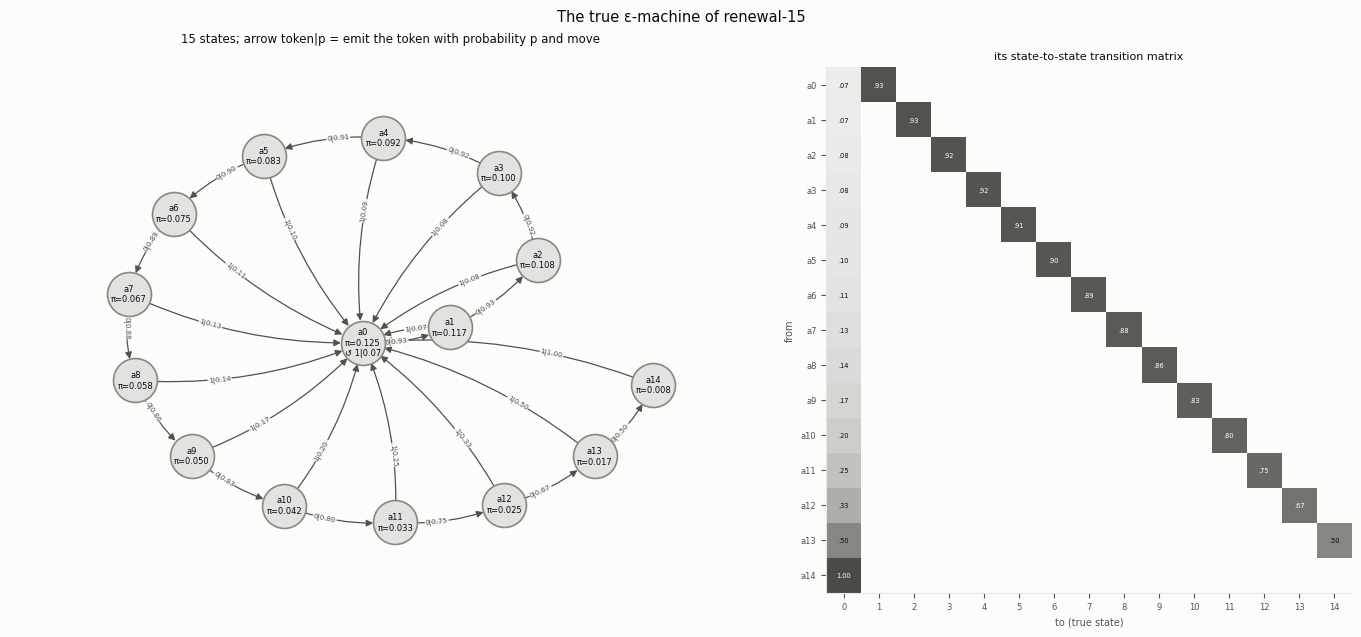

In [2]:
print("processes:", ", ".join(sorted(P.PROCESS)))
proc = P.Process("renewal", {"F": [1 / 15] * 15})
print(proc.label, "| its own epsilon-machine:", proc.is_epsilon_machine)
display(pd.Series({k: v for k, v in proc.analytics().items()
                   if k in ("n_causal", "statistical_c", "entropy_rate", "excess_entropy", "crypticity")}).round(4))
settings = TR.settings_for("2")              # section 16's settings for model 2, on renewal-15
fig = A.plot_true_machine(settings)
plt.show()
# another process, e.g.:  TR.settings_for("2", process="even", params={"p": 0.5})

## 3. Choose the model

Every model chooses its states from the same kind of table (`causal_state_matrix.py`): K = 32 learned state vectors and
one output layer that turns a state vector into next-token probabilities. A state is chosen from scores. During training
random noise is added and the highest noisy score is taken; at evaluation the highest score is taken.

The models differ in which parts choose the states and in what they are trained on.

| model | parts | loss | idea |
|---|---|---|---|
| 1 | Transformer + GRU | the GRU's predictions of the 20 future tokens | the starting point (sections 13 and 16) |
| 2 | Transformer + GRU | 1 + the Transformer's own next-token predictions | train the Transformer's state choice at every position |
| 3 | + next-state network | 2 + weight × (entropy + CE) of a network predicting the Transformer's next state | if the states follow a fixed rule, the network can learn it |
| 4 | Transformer + network | 3 without the GRU | can the network replace the GRU? |
| A | as 3 | 3, with the Transformer's next state a fixed target | stop the Transformer being pulled toward easy states |
| 5a | Transformer + GRU + two-step head | 1 + one- and two-step predictions + weight × entropy of the next state worked out from them | the predictions themselves say which state comes next |
| 5b | Transformer + two-step head | 5a without the GRU | as 4, for this way |
| C | + three-step head | 5b with the next state worked out from two predicted tokens | two tokens tell states apart better |
| B | Transformer + GRU | 1 + weight × CE of the Transformer's starting state against the GRU's own state after the history | the GRU continues from a state it would itself be in |
| 1_L2 | Transformer + GRU | 1 + weight × D over all future tokens | the notebook's L2 term (sections 13 and 15) |
| 2_L2 | Transformer + GRU | 2 + weight × D over the GRU's steps | section 17's L2 term |
| feedback_GRU | a GRU alone | its own next-token predictions | the GRU's state is a table row, fed back every step |
| discrete_Transformer | a Transformer alone | its own next-token predictions | a state choice at every position |

D is the distance between the Transformer's and the GRU's state probabilities after the same tokens: 0 when equal,
at most √2.

**The predictors** are what a model's predictions are measured on. They all use the same output layer and differ only
in how the state at each future position is chosen:

* **`transformer`**: at every position the Transformer reads all the real tokens so far and picks a state afresh. It
  never has to carry a state forward.
* **`gru_from_handoff`**: the Transformer picks one state after the 40 history tokens (the code calls it *the
  handoff*). From then on the GRU moves from state to state on each real token.
* **`next_state_from_handoff`**: the same, but each step is made by the next-state network (models 3, 4, A).
* **`gru_from_start`**: the feedback GRU alone reads every token of the window from a blank start.

A low error for `transformer` only shows that the Transformer can tell, from the whole history, which state to use. A
low error for a predictor that steps from state to state shows that the states and the step rule work together as a
machine (state + token → next state), as the ε-machine does.

The table below lists, for every model file, the analyses of `analysis.py` that apply to it. The module docstring of
`analysis.py` explains each one. To make a new model, copy `model_2.py` to `model_<name>.py` and change it. It then
appears here, and in `python main.py list`.

In [3]:
display(A.applicability())

,description,main predictor,"test results, learning curves, states over training",state tables (needs an epsilon-machine process),machine from a step rule,machine from the state sequence,extra-term curves,distance D,lock-in trace
model,,,,,,,,,
1,the GRU's future-token CE only,gru_from_handoff,yes,yes,gru_from_handoff,transformer,-,yes,yes
1_L2,1 + weight x D over all L steps (the notebook'...,gru_from_handoff,yes,yes,gru_from_handoff,transformer,yes,yes,yes
2,GRU's future-token CE + the Transformer's own ...,gru_from_handoff,yes,yes,gru_from_handoff,transformer,-,yes,yes
2_L2,2 + weight x D over the L - 1 GRU steps (secti...,gru_from_handoff,yes,yes,gru_from_handoff,transformer,yes,yes,yes
3,model 2 + a next-state network following the T...,gru_from_handoff,yes,yes,"gru_from_handoff, next_state_from_handoff",transformer,yes,yes,yes
4,model 3 without the GRU,transformer,yes,yes,next_state_from_handoff,transformer,yes,-,yes
5a,1 + one- and two-step CE + entropy of the next...,gru_from_handoff,yes,yes,gru_from_handoff,transformer,yes,yes,yes
5b,model 5a without the GRU,transformer,yes,yes,-,transformer,yes,-,yes
A,model 3 with the Transformer's next state as a...,gru_from_handoff,yes,yes,"gru_from_handoff, next_state_from_handoff",transformer,yes,yes,yes


## 4. Train a model, or load a trained one

`TR.settings_for(model, **changes)` builds a run's settings in three layers:
1. section 16's setup:
   * windows of 40 + 20 tokens;
   * 50,000 updates, batch 128, learning rate 0.001;
   * temperature 2.5 → 0.5, multiplied by the same factor at every update;
   * LayerNorm on the Transformer's output, AdamW weight decay 0.0005, gradient clipping at 1;
2. then the model file's `DEFAULTS` (e.g. the weight of its extra term);
3. then your changes.

`TR.train(settings)` trains and saves the run in `runs/model_<name>/<process>_w<weight>_n<steps>_s<seed>_<key>/`. A
finished run with the same settings and code is reloaded instead. The folder holds:
* `settings.json`;
* `completed.pt` (with the optimizer and random states);
* `best.pt` (the parameters with the best validation value);
* the training and validation histories.

Three more functions:
* `TR.extend(folder, n)` trains n more updates at the final temperature.
* `TR.train_until_settled` repeats `extend` by 25,000 while the main measure still improves, up to 100,000 updates
  (section 16's rule).
* `TR.load_run(folder)` reads a run back.

From a terminal: `python main.py train --model 2 --seed 0`.

The next cell trains model 2 for 300 updates, only to show the steps; that is far too few to learn the process.

In [4]:
example = TR.settings_for("2", steps=300, eval_every=100)
model, folder = TR.train(example, verbose=False)
print("saved in", folder.relative_to(Path.cwd()))
display(TR.history(folder)[["update", "tau", "excess_transformer_future", "excess_gru_from_handoff_future",
                            "transformer_states_used"]].round(4))

saved in runs/model_2/renewal-15_w0_n300_s0_83ef5ee6af


,update,tau,excess_transformer_future,excess_gru_from_handoff_future,transformer_states_used
0,0,2.5000,0.5788,0.5788,9
1,100,1.4673,0.0593,0.0604,1
2,200,0.8565,0.0527,0.0568,10
3,300,0.5000,0.0188,0.0548,4


The trained runs of sections 13, 16 and 17 are in `runs/imported/` (`MAIN.imported_runs()`):
* models 1–C: three seeds each, section 16;
* model 1 in the original setup: three seeds, section 16;
* model 2 + L2 at weights 0.01, 0.03 and 0.1, the feedback GRU and the discrete Transformer: three seeds each, section 17;
* model 1 + L2: one run, section 13.

Each was checked against the old code: the same settings, the same parameters, and the same test results
(`tests/test_equivalence.py`).

In [5]:
display(pd.DataFrame([dict(model=m, label=l, seed=s, update=TR.checkpoint(f)[1]) for (m, l, s), f in runs.items()])
        .pivot_table(index=["model", "label"], columns="seed", values="update"))

seed                                       0         1         2
model                label                                      
1                    original_setup  50000.0   50000.0   50000.0
                     section16       50000.0   50000.0   50000.0
1_L2                 section13       50000.0       NaN       NaN
2                    section16       75000.0   50000.0   75000.0
2_L2                 w0.01           50000.0   75000.0   75000.0
                     w0.03           50000.0   50000.0   50000.0
                     w0.1            50000.0   50000.0   50000.0
3                    section16       50000.0  100000.0   75000.0
4                    section16       50000.0   50000.0   50000.0
5a                   section16       50000.0   50000.0   75000.0
5b                   section16       50000.0   50000.0   50000.0
A                    section16       75000.0   50000.0   75000.0
B                    section16       50000.0  100000.0  100000.0
C                    section16       50000.0   50000.0   50000.0
discrete_Transformer section17       50000.0   50000.0   50000.0
feedback_GRU         section17       50000.0   50000.0   50000.0

## 5. Choose the plots

| function | shows | models |
|---|---|---|
| `A.plot_learning_curves(runs)` | the validation excess CE of every predictor over training, with the two reference levels | all |
| `A.plot_states_over_training(runs)` | states in use by each predictor, and the gap between the two highest state scores at the last history position (above about 10 the choice no longer changes in training) | all |
| `A.plot_extra_terms(runs)` | the model's extra measures over training: next-state entropy (3, 4, A), inferred-next-state entropy (5a, 5b, C), copy agreement (B), D (L2 models) | models with an extra term |
| `A.plot_test_summary(A.test_table(runs), levels)` | every predictor's test excess CE, per seed | all |
| `A.plot_token_probs_by_true_state(runs)` | each predictor's predicted P(next token = 1) at each true state, against the truth | all (true states needed) |
| `A.plot_state_tables(runs)` | which learned state each true state is sent to | all (true states needed) |
| `A.plot_machines(runs)` | the learning curves, and for each run the machine of its main predictor, its transition matrix on the true states, and the difference from the true matrix | all (true states needed) |
| `A.plot_machine_summary(A.machine_table(runs), levels)` | every run's machine size, true states covered, mean difference, test excess | all |
| `A.lock_in_trace(settings)` | the first updates of a run, measured after each (section 16.1) | hybrids |

**Reference levels.** Always predicting each token's long-run frequency is 0.0549 bits above exact on the test windows
("remembers nothing"). Predicting from the last token alone is 0.0513 ("last symbol only"). A predictor near these
levels does not use the count.

**How a machine is read off.**
* *From a step rule* (the GRU, the next-state network, the feedback GRU): every (state, token) pair is tried. The result
  is reduced to the states it keeps returning to from the model's states after the history, and identical states are
  merged. This is exact.
* *From a state sequence* (the Transformer): the machine is read off the states picked on 4,096 windows, keeping how
  often each next state follows. It need not be deterministic.

The overview of all imported runs follows.

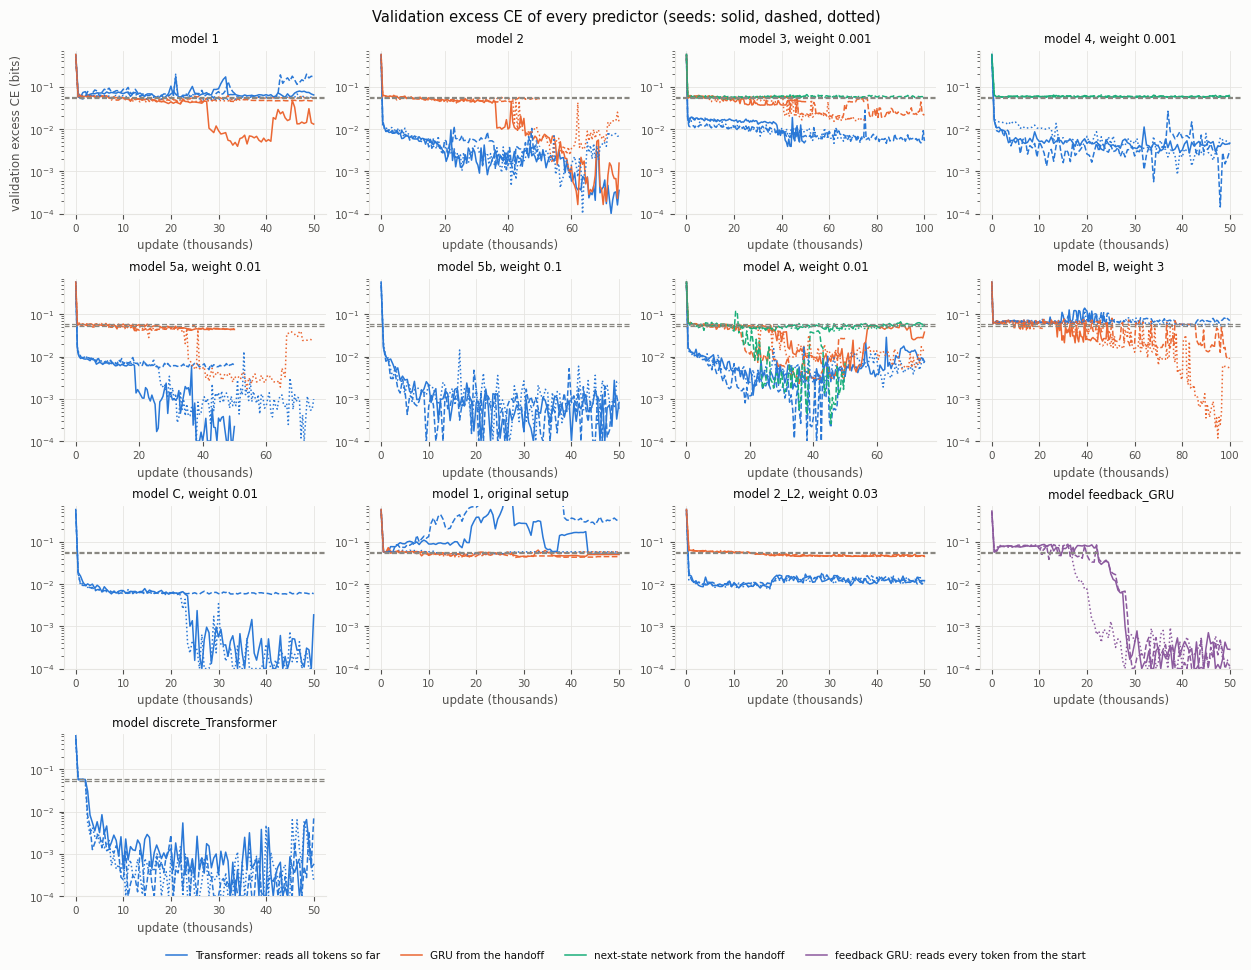

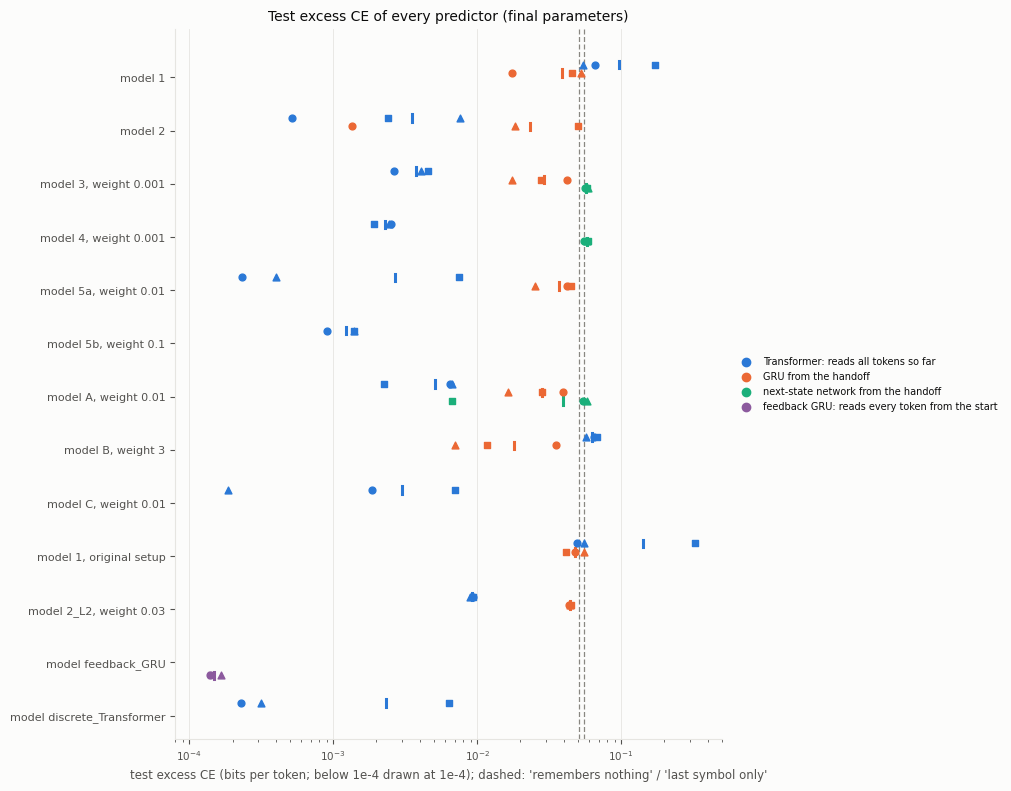

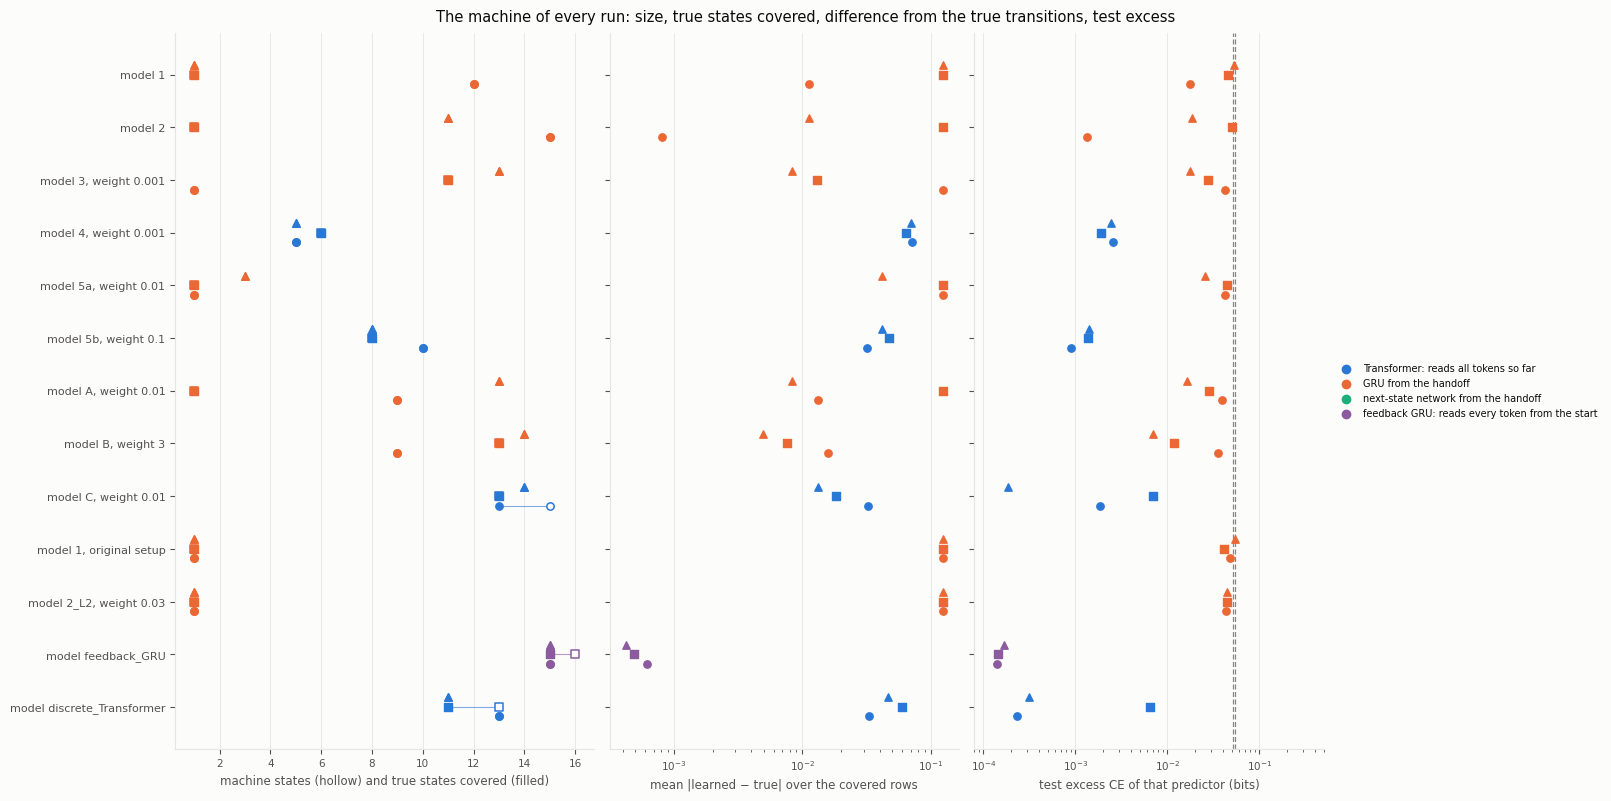

In [6]:
overview = {k: f for k, f in runs.items() if k[1] in ("section16", "section17", "original_setup", "w0.03")}
levels = A.reference_levels(settings, "test")
fig = A.plot_learning_curves(list(overview.values())); plt.show()
fig = A.plot_test_summary(A.test_table(overview), levels); plt.show()
fig = A.plot_machine_summary(A.machine_table(overview), levels); plt.show()

## 6. Demonstrations, one section per model

Each section shows three things for the model's runs:
* **Performance**: test excess CE of each predictor, over 20 and over 200 future tokens.
* **Convergence**: learning curves, states in use, and when the main predictor first fell below 0.04 / 0.02 / 0.01 bits.
* **Properties**: the machine each run ends with, its transitions against the true ones, and what its states stand for.

### 6.1 Model 1: the GRU's predictions only (`model_1.py`), and the original setup

**Loss:** the cross-entropy of the GRU's predictions of the 20 future tokens. The GRU starts from the Transformer's state
after the history. The Transformer is trained only through that starting state, so its own predictions at other
positions are not trained; they are measured anyway.

* **Performance** (first table): each predictor's test excess CE over the 20 future tokens and over 200 (`long_excess`),
  the true states that get a learned state of their own, the size of each step rule's machine, and D (hybrids with a
  GRU).
* **Convergence** (second table): the best validation value of the main predictor and when it first fell below 0.04,
  0.02 and 0.01 bits (empty: never).
* **Properties** (figure): learning curves; the machine each seed ends with; its transitions on the true states; and the
  difference from the true transitions (hatched rows: true states with no learned state of their own).

,weight,update,excess_transformer_future,excess_gru_from_handoff_future,long_excess_gru_from_handoff,transformer_true_states_with_own_state,gru_from_handoff_true_states_with_own_state,gru_from_handoff_long_run_states,distance_D
seed,,,,,,,,,
0,0.0,50000,0.0663,0.0175,0.0184,2,12,12,1.1486
1,0.0,50000,0.1719,0.0453,0.0544,2,1,1,0.4474
2,0.0,50000,0.0540,0.0529,0.0548,1,1,1,0.0037


,final_update,best,best_update,below 0.04,below 0.02,below 0.01
seed,,,,,,
0,50000,0.003902,34000,22000.0,28000.0,28500.0
1,50000,0.040605,22000,NaN,NaN,NaN
2,50000,0.042475,15000,NaN,NaN,NaN


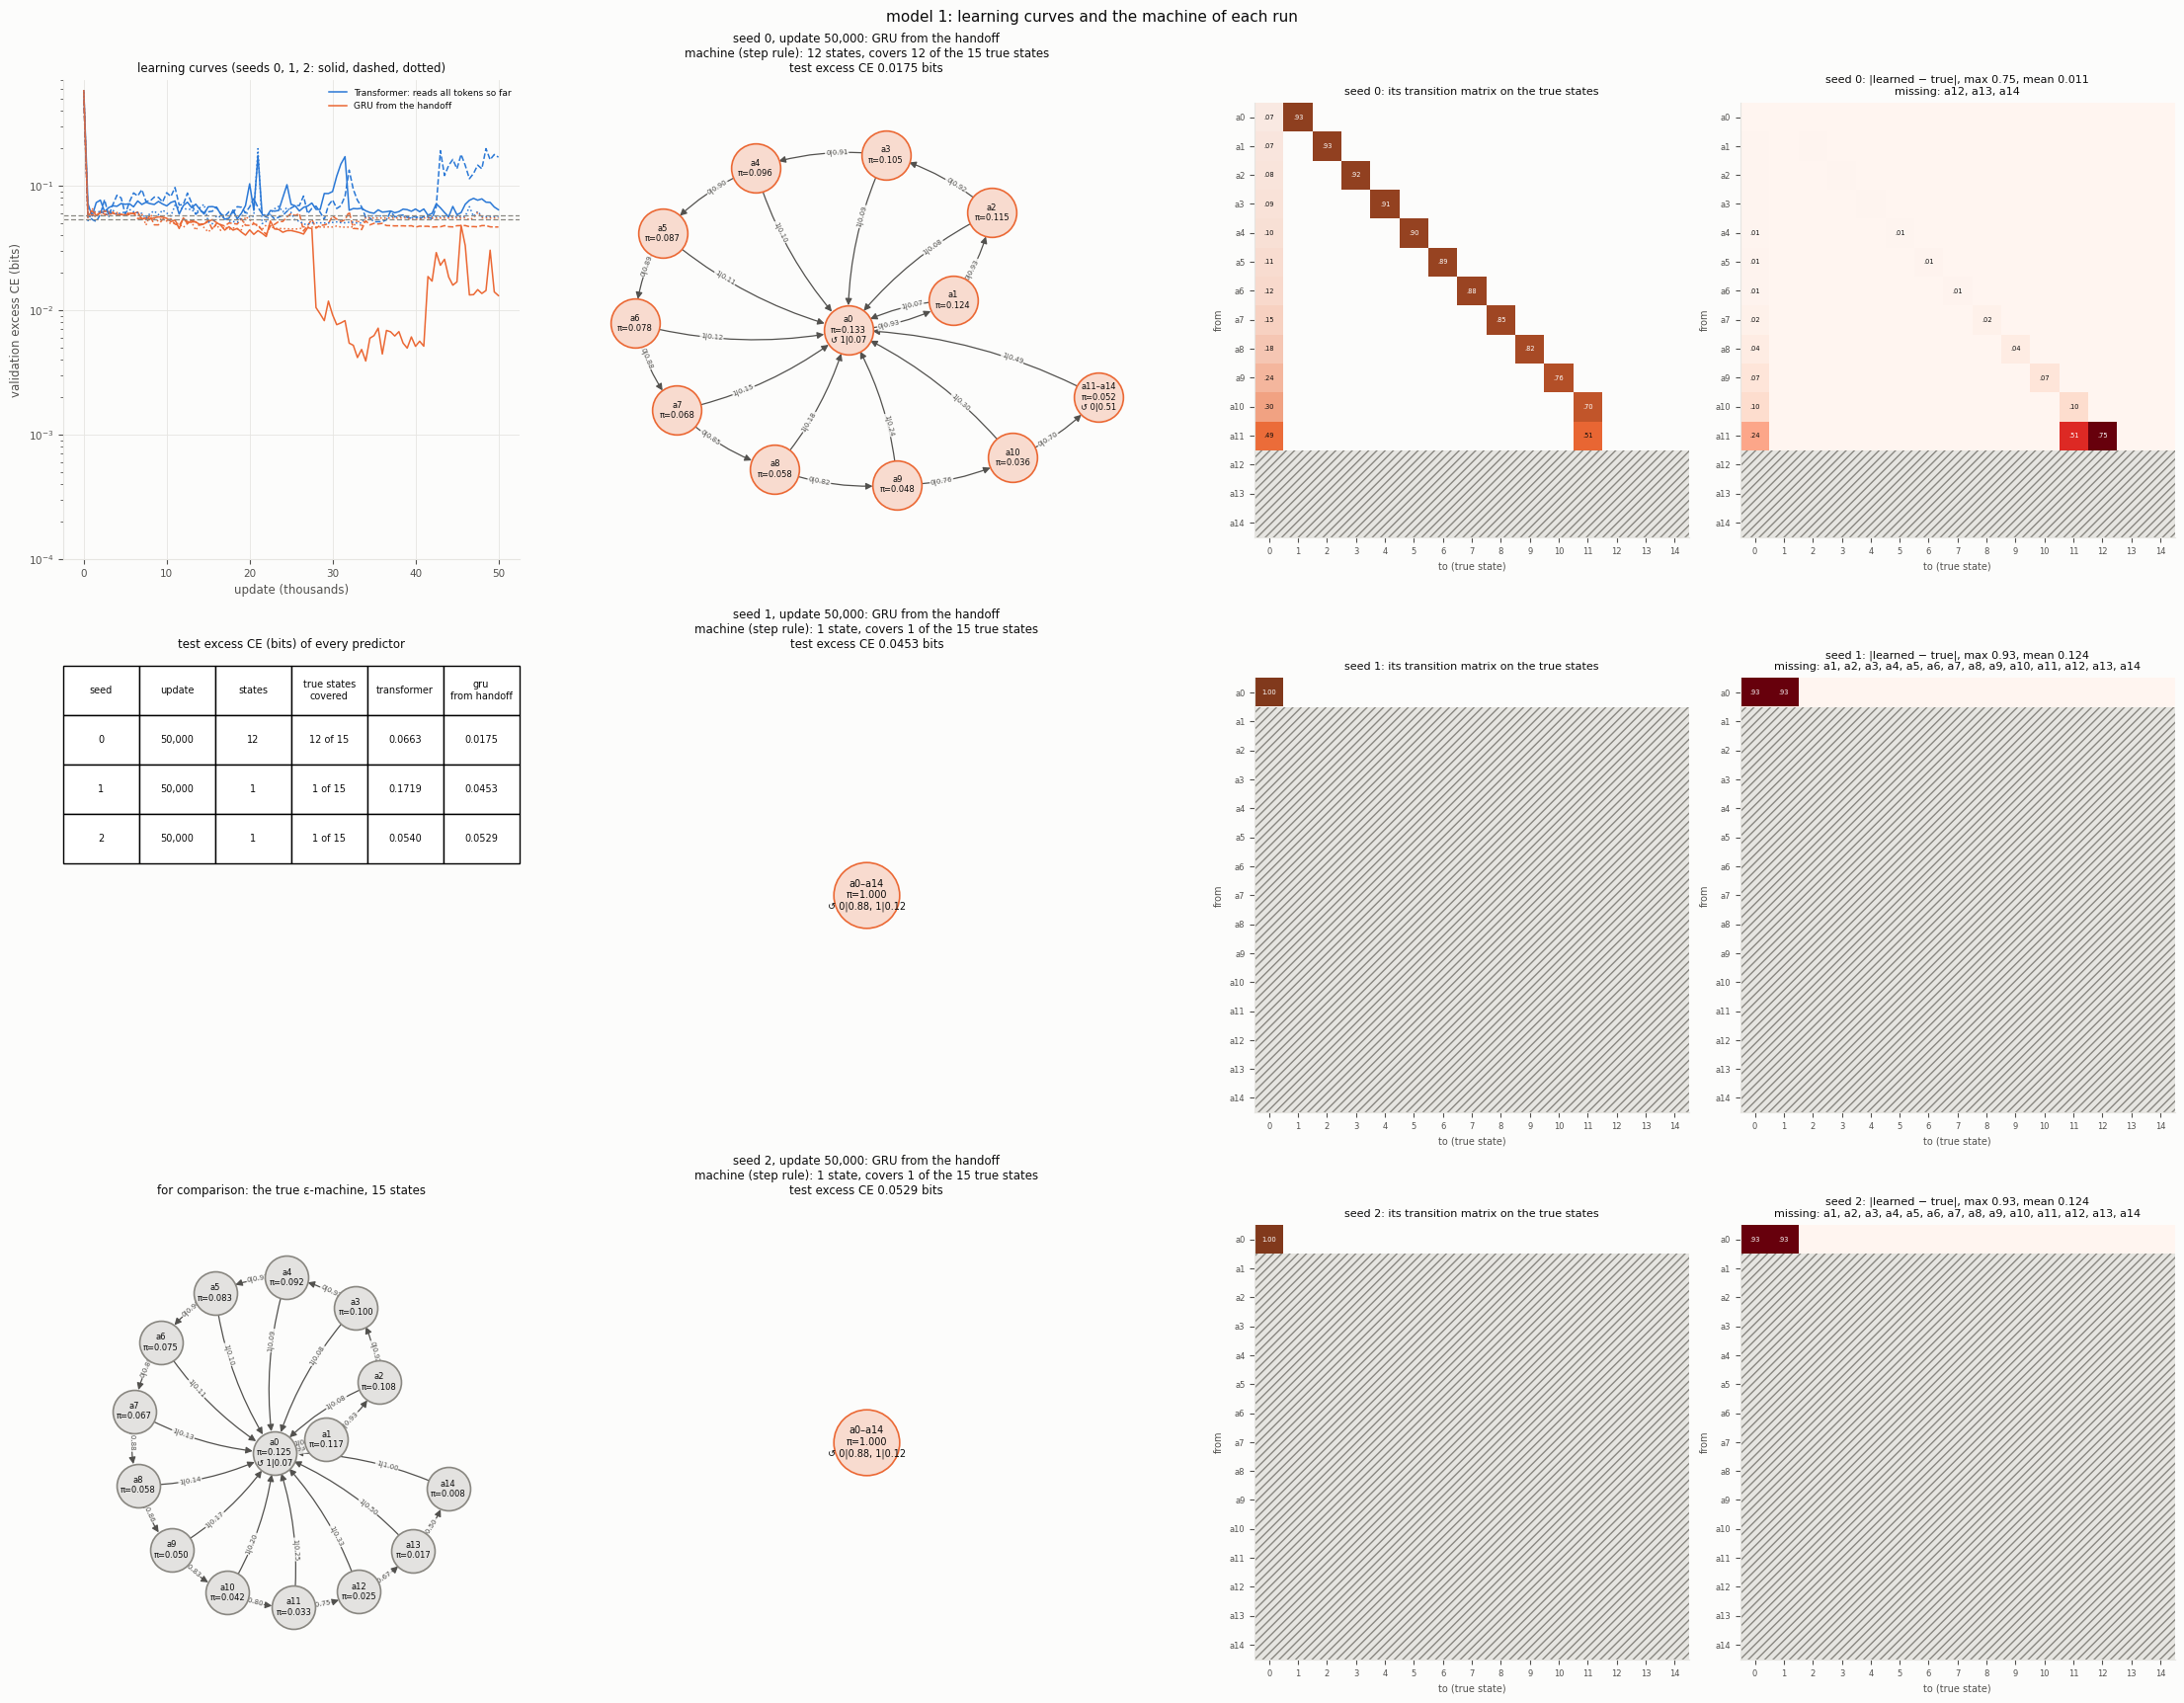

In [7]:
r = runs_of("1", "section16")
display(performance(r))
display(A.first_below(r).set_index("seed")[["final_update", "best", "best_update", "below 0.04", "below 0.02", "below 0.01"]])
fig = A.plot_machines(list(r.values())); plt.show()

**What the runs show**
* **With the 16.1 changes, only seed 0's GRU learns most of the counts.** It ends with 12 long-run states covering 12
  true states, at a test excess of 0.0175 bits. At its best validation update (34,000) it was at 0.0068.
* **Seeds 1 and 2 end with a single long-run state**, at 0.0453 and 0.0529, near the two reference levels.
* **The Transformer's own predictions are not trained by this loss:** 0.0540–0.1719 bits.

The next cell shows the same model in the original setup (no LayerNorm on the Transformer's output, no weight decay, no
gradient clipping).

#### Model 1 in the original setup

,weight,update,excess_transformer_future,excess_gru_from_handoff_future,long_excess_gru_from_handoff,transformer_true_states_with_own_state,gru_from_handoff_true_states_with_own_state,gru_from_handoff_long_run_states,distance_D
seed,,,,,,,,,
0,0.0,50000,0.0490,0.0477,0.0543,2,1,1,0.0201
1,0.0,50000,0.3247,0.0417,0.0542,2,1,1,1.4088
2,0.0,50000,0.0549,0.0549,0.0549,1,1,1,0.0000


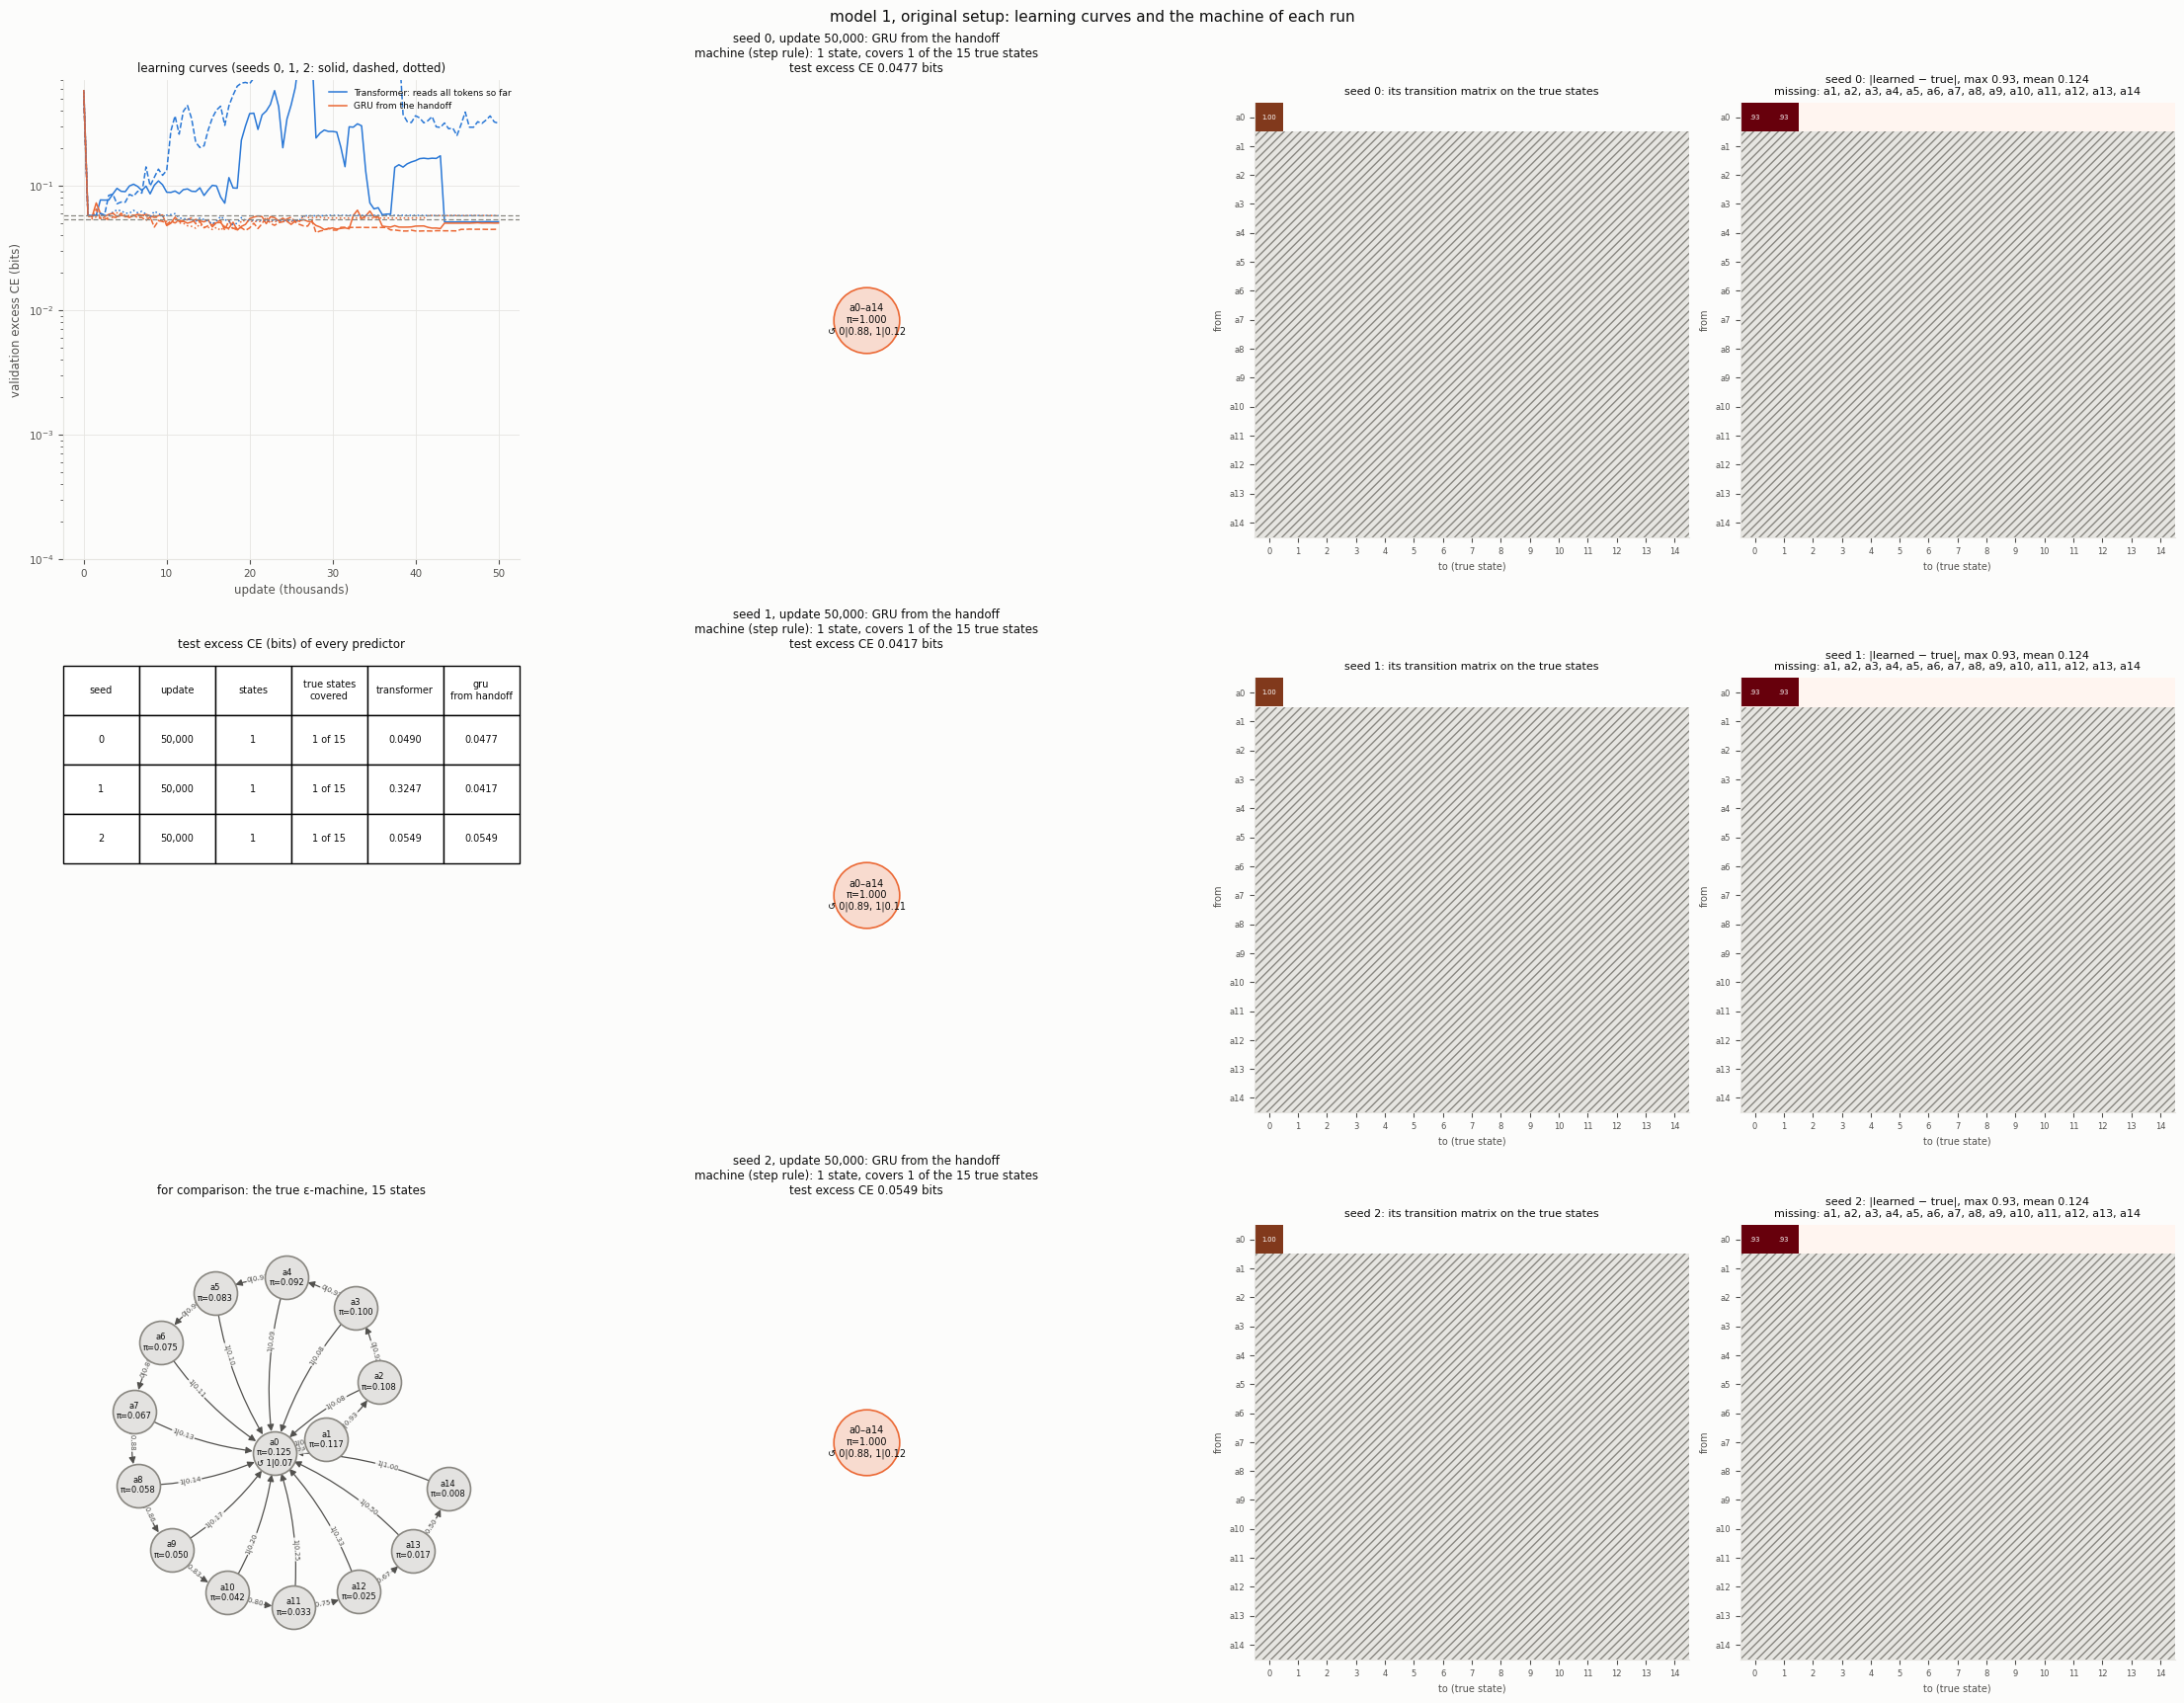

In [8]:
o = runs_of("1", "original_setup")
display(performance(o))
fig = A.plot_machines(list(o.values())); plt.show()

**What the runs show:** all three GRUs end with one long-run state, at 0.0417–0.0549 bits. The Transformer's own
predictions are 0.0490–0.3247 bits.

### 6.2 Model 2: + the Transformer's own next-token predictions (`model_2.py`)

**Loss:** the GRU's future-token CE + the CE of the Transformer's own next-token predictions at every position from 19
on. The Transformer's choice of state is now trained at every position, not only through the GRU at the start.

* **Performance** (first table): each predictor's test excess CE over the 20 future tokens and over 200 (`long_excess`),
  the true states that get a learned state of their own, the size of each step rule's machine, and D (hybrids with a
  GRU).
* **Convergence** (second table): the best validation value of the main predictor and when it first fell below 0.04,
  0.02 and 0.01 bits (empty: never).
* **Properties** (figure): learning curves; the machine each seed ends with; its transitions on the true states; and the
  difference from the true transitions (hatched rows: true states with no learned state of their own).

,weight,update,excess_transformer_future,excess_gru_from_handoff_future,long_excess_gru_from_handoff,transformer_true_states_with_own_state,gru_from_handoff_true_states_with_own_state,gru_from_handoff_long_run_states,distance_D
seed,,,,,,,,,
0,0.0,75000,0.0005,0.0013,0.0005,15,15,15,0.7002
1,0.0,50000,0.0024,0.0500,0.0619,7,1,1,0.3400
2,0.0,75000,0.0076,0.0184,0.0183,13,11,11,0.9728


,final_update,best,best_update,below 0.04,below 0.02,below 0.01
seed,,,,,,
0,75000,0.000164,62000,36500.0,36500.0,38000.0
1,50000,0.040239,23500,NaN,NaN,NaN
2,75000,0.001596,54000,42000.0,42000.0,43000.0


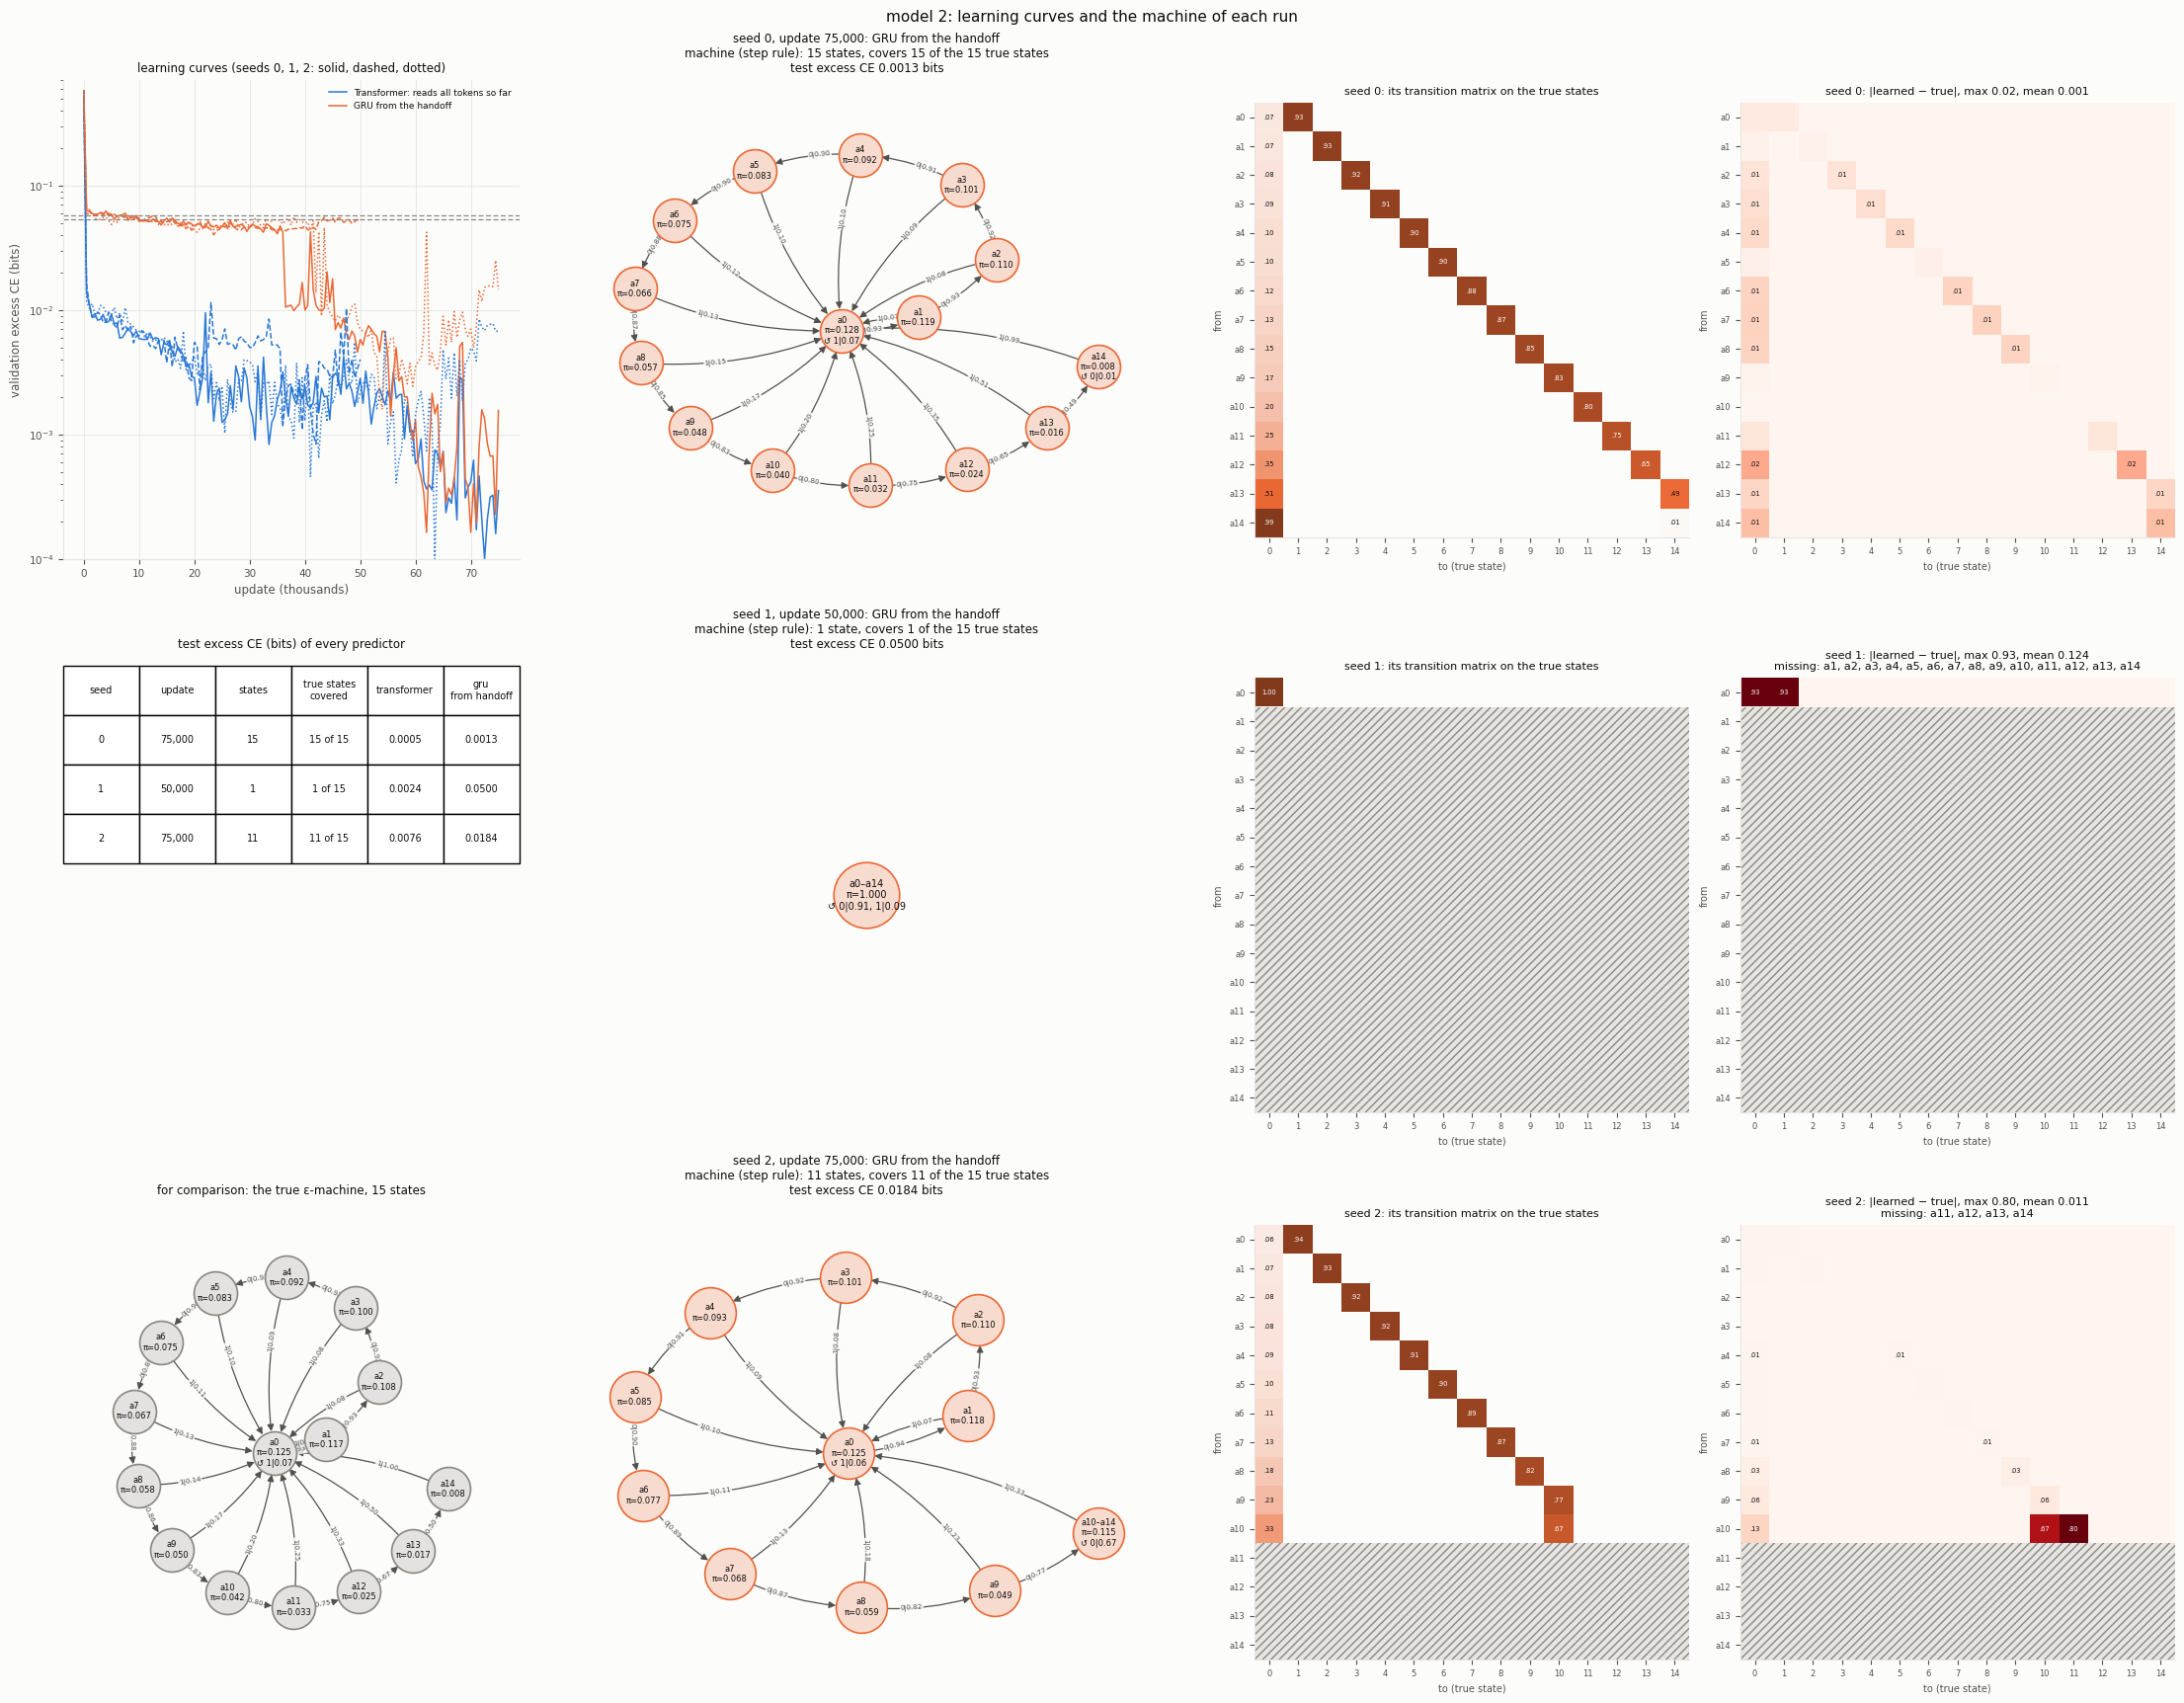

In [9]:
r = runs_of("2", "section16")
display(performance(r))
display(A.first_below(r).set_index("seed")[["final_update", "best", "best_update", "below 0.04", "below 0.02", "below 0.01"]])
fig = A.plot_machines(list(r.values())); plt.show()

**What the runs show**
* **Seed 0's GRU ends with the true machine.**
  * 15 long-run states cover all 15 true states, and its transitions differ from the true ones by 0.0008 on average.
  * Test excess 0.0013 bits (0.0005 at its best validation update, 62,000), and 0.0005 over 200 tokens.
  * It first fell below 0.02 bits at update 36,500.
* **Seeds 2 and 1 do not.** Seed 2's GRU has 11 long-run states (0.0184; 0.0043 at its best, update 54,000). Seed 1's has
  one (0.0500).
* **The Transformer's own predictions are good on every seed:** 0.0005, 0.0024 and 0.0076 bits, giving 15, 7 and 13 true
  states their own state.

### 6.3 Model 3: + a next-state network following the Transformer (`model_3.py`)

**Loss:** model 2's + weight × (entropy of a next-state network's output + its CE against the state the Transformer
actually picks next), with weight 0.001. The network reads a state vector and the next token, and gives probabilities for
the next state. The idea: if the Transformer's states follow a fixed rule, the network can learn it and step through the
future like the GRU.

* **Performance** (first table): each predictor's test excess CE over the 20 future tokens and over 200 (`long_excess`),
  the true states that get a learned state of their own, the size of each step rule's machine, and D (hybrids with a
  GRU).
* **Convergence** (second table): the best validation value of the main predictor and when it first fell below 0.04,
  0.02 and 0.01 bits (empty: never).
* **Properties** (figure): learning curves; the machine each seed ends with; its transitions on the true states; and the
  difference from the true transitions (hatched rows: true states with no learned state of their own).

,weight,update,excess_transformer_future,excess_gru_from_handoff_future,excess_next_state_from_handoff_future,long_excess_gru_from_handoff,long_excess_next_state_from_handoff,transformer_true_states_with_own_state,gru_from_handoff_true_states_with_own_state,next_state_from_handoff_true_states_with_own_state,gru_from_handoff_long_run_states,next_state_from_handoff_long_run_states,distance_D
seed,,,,,,,,,,,,,
0,0.001,50000,0.0026,0.0418,0.0561,0.0539,0.0678,5,1,1,1,1,1.392
1,0.001,100000,0.0045,0.0277,0.0578,0.0263,0.0658,4,11,1,11,1,1.354
2,0.001,75000,0.0041,0.0175,0.0585,0.0114,0.0680,4,13,1,13,1,1.326


,final_update,best,best_update,below 0.04,below 0.02,below 0.01
seed,,,,,,
0,50000,0.036686,31000,24500,NaN,None
1,100000,0.018399,65500,43500,61000.0,None
2,75000,0.015182,62000,41000,43000.0,None


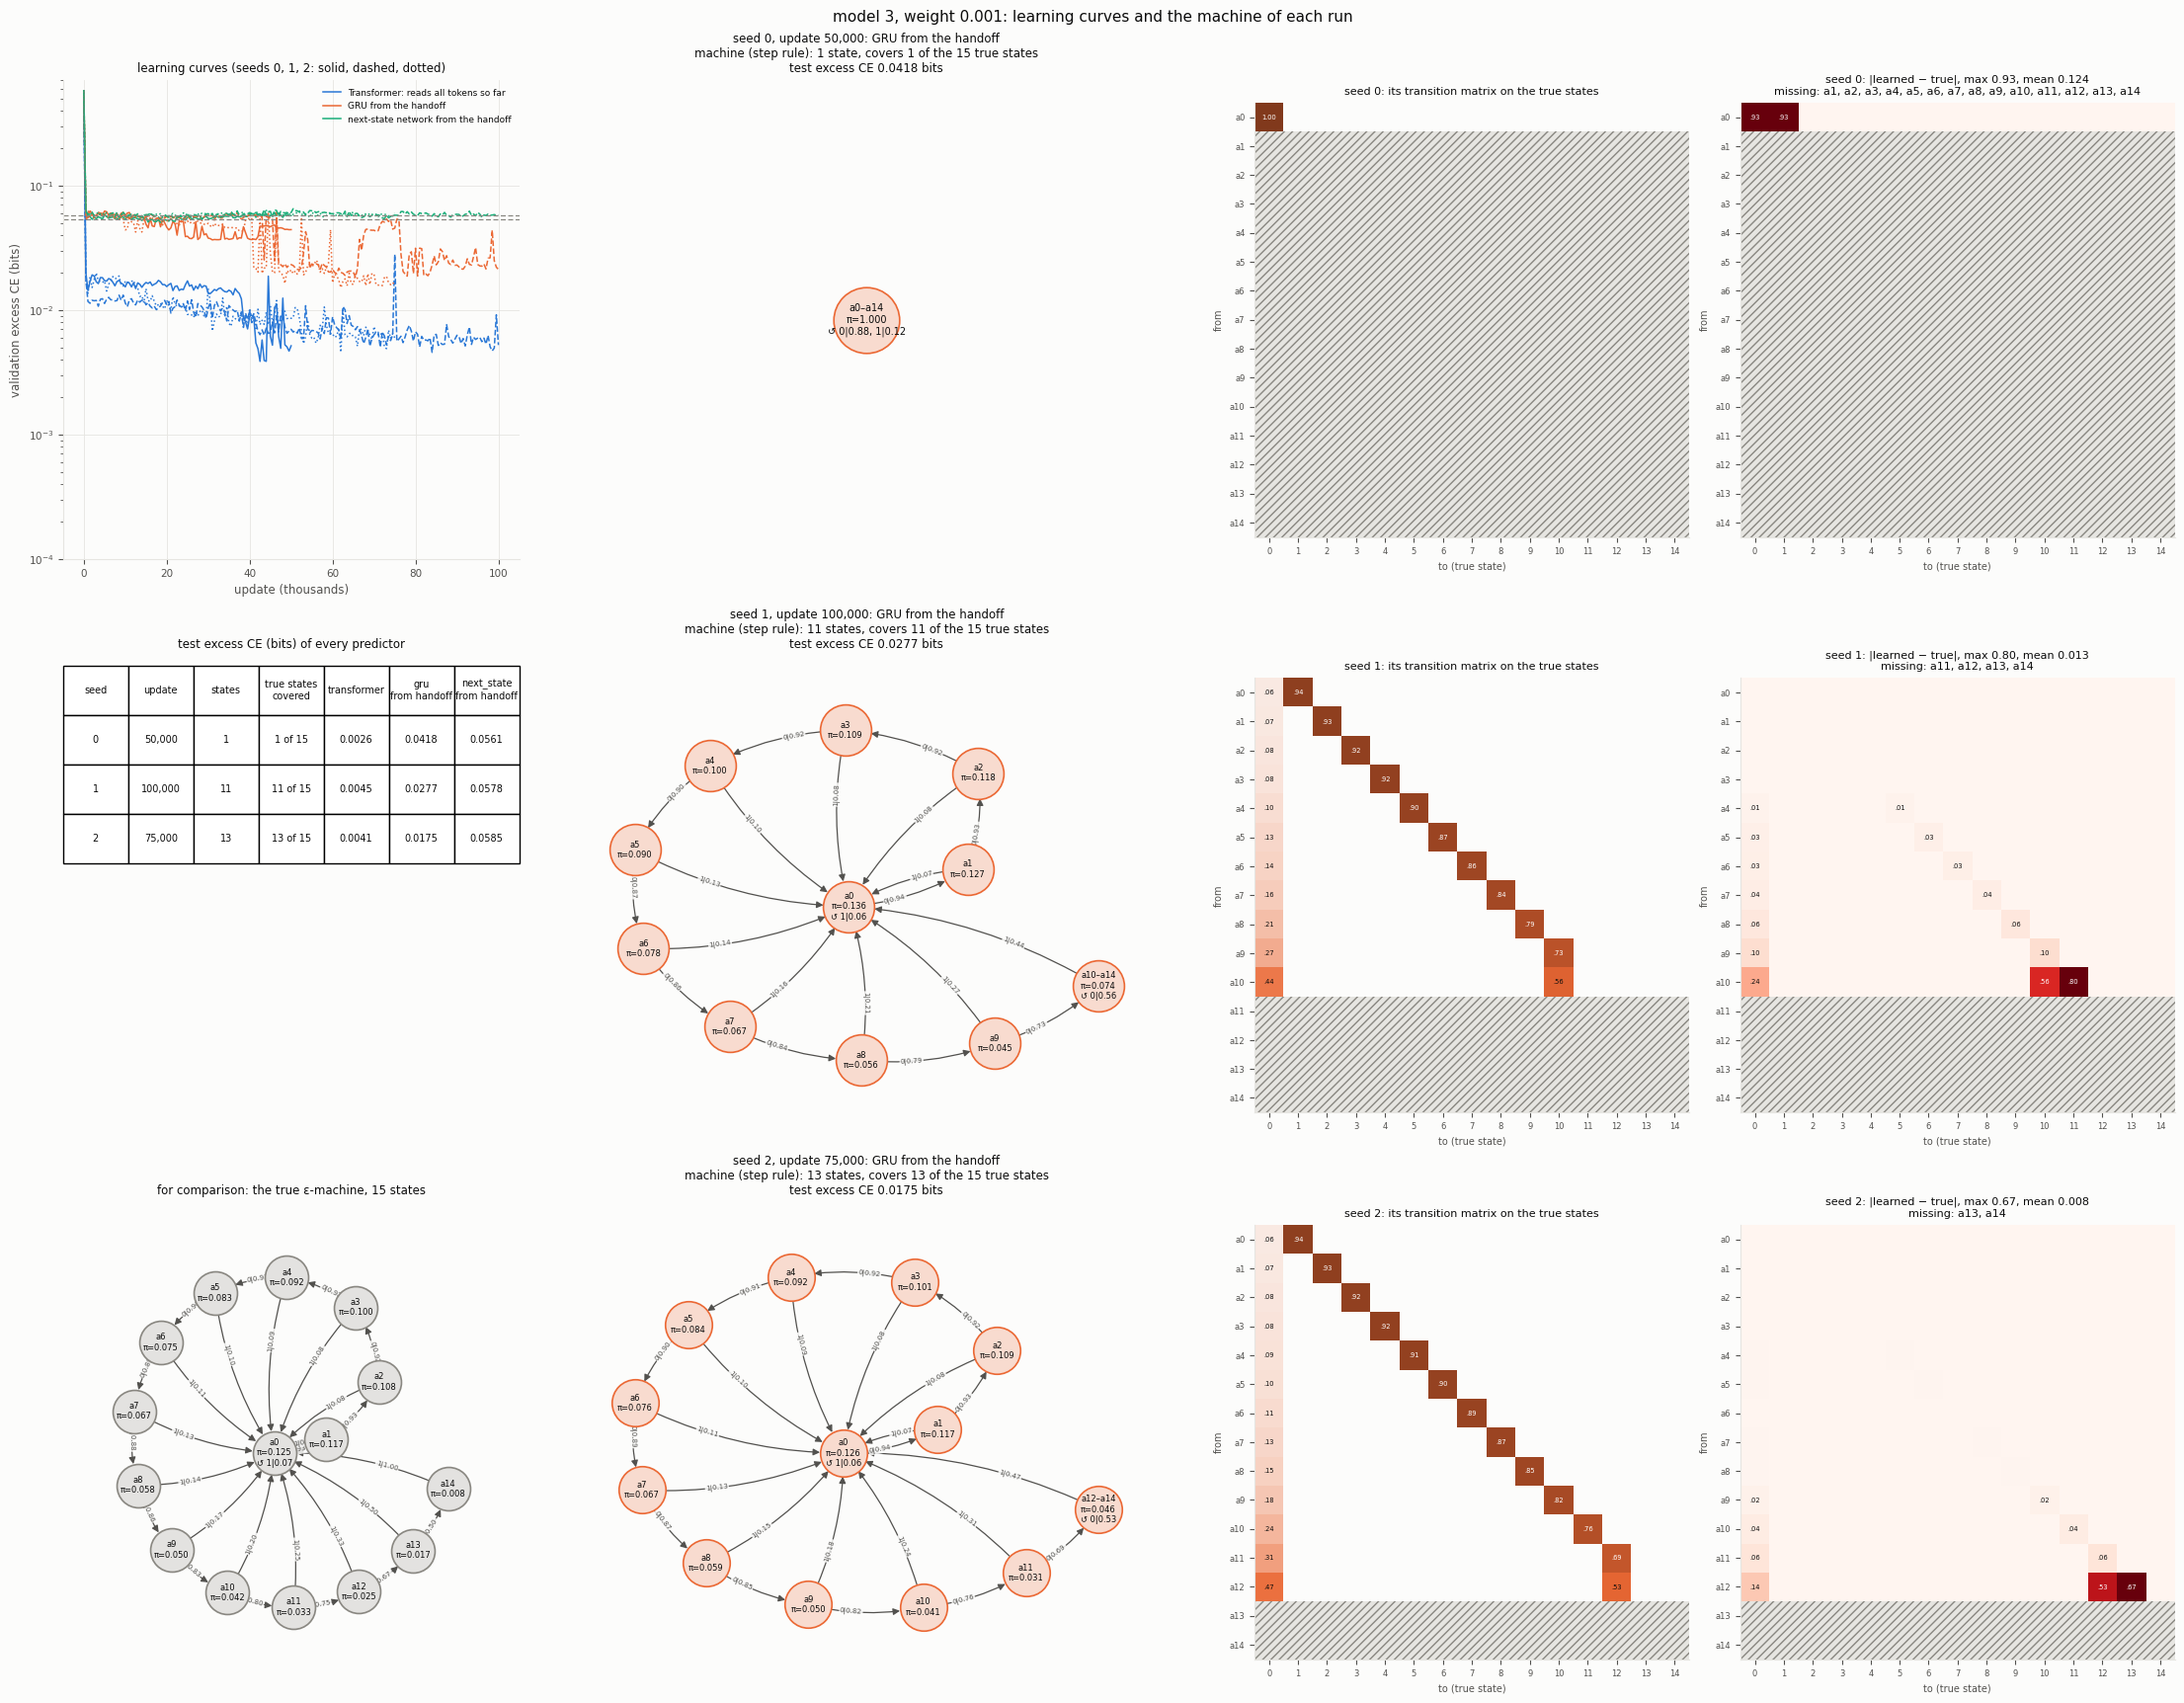

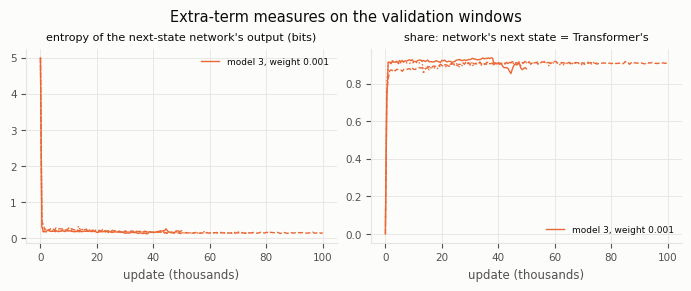

In [10]:
r = runs_of("3", "section16")
display(performance(r))
display(A.first_below(r).set_index("seed")[["final_update", "best", "best_update", "below 0.04", "below 0.02", "below 0.01"]])
fig = A.plot_machines(list(r.values())); plt.show()
fig = A.plot_extra_terms(list(r.values())); plt.show()

**What the runs show**
* **The GRU ends with 1, 11 and 13 long-run states**, at 0.0418, 0.0277 and 0.0175 bits. Seeds 1 and 2 first fell below
  0.02 bits at updates 61,000 and 43,000. No seed reached 0.01.
* **The next-state network stays at the "remembers nothing" level:** 0.0561, 0.0578 and 0.0585 bits.
* **The Transformer's own predictions are good** (0.0026–0.0045 bits), but it gives only 4–5 true states their own state:
  the early counts, whose next-token probabilities are close, share one state.

### 6.4 Model 4: model 3 without the GRU (`model_4.py`)

**Loss:** the Transformer's own next-token CE + weight × (the next-state terms of model 3), with weight 0.001. Can the
next-state network replace the GRU?

* **Performance** (first table): each predictor's test excess CE over the 20 future tokens and over 200 (`long_excess`),
  the true states that get a learned state of their own, the size of each step rule's machine, and D (hybrids with a
  GRU).
* **Convergence** (second table): the best validation value of the main predictor and when it first fell below 0.04,
  0.02 and 0.01 bits (empty: never).
* **Properties** (figure): learning curves; the machine each seed ends with; its transitions on the true states; and the
  difference from the true transitions (hatched rows: true states with no learned state of their own).

,weight,update,excess_transformer_future,excess_next_state_from_handoff_future,long_excess_next_state_from_handoff,transformer_true_states_with_own_state,next_state_from_handoff_true_states_with_own_state,next_state_from_handoff_long_run_states
seed,,,,,,,,
0,0.001,50000,0.0025,0.0552,0.0661,5,1,1
1,0.001,50000,0.0019,0.0591,0.0702,6,1,1
2,0.001,50000,0.0024,0.0582,0.0700,5,1,1


,final_update,best,best_update,below 0.04,below 0.02,below 0.01
seed,,,,,,
0,50000,0.002710,41500,500,500,2000
1,50000,0.000144,48000,500,500,1000
2,50000,0.000839,39000,500,500,11000


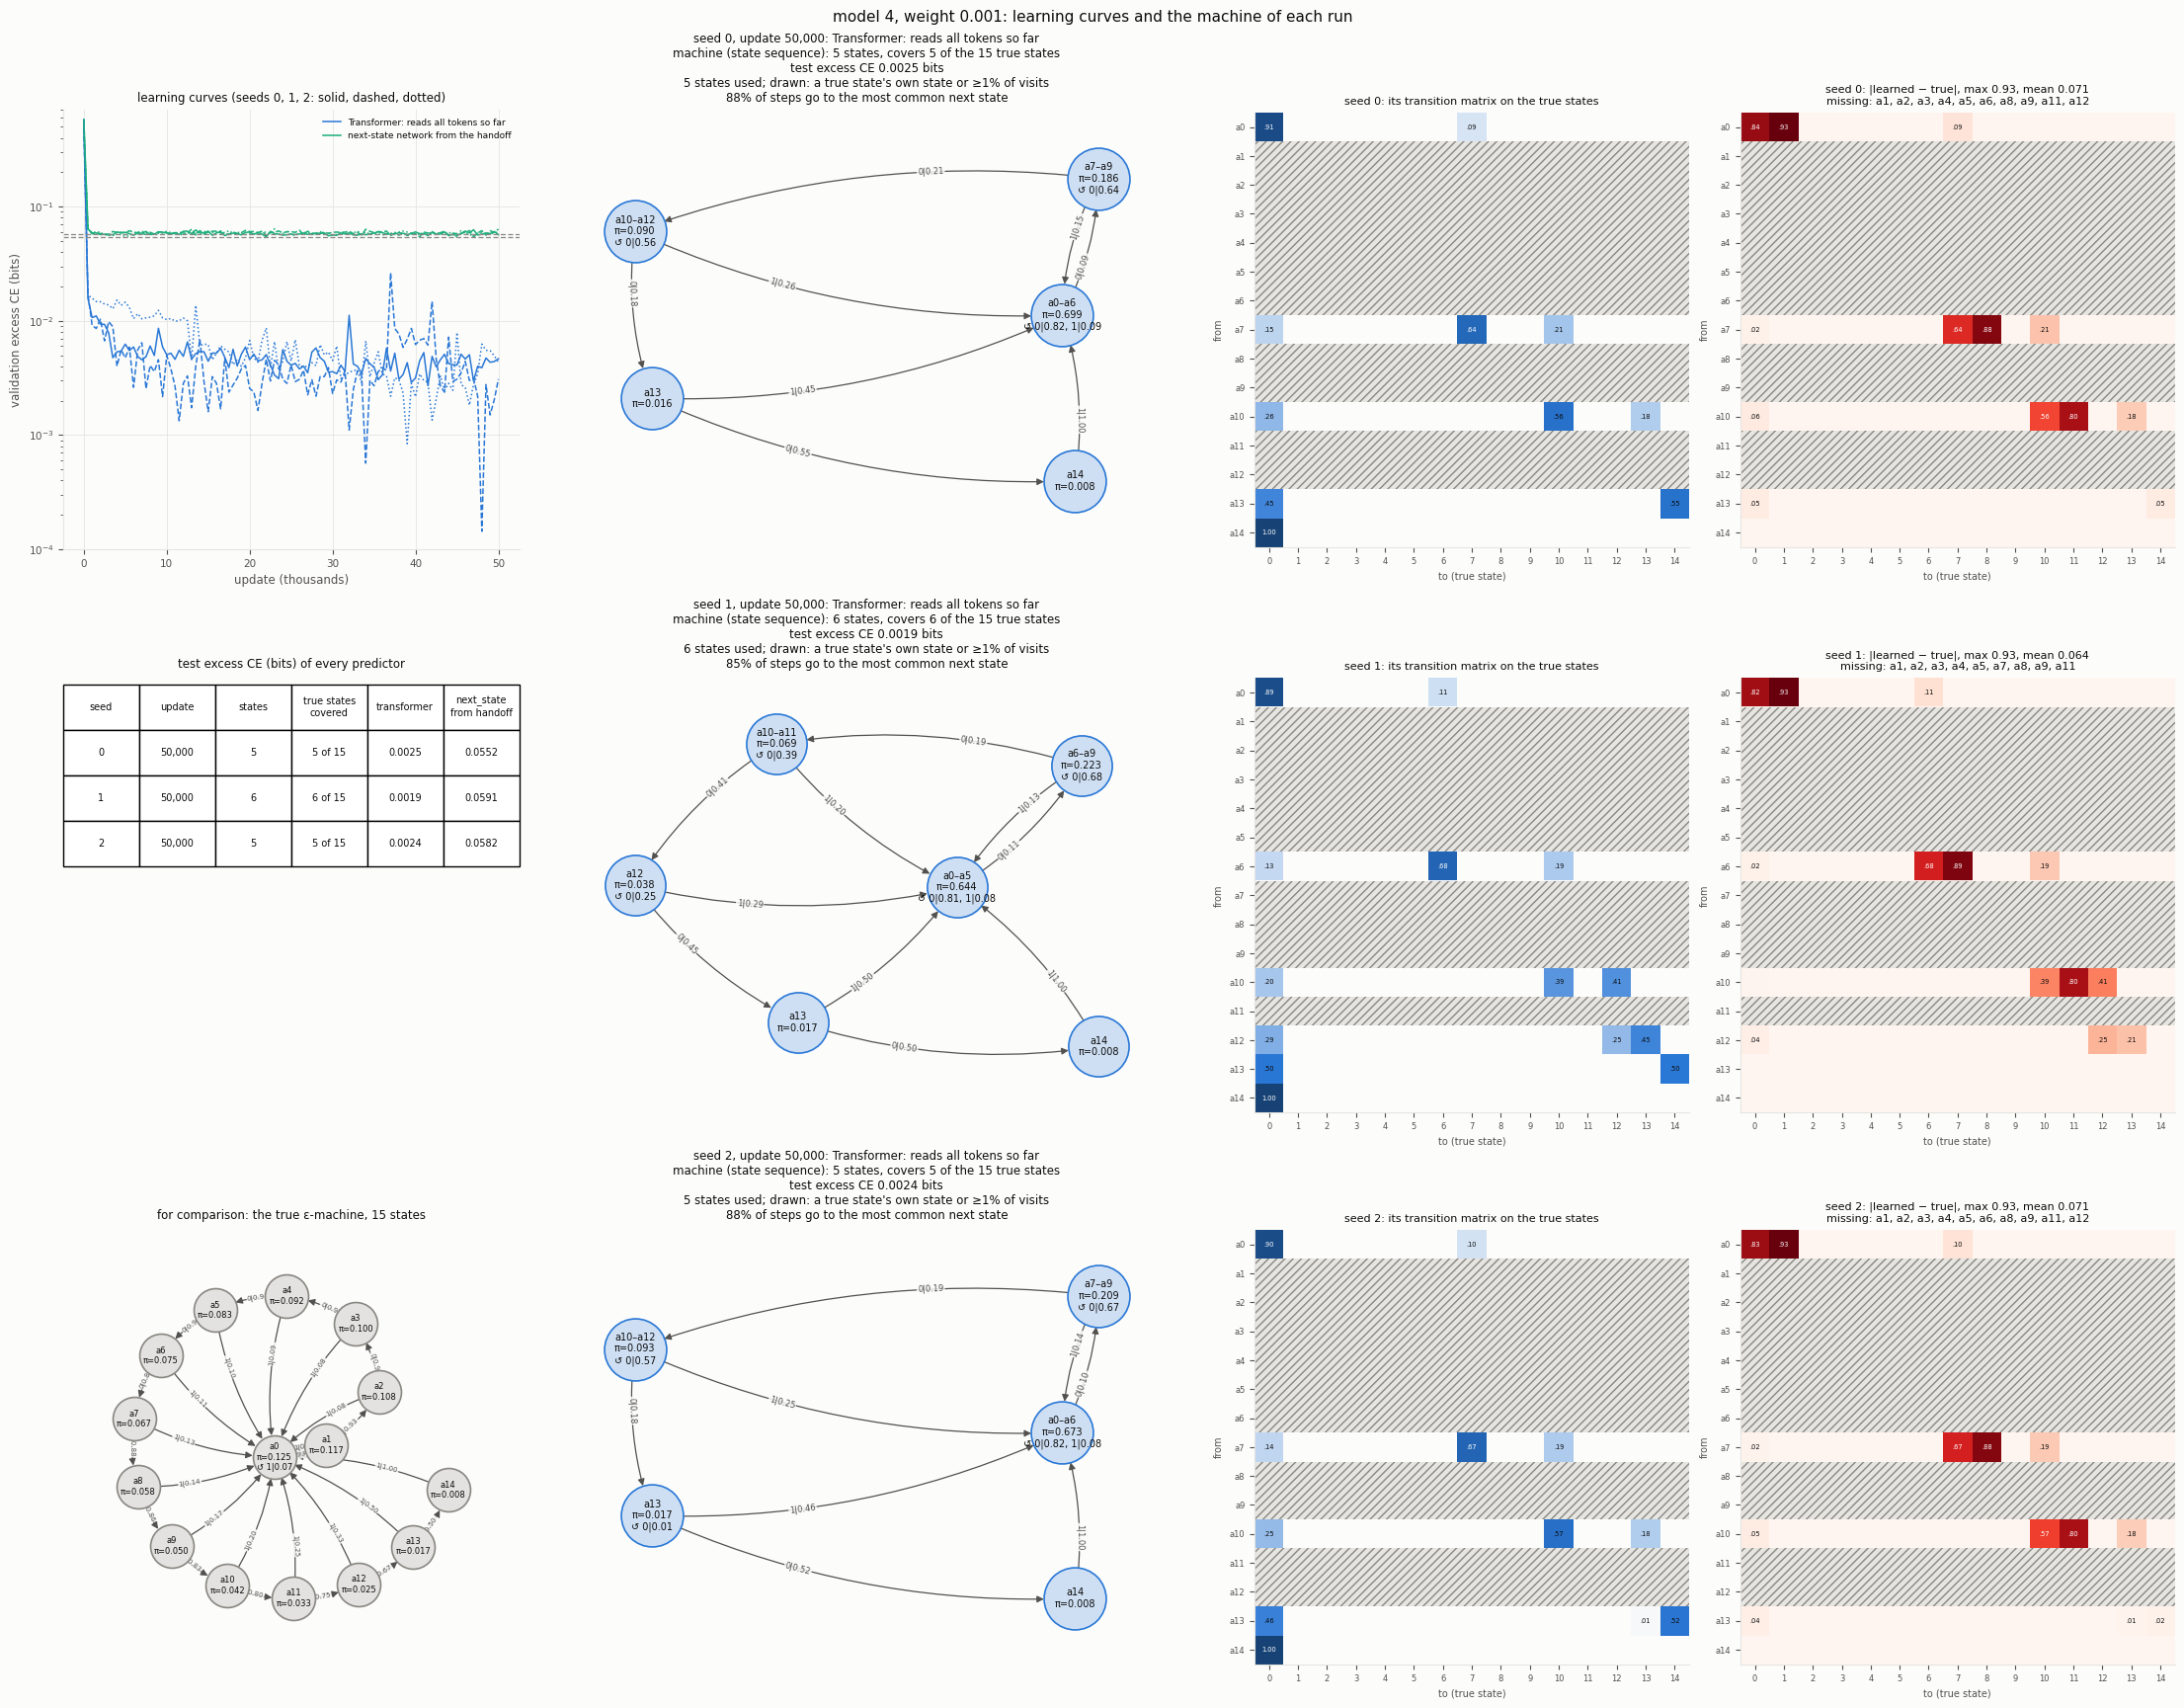

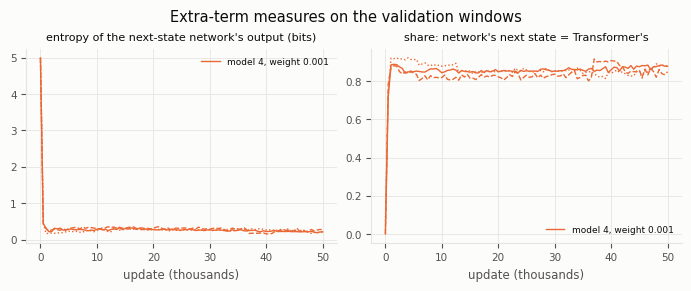

In [11]:
r = runs_of("4", "section16")
display(performance(r))
display(A.first_below(r).set_index("seed")[["final_update", "best", "best_update", "below 0.04", "below 0.02", "below 0.01"]])
fig = A.plot_machines(list(r.values())); plt.show()
fig = A.plot_extra_terms(list(r.values())); plt.show()

**What the runs show**
* **The Transformer's predictions** are at 0.0025, 0.0019 and 0.0024 bits. They first fell below 0.01 bits at updates
  2,000, 1,000 and 11,000.
* **Its machine, read off its states, has 5, 6 and 5 states**, covering the same numbers of true states: the early
  counts share one state.
* **The next-state network does not replace the GRU:** 0.0552, 0.0591 and 0.0582 bits, the "remembers nothing" level.

### 6.5 Model 5a: one- and two-step predictions + the spread of the inferred next state (`model_5a.py`)

**Loss:** the GRU's future-token CE + the Transformer's one- and two-step CE + weight × the entropy of the next state
worked out from those predictions with Bayes' rule, with weight 0.01. The three steps are in `model_5a.py`. The next cell
also prints the value this penalty would have on the true machine, and its floor, the crypticity.

* **Performance** (first table): each predictor's test excess CE over the 20 future tokens and over 200 (`long_excess`),
  the true states that get a learned state of their own, the size of each step rule's machine, and D (hybrids with a
  GRU).
* **Convergence** (second table): the best validation value of the main predictor and when it first fell below 0.04,
  0.02 and 0.01 bits (empty: never).
* **Properties** (figure): learning curves; the machine each seed ends with; its transitions on the true states; and the
  difference from the true transitions (hatched rows: true states with no learned state of their own).

,weight,update,excess_transformer_future,excess_gru_from_handoff_future,long_excess_gru_from_handoff,transformer_true_states_with_own_state,gru_from_handoff_true_states_with_own_state,gru_from_handoff_long_run_states,distance_D
seed,,,,,,,,,
0,0.01,50000,0.0002,0.0418,0.0538,11,1,1,1.3820
1,0.01,50000,0.0075,0.0446,0.0543,11,1,1,1.3510
2,0.01,75000,0.0004,0.0254,0.0477,13,4,3,1.1867


,final_update,best,best_update,below 0.04,below 0.02,below 0.01
seed,,,,,,
0,50000,0.041035,18500,NaN,NaN,NaN
1,50000,0.040234,19000,NaN,NaN,NaN
2,75000,0.001731,54000,23000.0,35500.0,35500.0


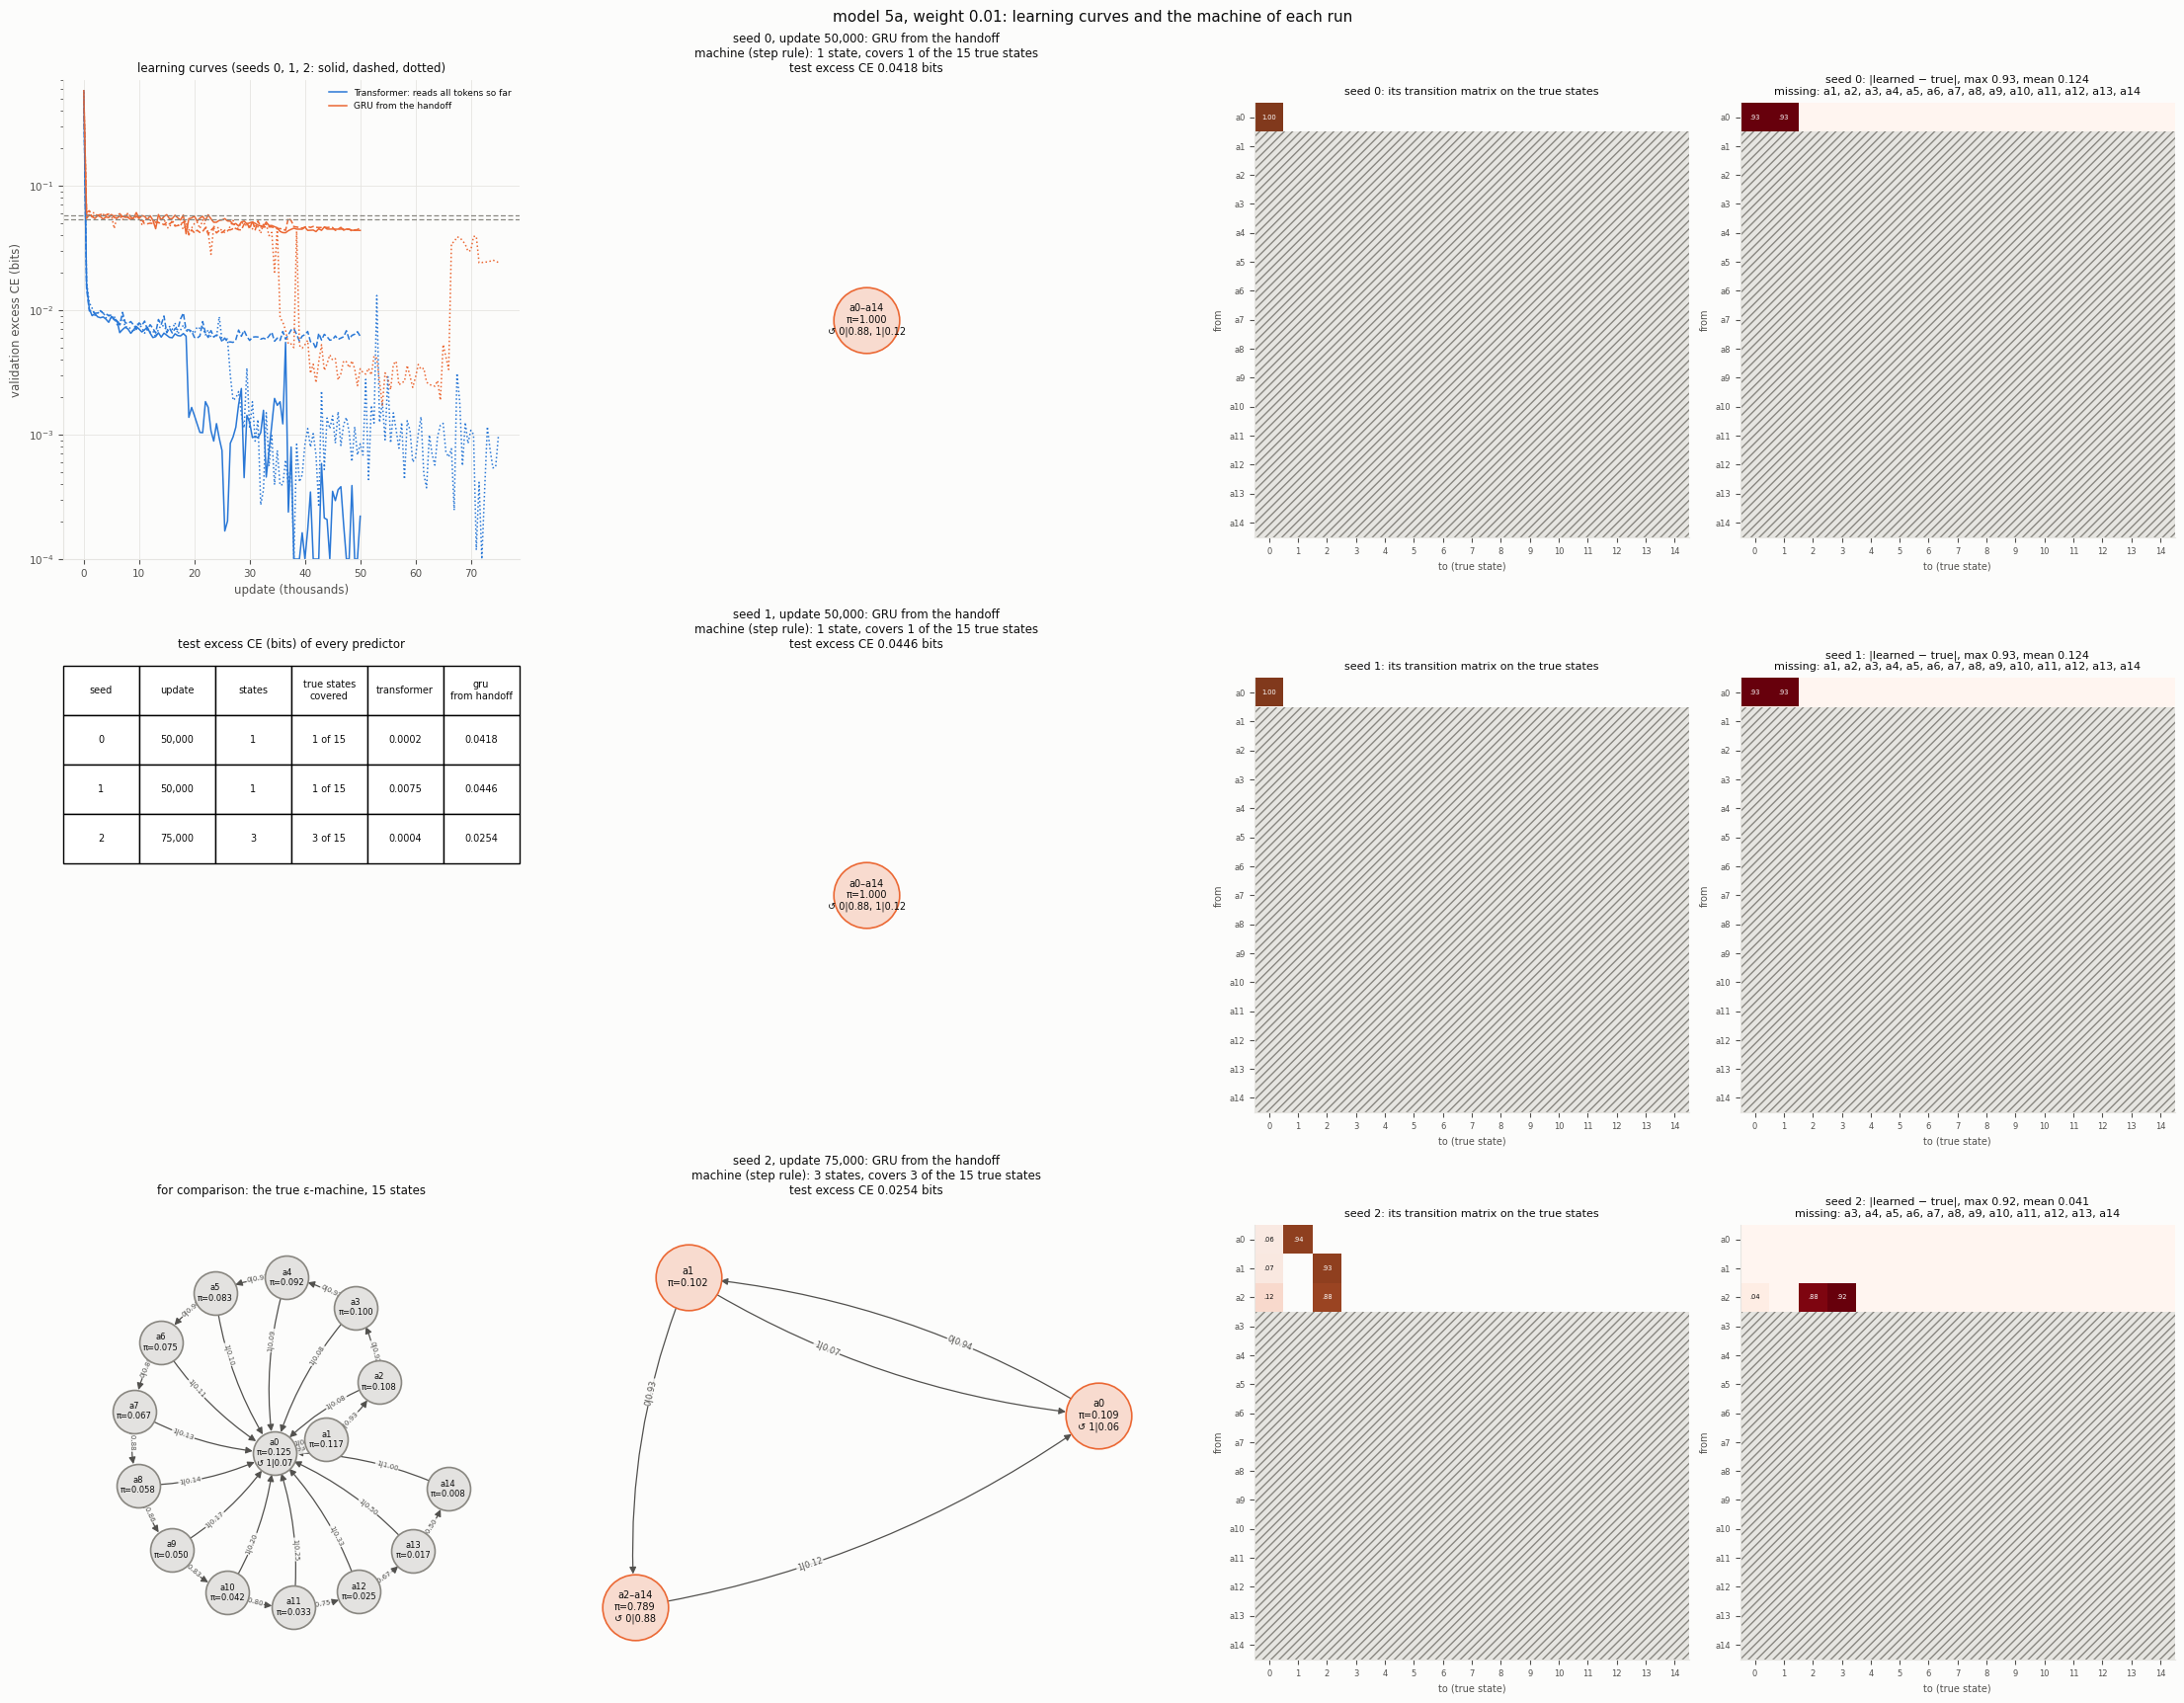

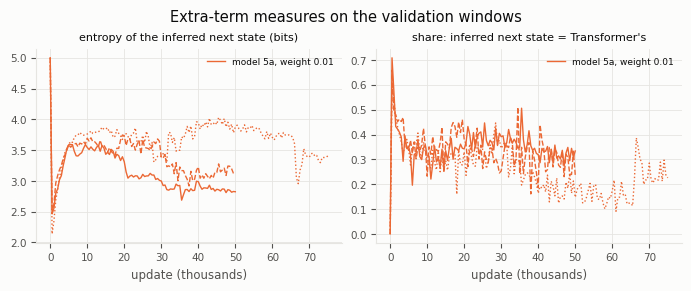

true_machine_entropy      3.6645
crypticity                3.2363
statistical_complexity    3.6706
excess_entropy            0.4342
dtype: float64

In [12]:
r = runs_of("5a", "section16")
display(performance(r))
display(A.first_below(r).set_index("seed")[["final_update", "best", "best_update", "below 0.04", "below 0.02", "below 0.01"]])
fig = A.plot_machines(list(r.values())); plt.show()
fig = A.plot_extra_terms(list(r.values())); plt.show()
display(pd.Series(A.inferred_entropy_on_true_machine(settings, 1)).round(4))

**What the runs show**
* **The GRU ends with one long-run state on seeds 0 and 1** (0.0418, 0.0446 bits) and 3 on seed 2 (0.0254). Seed 2 was
  at 0.0042 at its best validation update, 54,000.
* **The Transformer's own predictions are good:** 0.0002, 0.0075 and 0.0004 bits, giving 11, 11 and 13 true states their
  own state.
* **The penalty favours fewer states.** On the true machine it is 3.6645 bits, while a single state scores 0. No number
  of predicted tokens can bring the true machine below the crypticity, 3.2363 bits.

### 6.6 Model 5b: model 5a without the GRU (`model_5b.py`)

**Loss:** the Transformer's one- and two-step CE + weight × the entropy of the inferred next state, with weight 0.1.

* **Performance** (first table): each predictor's test excess CE over the 20 future tokens and over 200 (`long_excess`),
  the true states that get a learned state of their own, the size of each step rule's machine, and D (hybrids with a
  GRU).
* **Convergence** (second table): the best validation value of the main predictor and when it first fell below 0.04,
  0.02 and 0.01 bits (empty: never).
* **Properties** (figure): learning curves; the machine each seed ends with; its transitions on the true states; and the
  difference from the true transitions (hatched rows: true states with no learned state of their own).

,weight,update,excess_transformer_future,transformer_true_states_with_own_state
seed,,,,
0,0.1,50000,0.0009,10
1,0.1,50000,0.0014,8
2,0.1,50000,0.0014,8


,final_update,best,best_update,below 0.04,below 0.02,below 0.01
seed,,,,,,
0,50000,-0.000129,40000,500,500,1500
1,50000,-0.000417,20500,500,500,1000
2,50000,-0.000445,27000,500,1000,1000


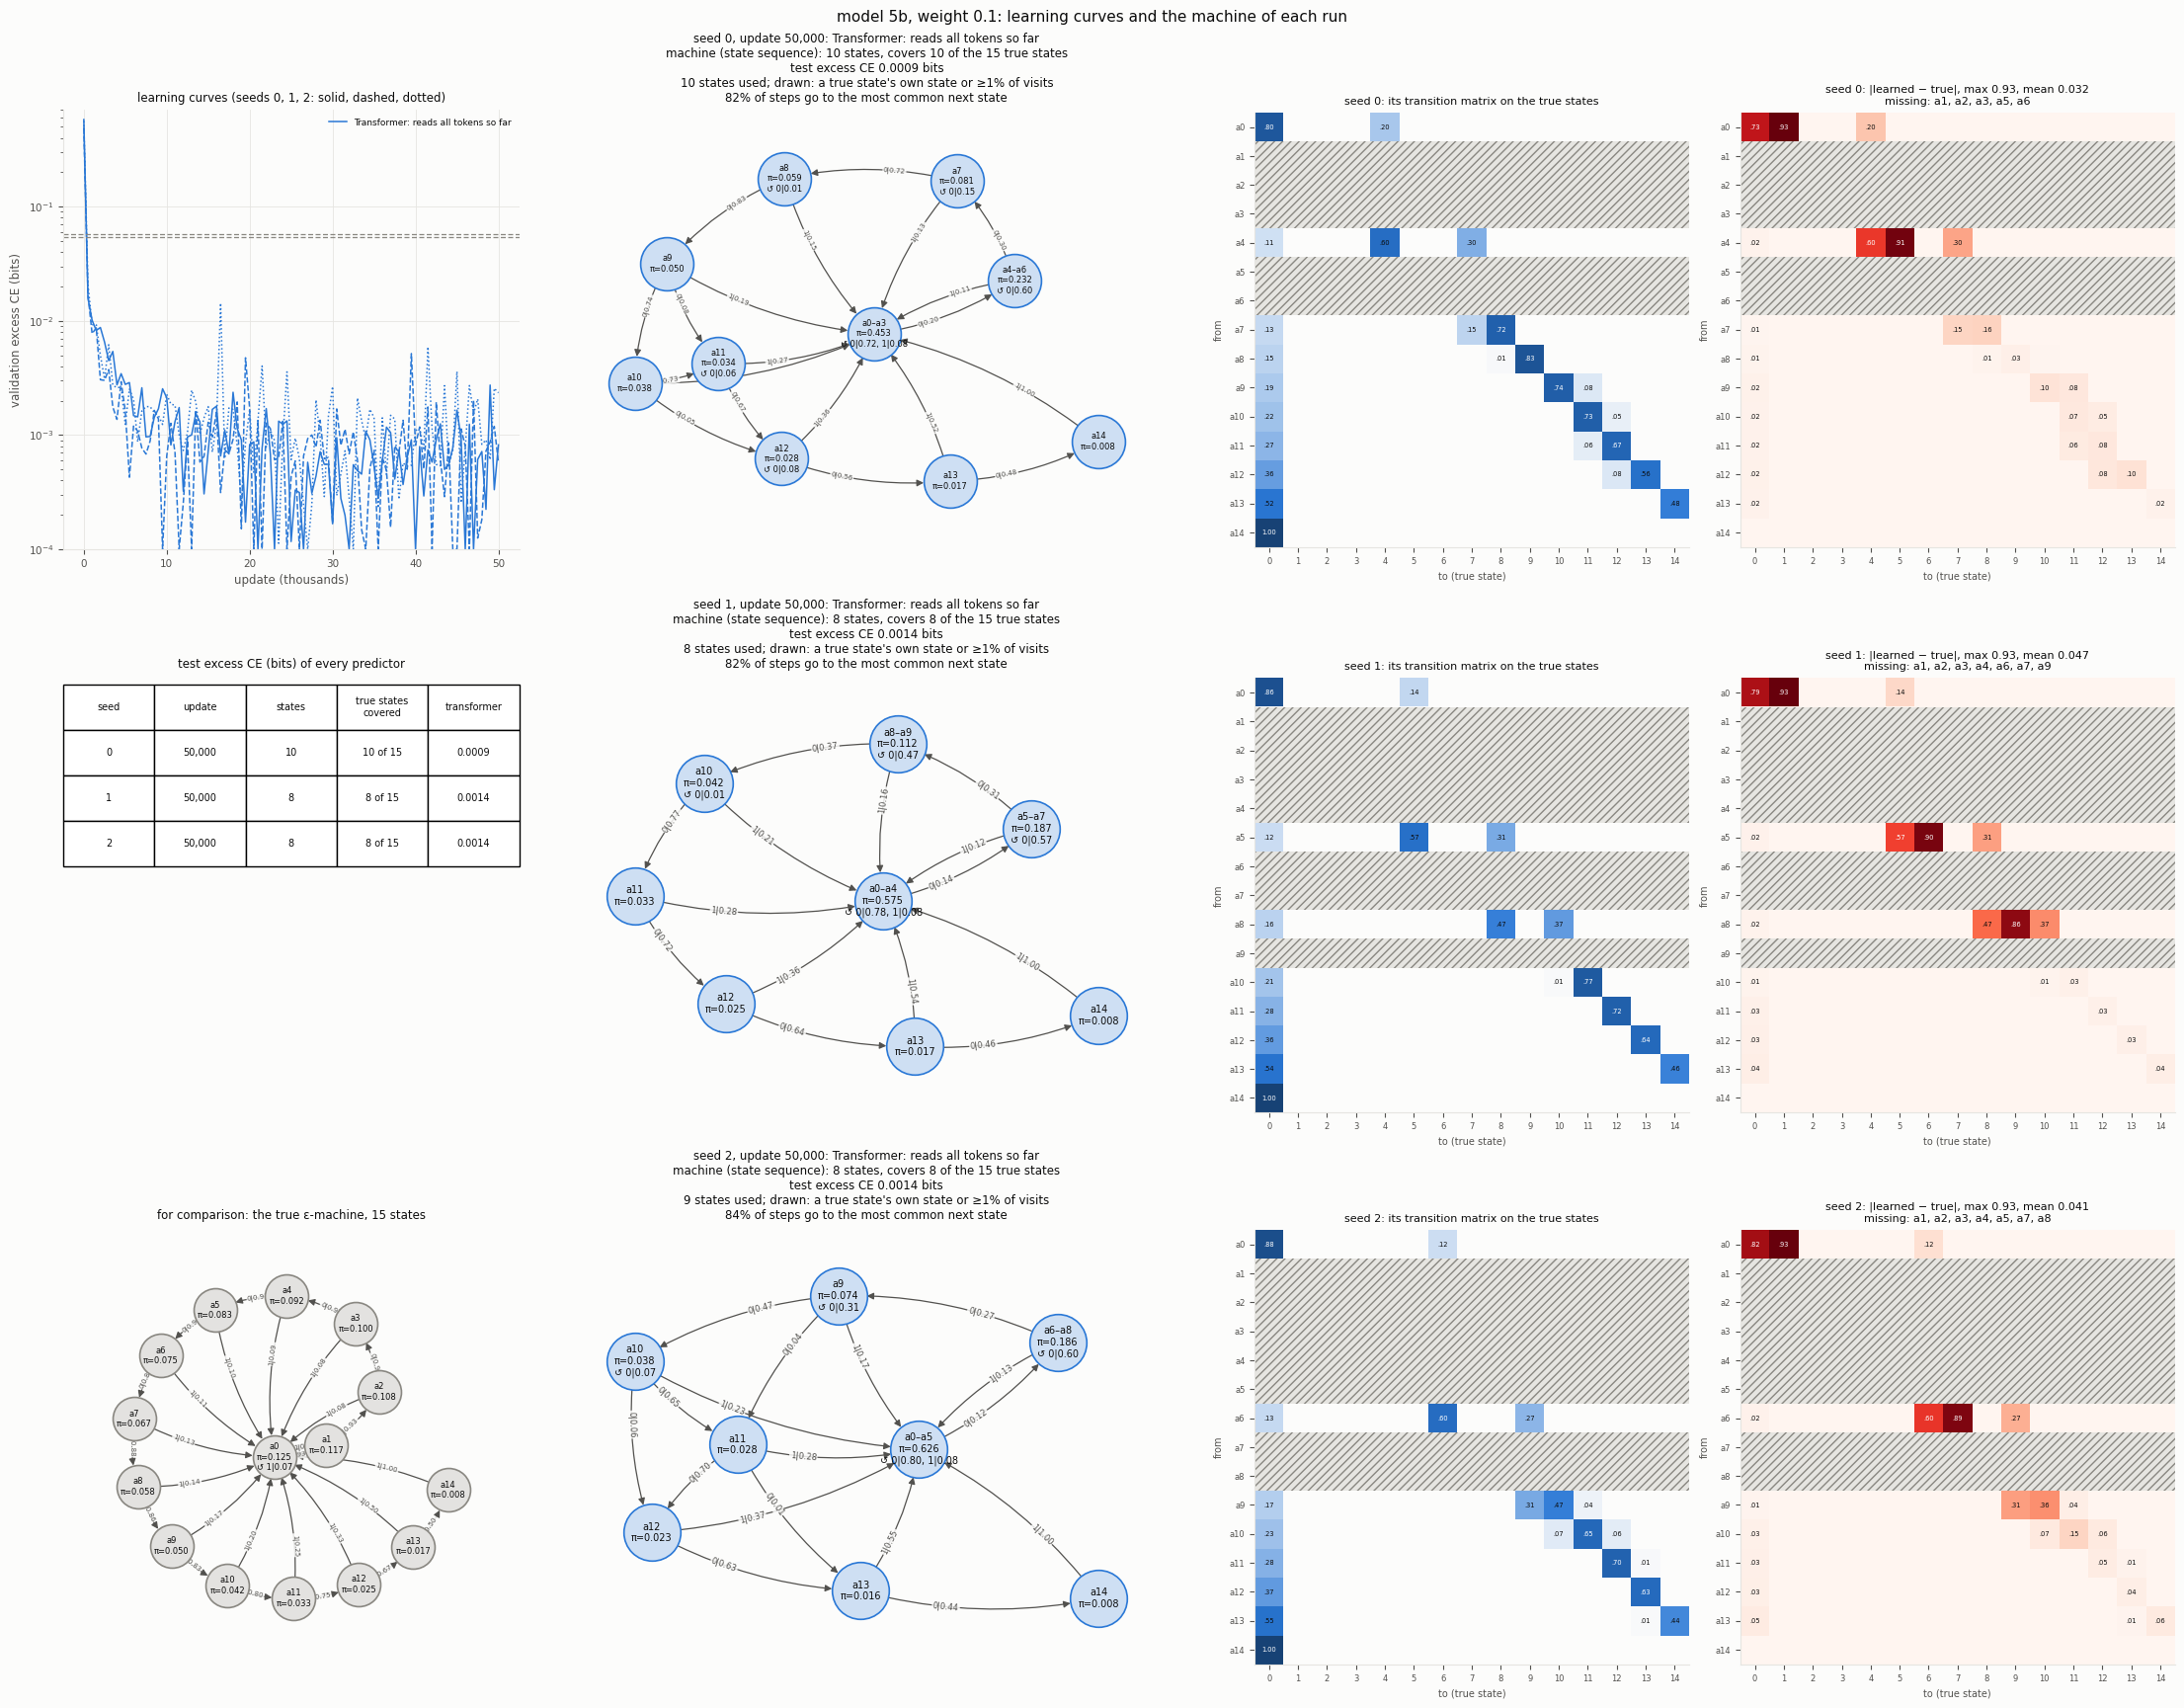

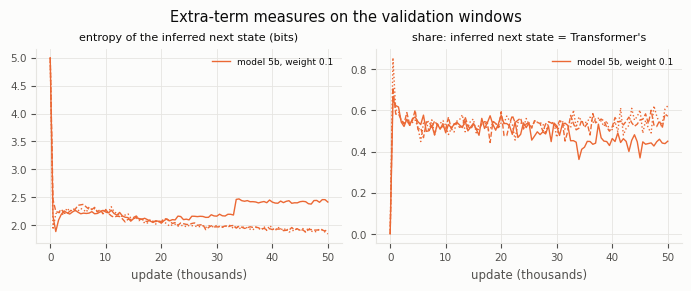

In [13]:
r = runs_of("5b", "section16")
display(performance(r))
display(A.first_below(r).set_index("seed")[["final_update", "best", "best_update", "below 0.04", "below 0.02", "below 0.01"]])
fig = A.plot_machines(list(r.values())); plt.show()
fig = A.plot_extra_terms(list(r.values())); plt.show()

**What the runs show**
* **The Transformer's predictions** are at 0.0009, 0.0014 and 0.0014 bits. They first fell below 0.01 bits at updates
  1,000–1,500.
* **Its machine has 10, 8 and 8 states**, covering the same numbers of true states.

### 6.7 Model A: model 3 with the Transformer's next state as a fixed target (`model_A.py`)

**Loss:** model 3's, with weight 0.01. The state the Transformer picks next is a fixed target: no gradient of the
next-state terms reaches the Transformer through it. Holding the target fixed is the known remedy against a model
predicting its own next state collapsing to a constant state (Tang et al. 2023; Chen & He 2021).

* **Performance** (first table): each predictor's test excess CE over the 20 future tokens and over 200 (`long_excess`),
  the true states that get a learned state of their own, the size of each step rule's machine, and D (hybrids with a
  GRU).
* **Convergence** (second table): the best validation value of the main predictor and when it first fell below 0.04,
  0.02 and 0.01 bits (empty: never).
* **Properties** (figure): learning curves; the machine each seed ends with; its transitions on the true states; and the
  difference from the true transitions (hatched rows: true states with no learned state of their own).

,weight,update,excess_transformer_future,excess_gru_from_handoff_future,excess_next_state_from_handoff_future,long_excess_gru_from_handoff,long_excess_next_state_from_handoff,transformer_true_states_with_own_state,gru_from_handoff_true_states_with_own_state,next_state_from_handoff_true_states_with_own_state,gru_from_handoff_long_run_states,next_state_from_handoff_long_run_states,distance_D
seed,,,,,,,,,,,,,
0,0.01,75000,0.0064,0.0395,0.0544,0.0265,0.0606,5,9,2,9,2,1.2948
1,0.01,50000,0.0023,0.0284,0.0067,0.0576,0.0128,15,2,15,1,16,0.9995
2,0.01,75000,0.0067,0.0163,0.0580,0.0111,0.0812,9,13,1,13,1,1.2330


,final_update,best,best_update,below 0.04,below 0.02,below 0.01
seed,,,,,,
0,75000,0.004308,53500,26000,32000,40000
1,50000,0.002308,35500,17500,18500,21500
2,75000,0.003046,49500,23000,23000,33000


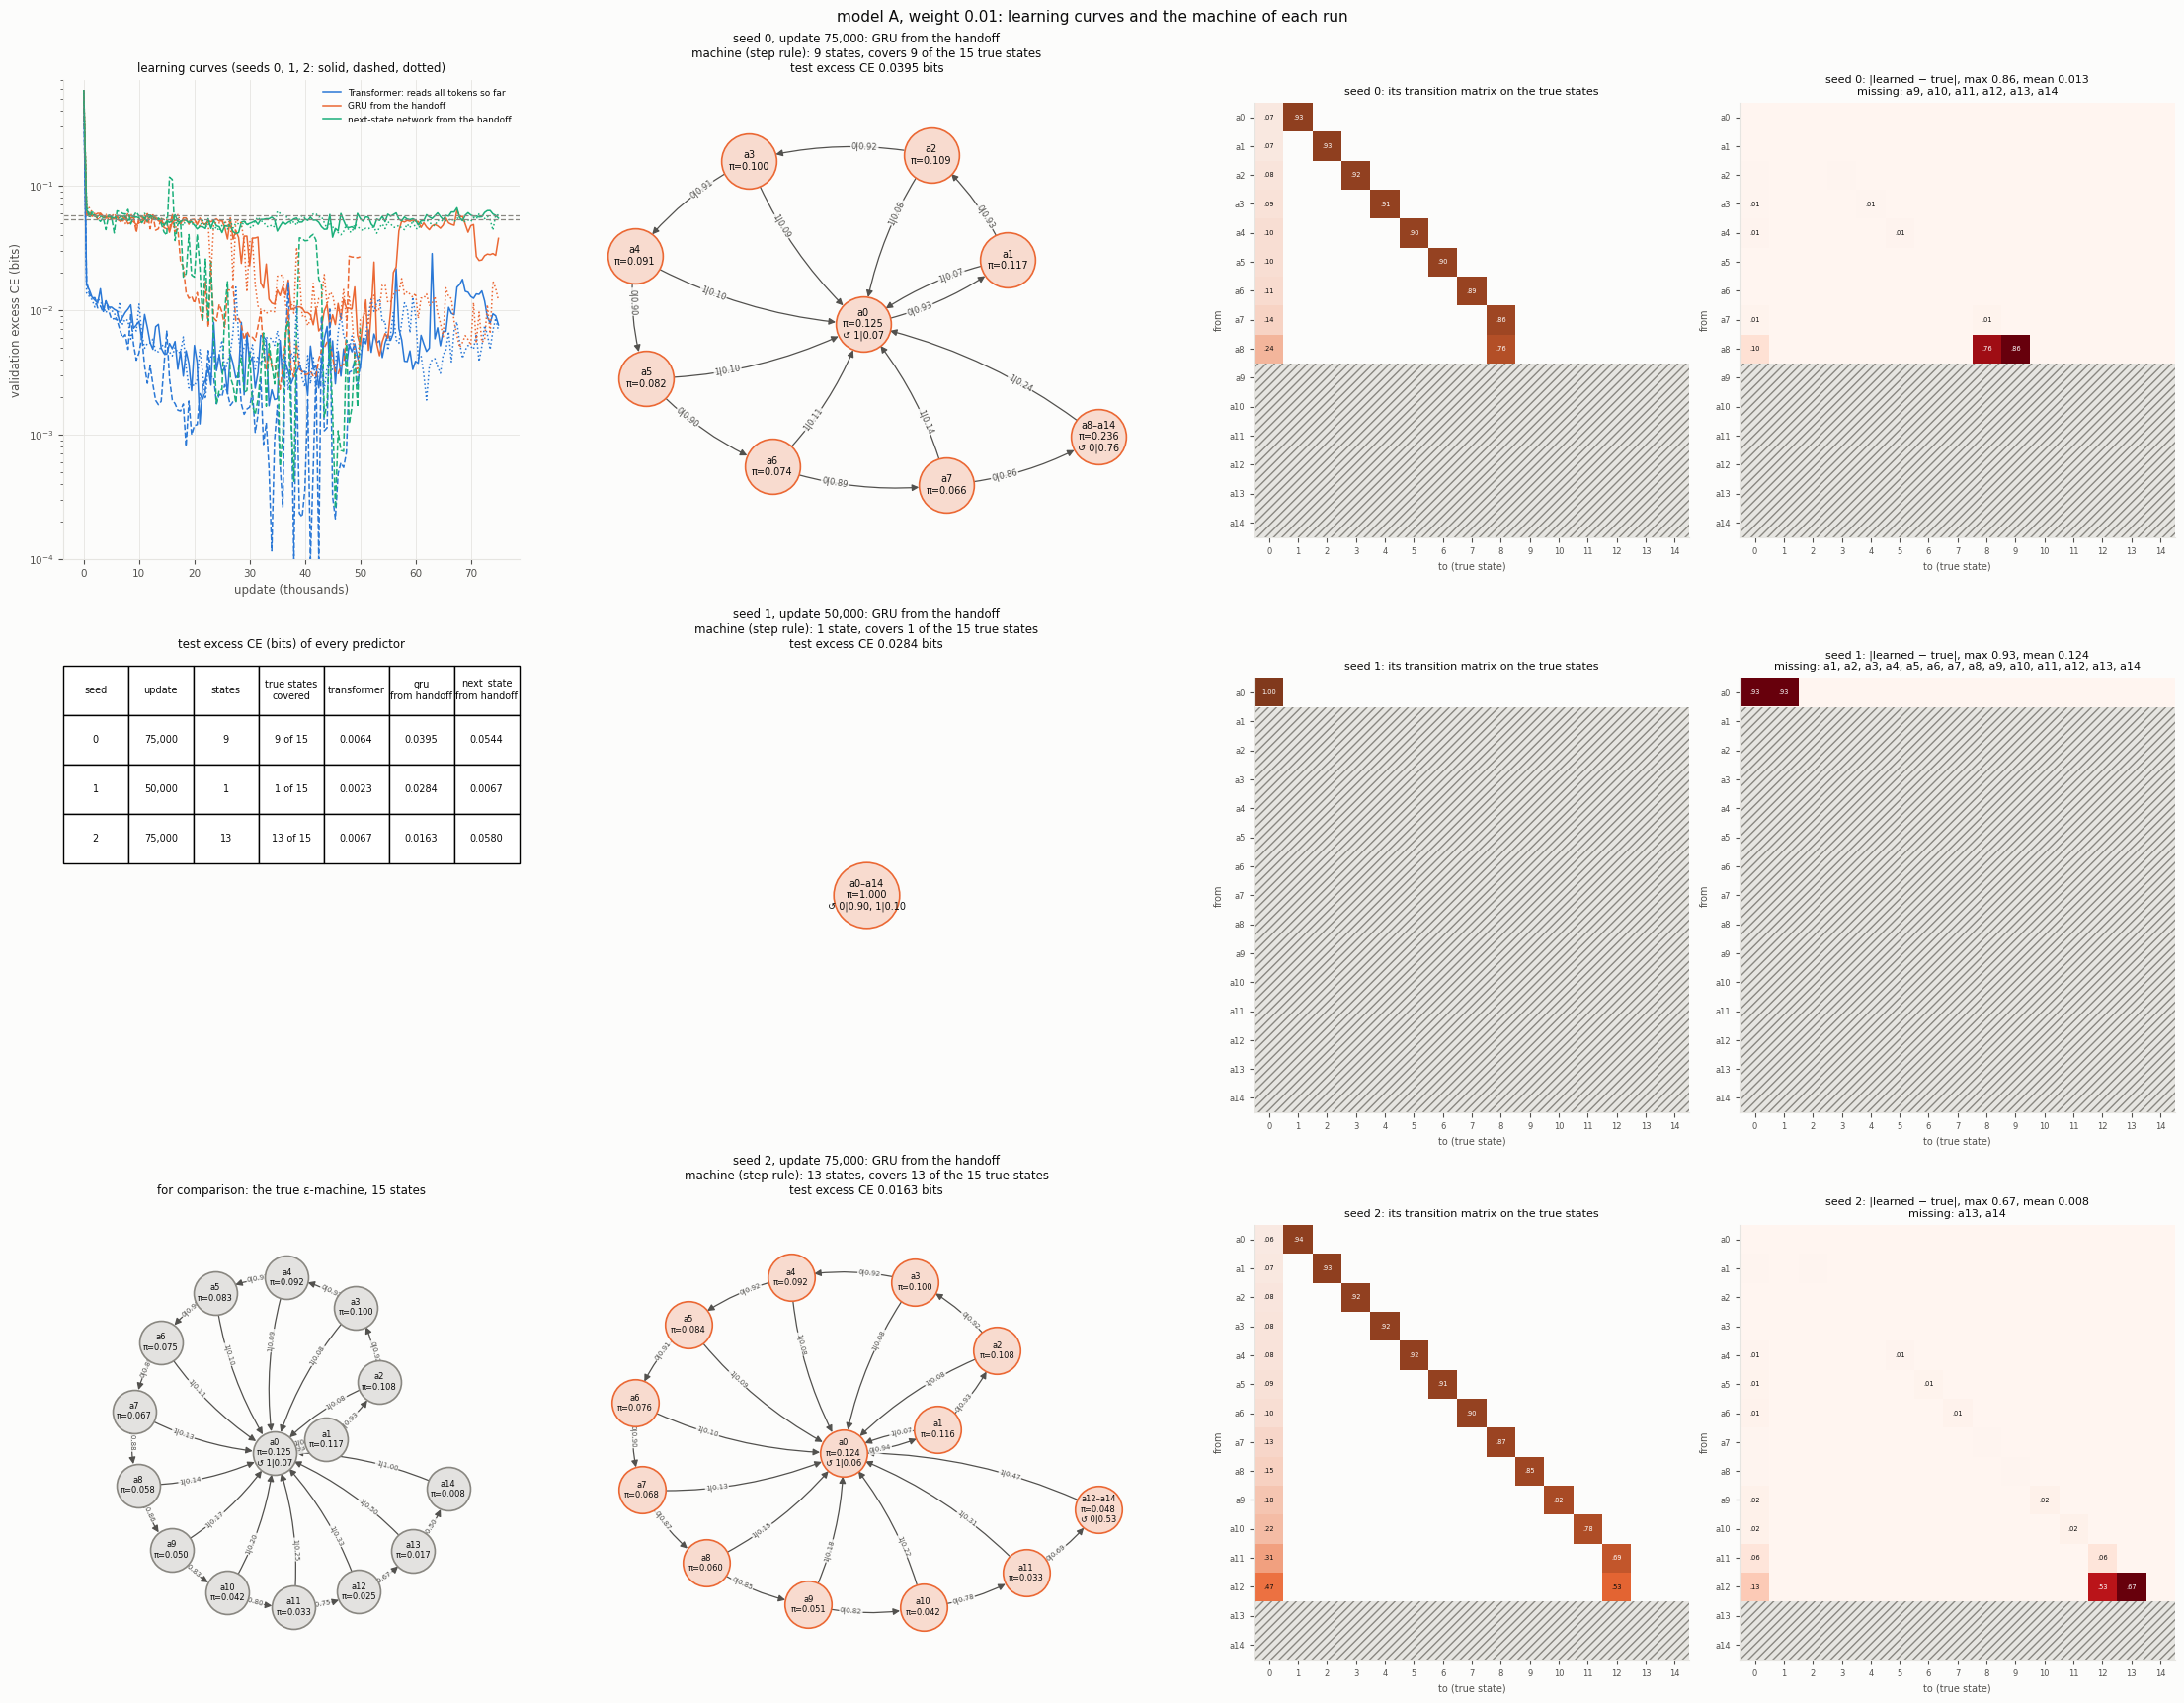

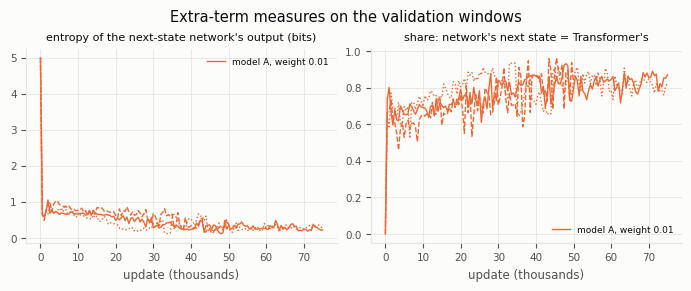

In [14]:
r = runs_of("A", "section16")
display(performance(r))
display(A.first_below(r).set_index("seed")[["final_update", "best", "best_update", "below 0.04", "below 0.02", "below 0.01"]])
fig = A.plot_machines(list(r.values())); plt.show()
fig = A.plot_extra_terms(list(r.values())); plt.show()

**What the runs show**
* **The GRU ends with 9, 1 and 13 long-run states**, at 0.0395, 0.0284 and 0.0163 bits. At their best validation updates
  they were at 0.0110, 0.0051 and 0.0036. They first fell below 0.02 bits at updates 32,000, 18,500 and 23,000.
* **On seed 1 the next-state network predicts well** (0.0067 bits), and the Transformer gives all 15 true states their
  own state, but the GRU ends with one long-run state.

### 6.8 Model B: the Transformer's starting state trained to copy the GRU's own state (`model_B.py`)

**Loss:** the GRU's future-token CE + weight × the CE of the Transformer's scores at the last history position against the
copy target, with weight 3.
* **The copy target** is the state the GRU itself reaches after reading the 40 history tokens from row 0 of the table.
* The copy term trains only the Transformer.

The extra cell shows, for seed 2, what the copy target looks like at the starting weights and at the end:
* how many different values it takes on the test windows;
* how many true states get their own value;
* how often the Transformer's starting state equals it.

* **Performance** (first table): each predictor's test excess CE over the 20 future tokens and over 200 (`long_excess`),
  the true states that get a learned state of their own, the size of each step rule's machine, and D (hybrids with a
  GRU).
* **Convergence** (second table): the best validation value of the main predictor and when it first fell below 0.04,
  0.02 and 0.01 bits (empty: never).
* **Properties** (figure): learning curves; the machine each seed ends with; its transitions on the true states; and the
  difference from the true transitions (hatched rows: true states with no learned state of their own).

,weight,update,excess_transformer_future,excess_gru_from_handoff_future,long_excess_gru_from_handoff,transformer_true_states_with_own_state,gru_from_handoff_true_states_with_own_state,gru_from_handoff_long_run_states,distance_D
seed,,,,,,,,,
0,3.0,50000,0.0643,0.0355,0.0312,1,9,9,1.1374
1,3.0,100000,0.0679,0.0117,0.0101,1,13,13,1.1962
2,3.0,100000,0.0572,0.0070,0.0059,3,14,14,1.1266


,final_update,best,best_update,below 0.04,below 0.02,below 0.01
seed,,,,,,
0,50000,0.021080,35000,27500,NaN,NaN
1,100000,0.008862,100000,32000,58000.0,99000.0
2,100000,0.000118,95000,34500,45000.0,65500.0


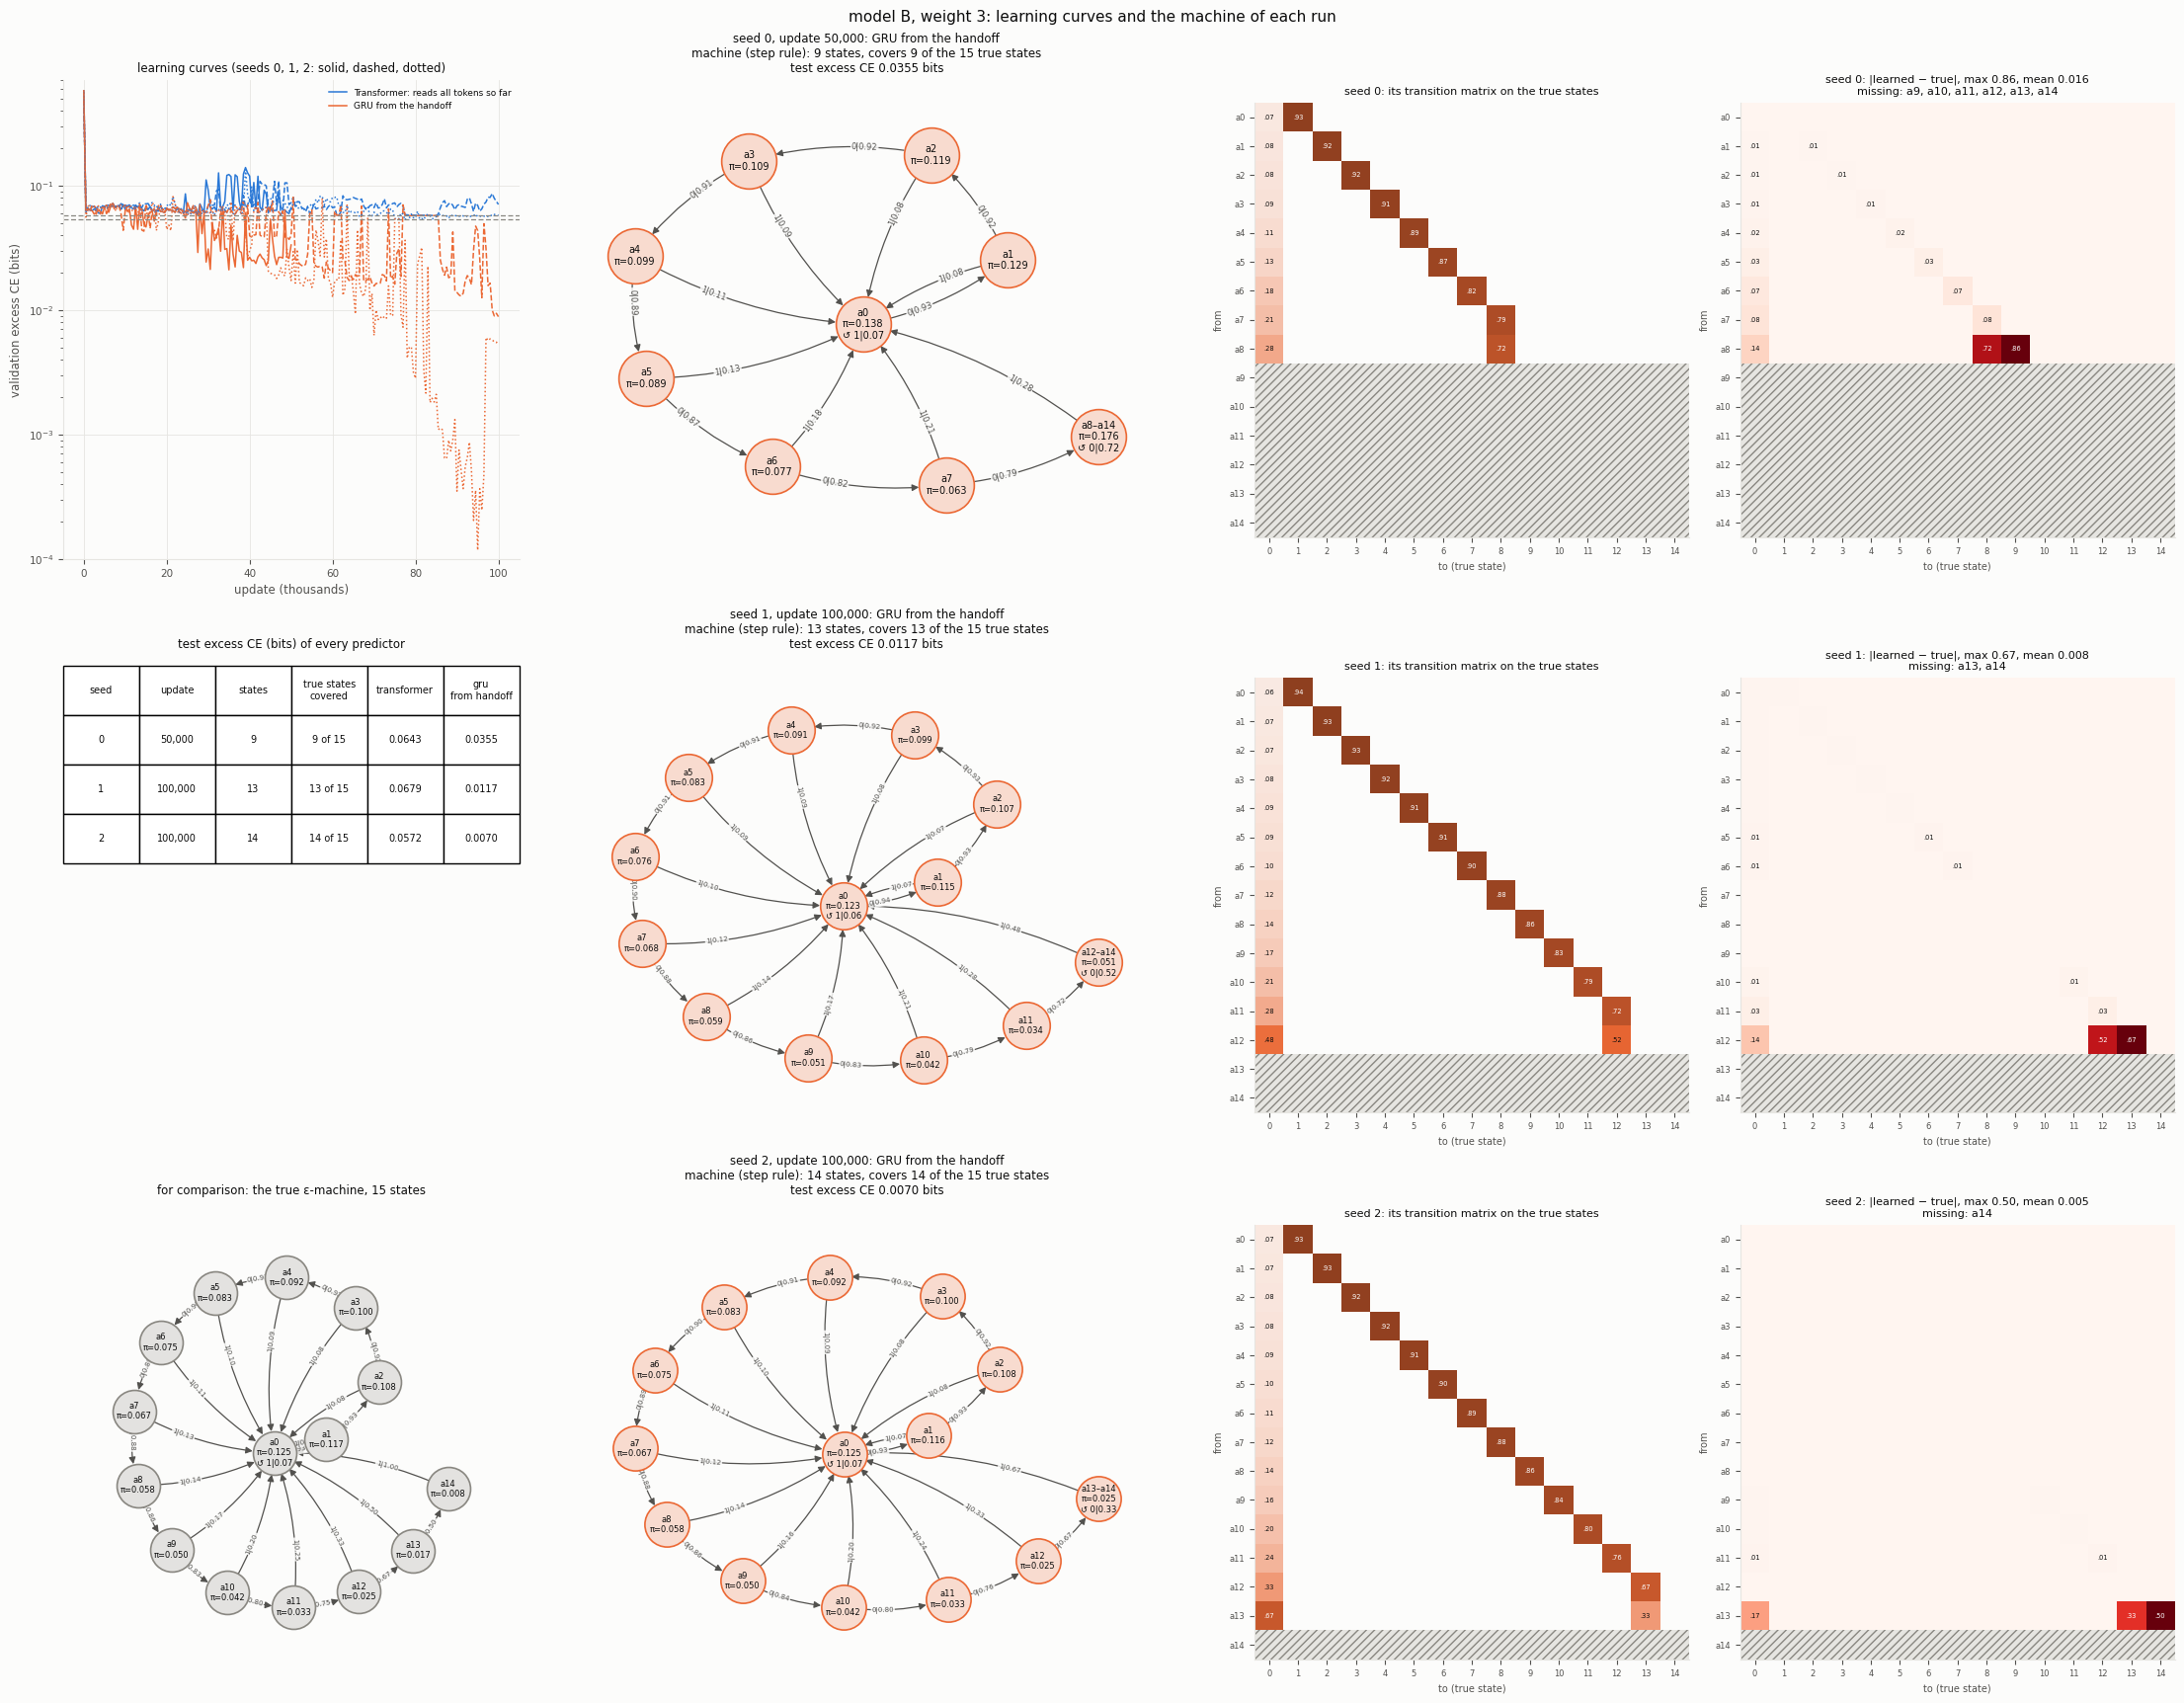

,parameters,target_values,true_states_with_own_target,start_equals_target
0,starting weights,1,1,0.0
1,"update 100,000",14,14,1.0


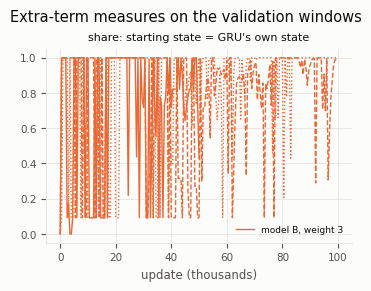

In [15]:
r = runs_of("B", "section16")
display(performance(r))
display(A.first_below(r).set_index("seed")[["final_update", "best", "best_update", "below 0.04", "below 0.02", "below 0.01"]])
fig = A.plot_machines(list(r.values())); plt.show()
display(A.copy_target_stats(runs[("B", "section16", 2)]))
fig = A.plot_extra_terms(list(r.values())); plt.show()

**What the runs show**
* **The GRU ends with 9, 13 and 14 long-run states**, covering the same numbers of true states, at 0.0355, 0.0117 and
  0.0070 bits.
* **Seed 2 reached 0.0004 bits** at its best validation update (95,000). Seeds 1 and 2 first fell below 0.02 bits at
  updates 58,000 and 45,000.
* **The Transformer's own predictions are not trained** except at the last history position: 0.0572–0.0679 bits.

### 6.9 Model C: model 5b with the next state worked out from two predicted tokens (`model_C.py`)

**Loss:** the Transformer's one-, two- and three-step CE + weight × the entropy of the inferred next state, with weight
0.01. Here each candidate state is identified by its predicted next two tokens. `model_C.py` lists the three ways it
differs from 5b.

* **Performance** (first table): each predictor's test excess CE over the 20 future tokens and over 200 (`long_excess`),
  the true states that get a learned state of their own, the size of each step rule's machine, and D (hybrids with a
  GRU).
* **Convergence** (second table): the best validation value of the main predictor and when it first fell below 0.04,
  0.02 and 0.01 bits (empty: never).
* **Properties** (figure): learning curves; the machine each seed ends with; its transitions on the true states; and the
  difference from the true transitions (hatched rows: true states with no learned state of their own).

,weight,update,excess_transformer_future,transformer_true_states_with_own_state
seed,,,,
0,0.01,50000,0.0019,13
1,0.01,50000,0.0070,13
2,0.01,50000,0.0002,14


,final_update,best,best_update,below 0.04,below 0.02,below 0.01
seed,,,,,,
0,50000,-0.000225,35500,500,500,2000
1,50000,0.005654,41500,500,500,1500
2,50000,-0.000275,34500,500,500,1000


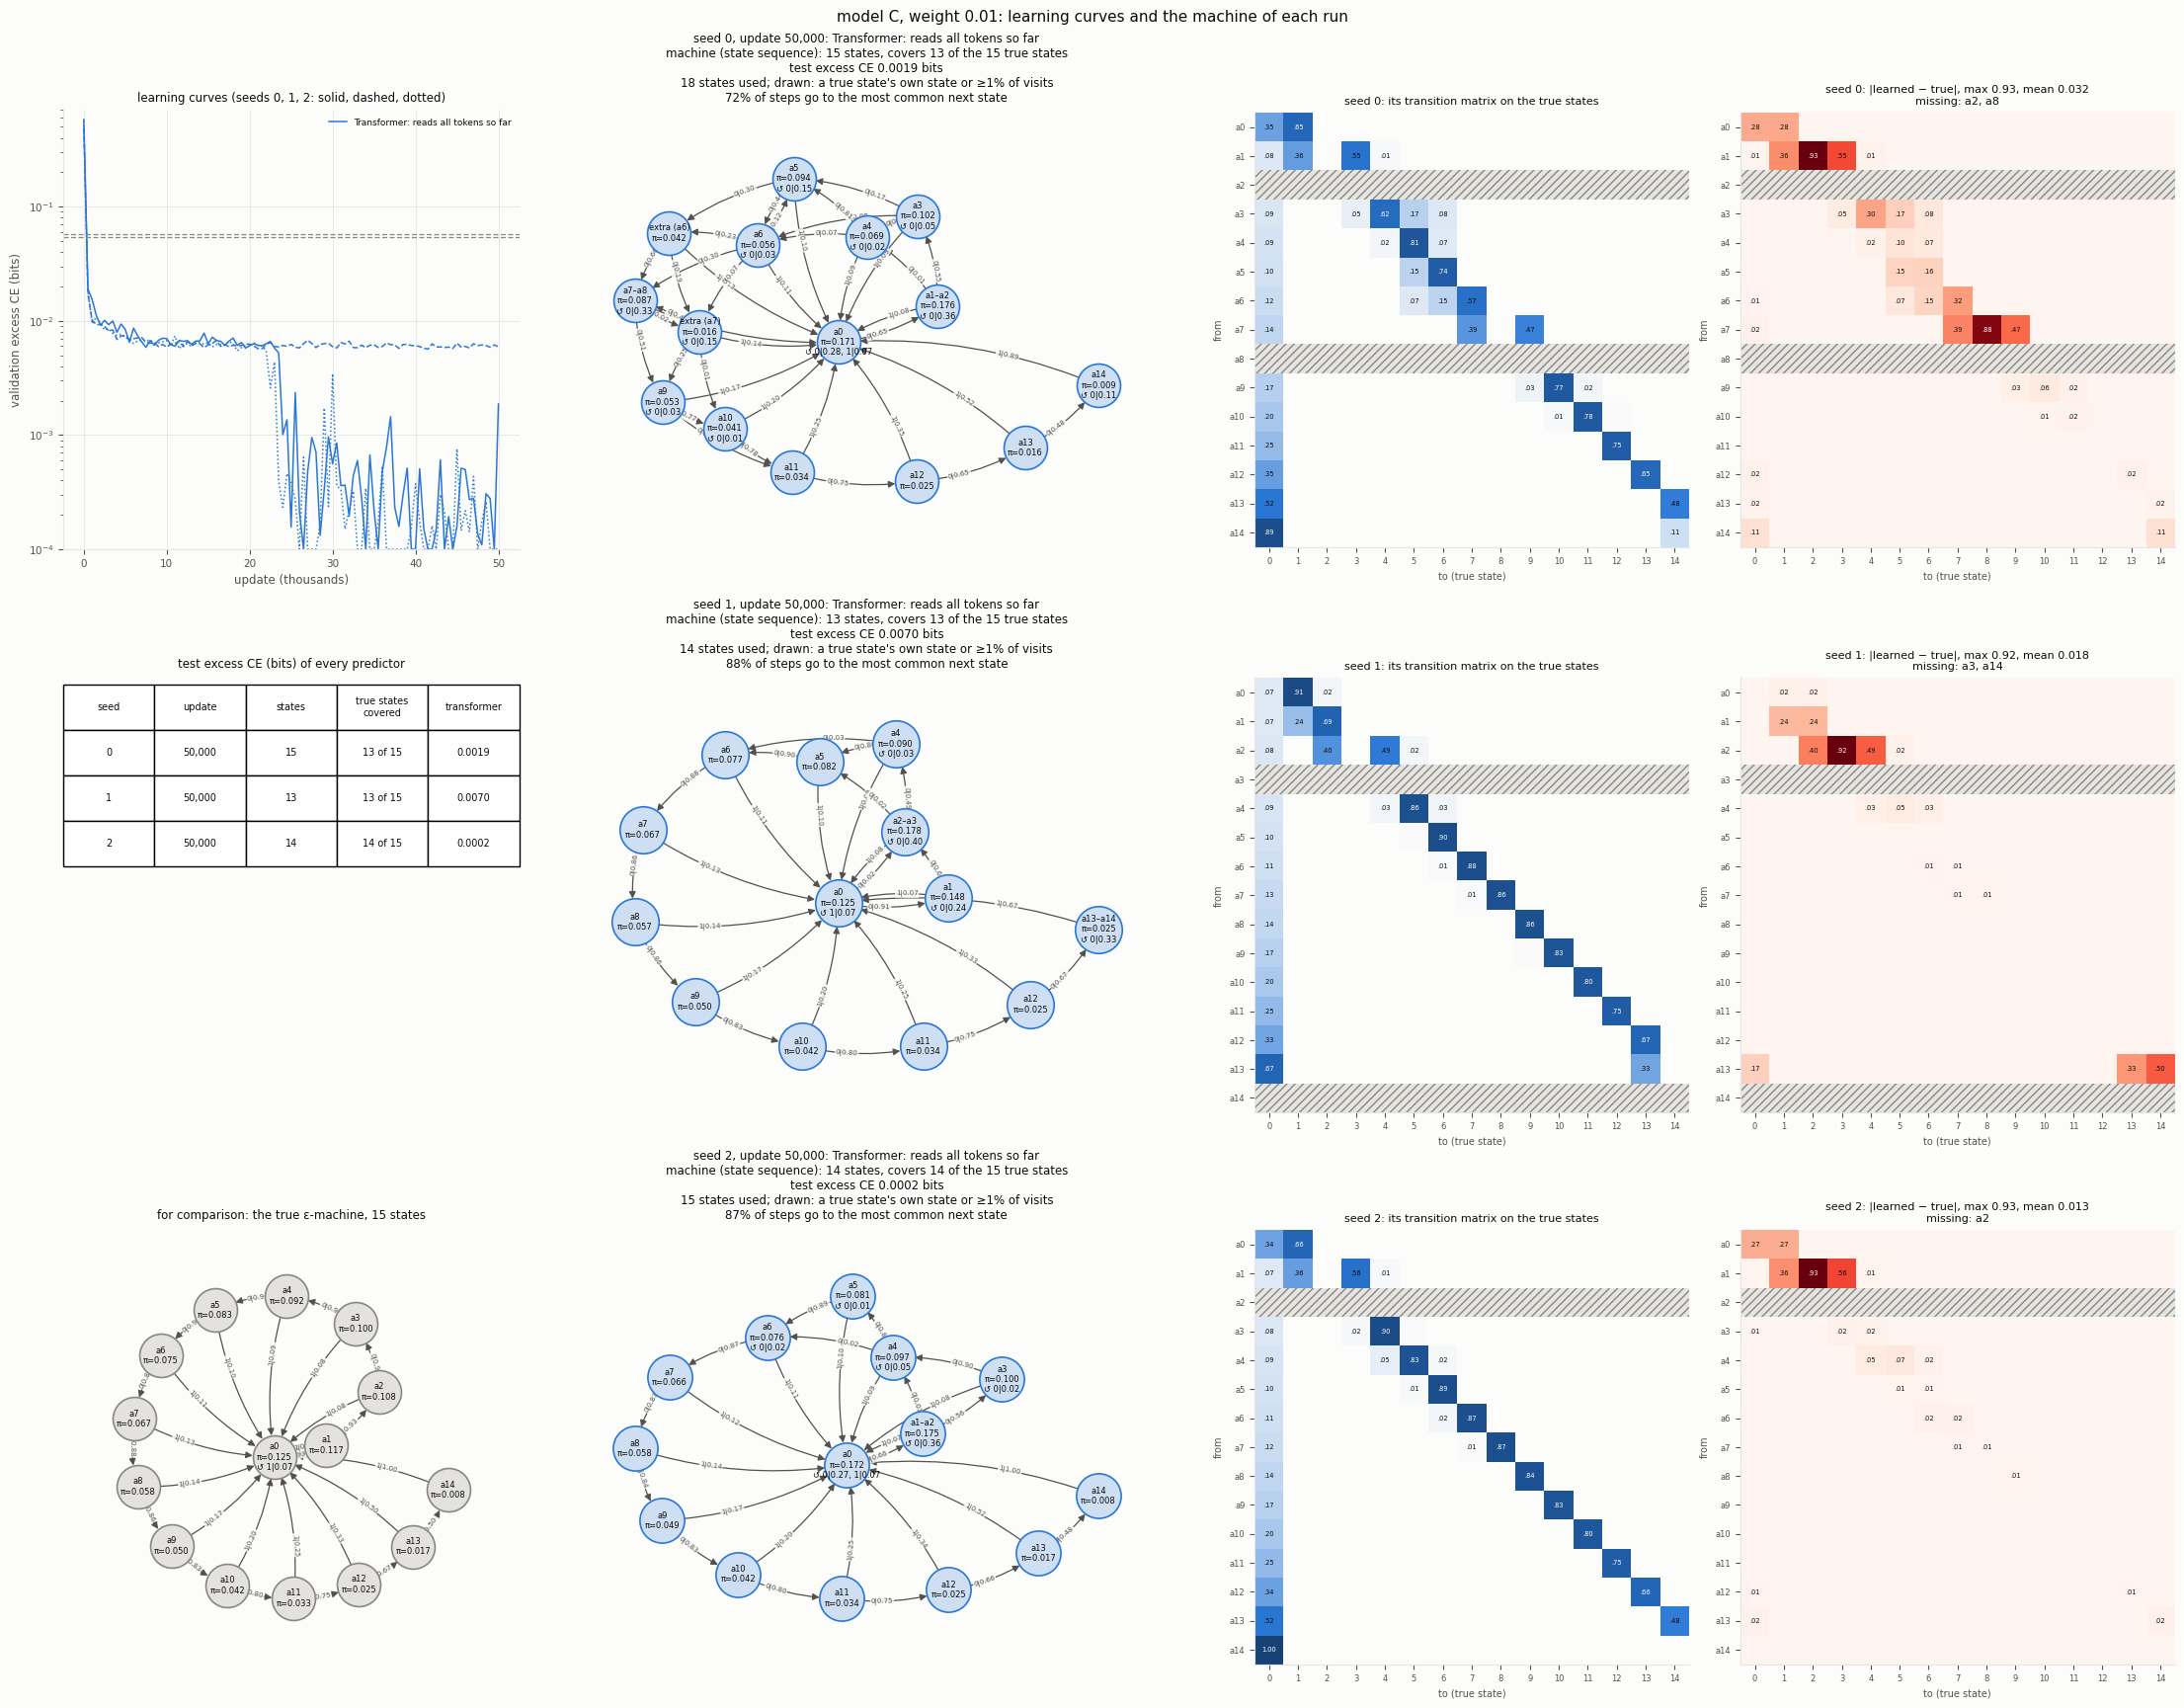

true_machine_entropy      3.6571
crypticity                3.2363
statistical_complexity    3.6706
excess_entropy            0.4342
dtype: float64

In [16]:
r = runs_of("C", "section16")
display(performance(r))
display(A.first_below(r).set_index("seed")[["final_update", "best", "best_update", "below 0.04", "below 0.02", "below 0.01"]])
fig = A.plot_machines(list(r.values())); plt.show()
display(pd.Series(A.inferred_entropy_on_true_machine(settings, 2)).round(4))

**What the runs show**
* **The Transformer's predictions** are at 0.0019, 0.0070 and 0.0002 bits. They first fell below 0.01 bits at updates
  1,000–2,000.
* **Its machine has 15, 13 and 14 states**, covering 13, 13 and 14 true states. Its transitions differ from the true
  ones by 0.0322, 0.0182 and 0.0132 on average.
* **On the true machine the penalty is 3.6571 bits** from two tokens, against 3.6645 from one.

### 6.10 Model 1 + L2: section 13's run (`model_1_L2.py`)

**Loss:** the GRU's future-token CE + weight × D, the distance between the Transformer's and the GRU's state
probabilities after each future token, with weight 0.03.

There is one run: section 13's, with 300 history and 40 future tokens, the original setup, and 50,000 updates. Section
13 saved no best-validation parameters, so the convergence table has none.

* **Performance** (first table): each predictor's test excess CE over the 20 future tokens and over 200 (`long_excess`),
  the true states that get a learned state of their own, the size of each step rule's machine, and D (hybrids with a
  GRU).
* **Convergence** (second table): the best validation value of the main predictor and when it first fell below 0.04,
  0.02 and 0.01 bits (empty: never).
* **Properties** (figure): learning curves; the machine each seed ends with; its transitions on the true states; and the
  difference from the true transitions (hatched rows: true states with no learned state of their own).

,weight,update,excess_transformer_future,excess_gru_from_handoff_future,long_excess_gru_from_handoff,transformer_true_states_with_own_state,gru_from_handoff_true_states_with_own_state,gru_from_handoff_long_run_states,distance_D
seed,,,,,,,,,
0,0.03,50000,0.0511,0.0511,0.0517,1,2,2,0.0


,final_update,best,best_update,below 0.04,below 0.02,below 0.01
seed,,,,,,
0,50000,0.046747,4250,None,None,None


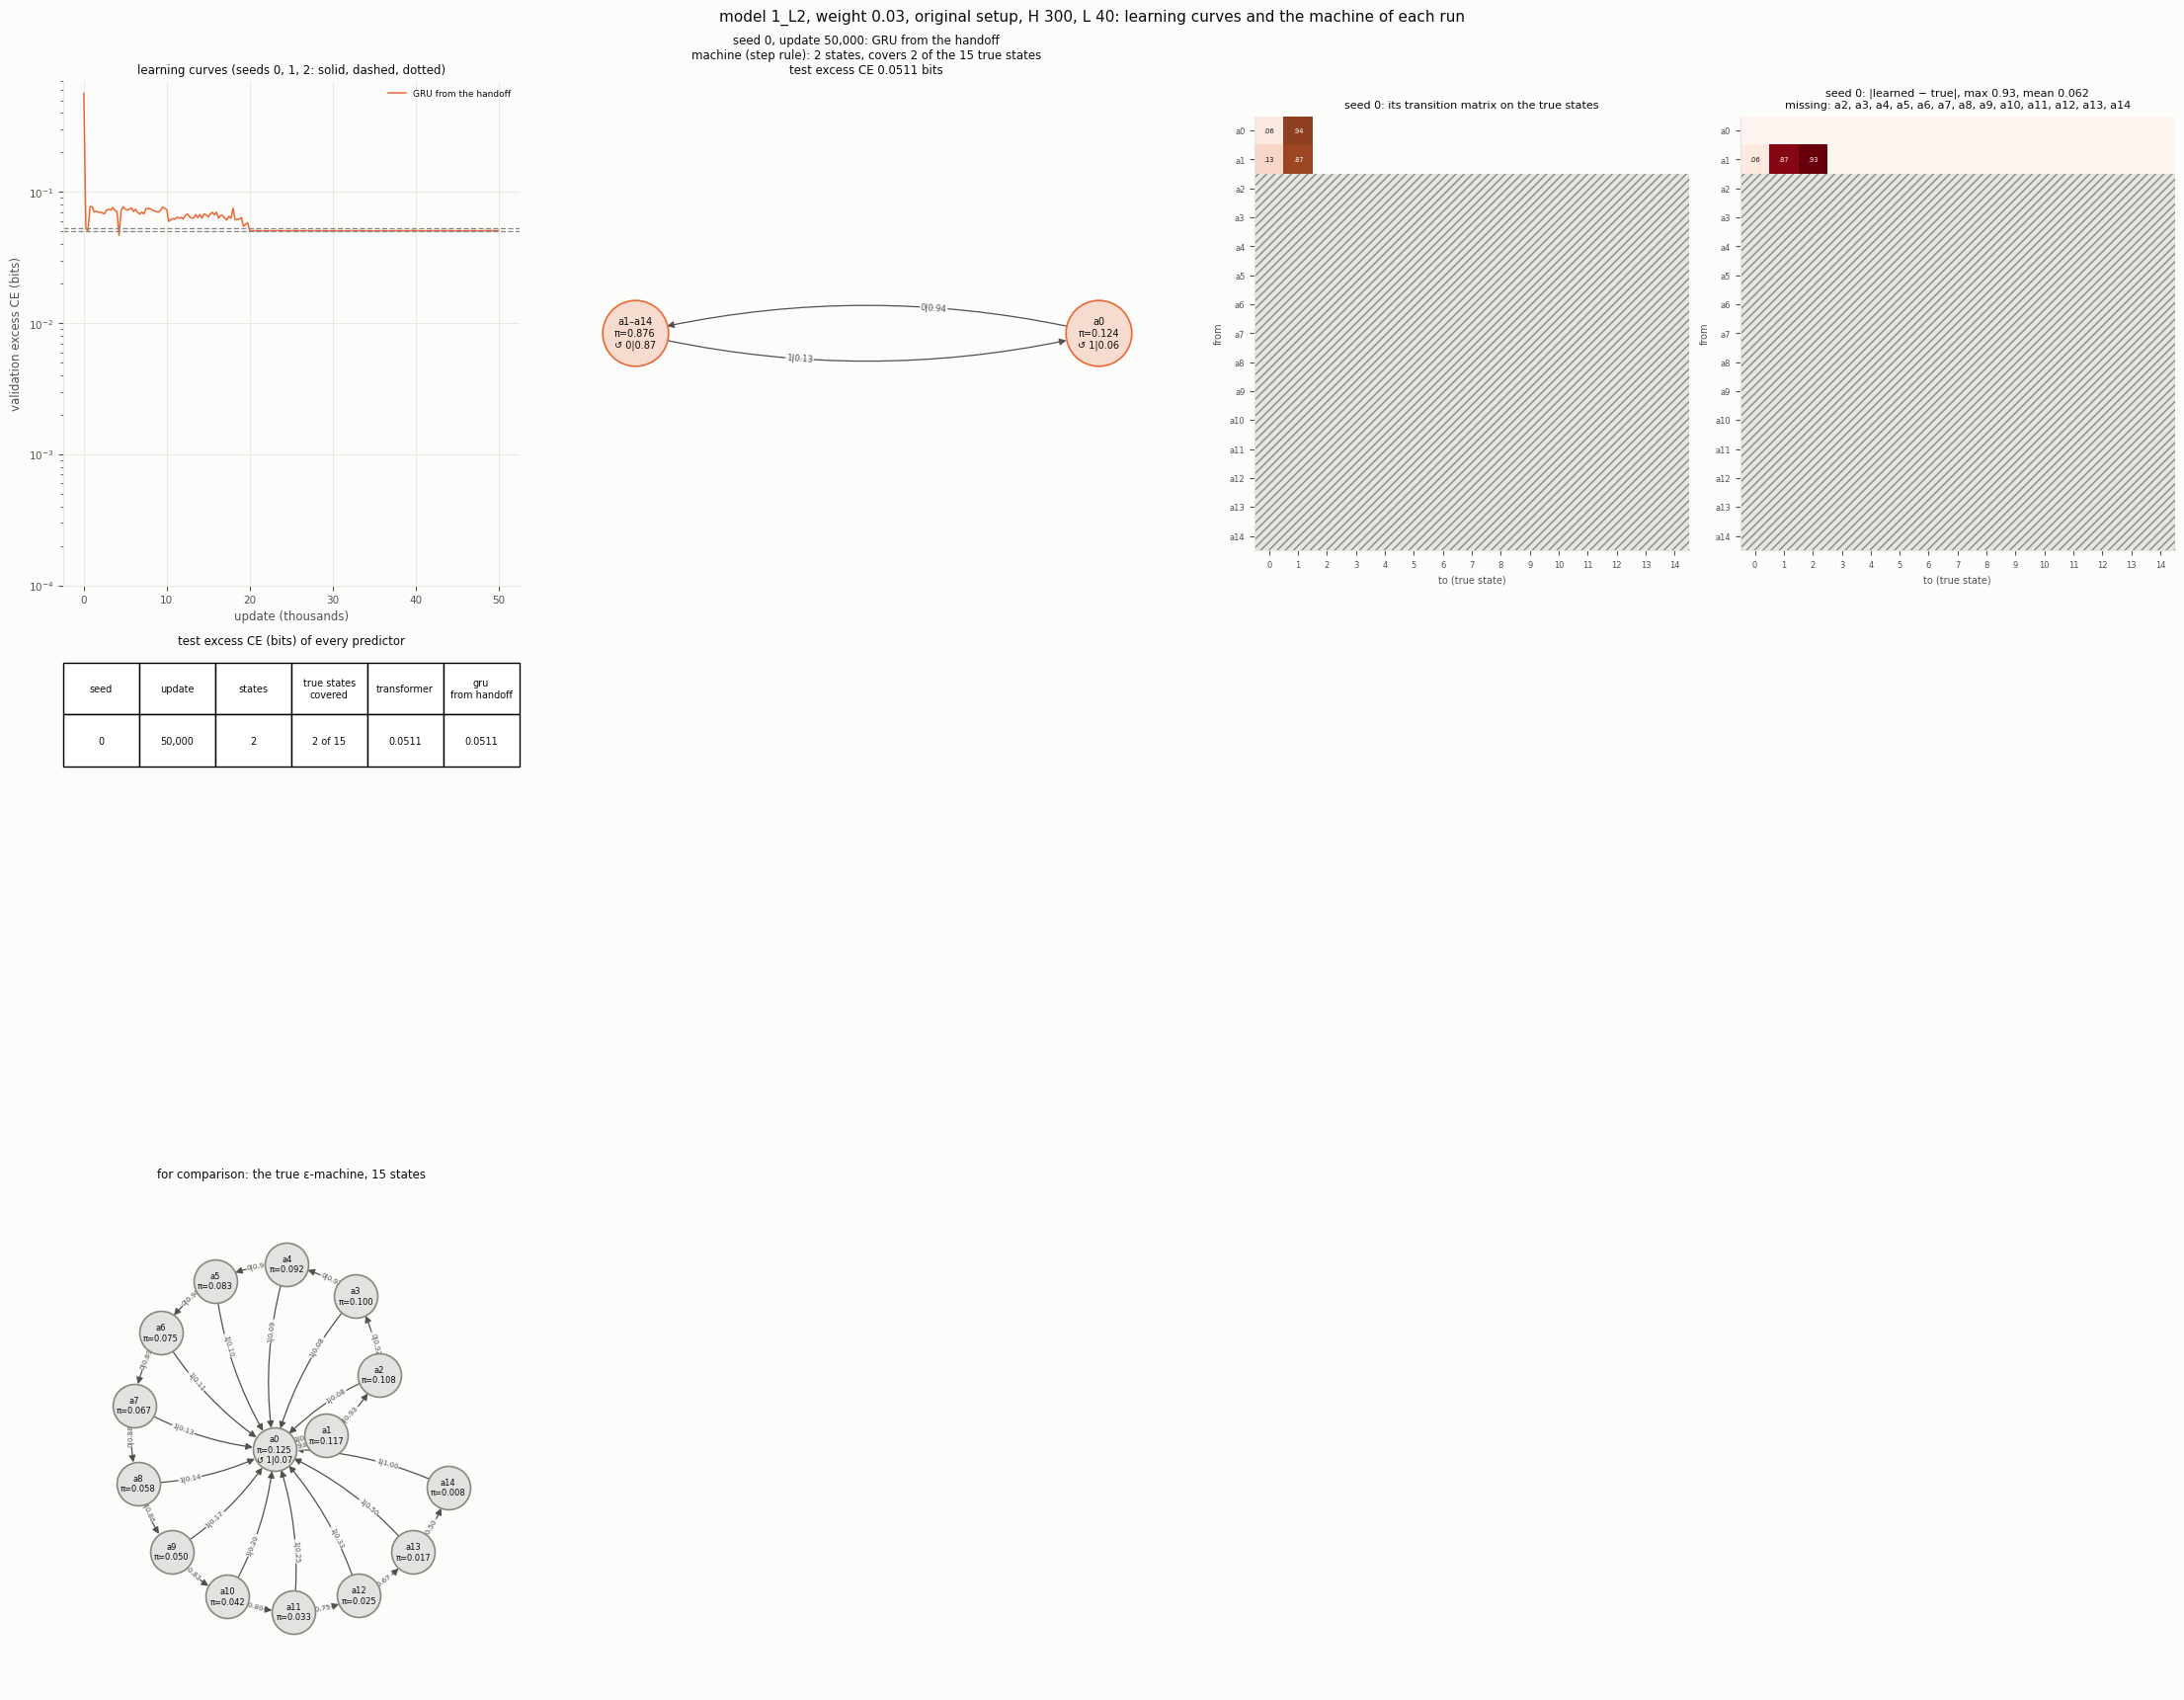

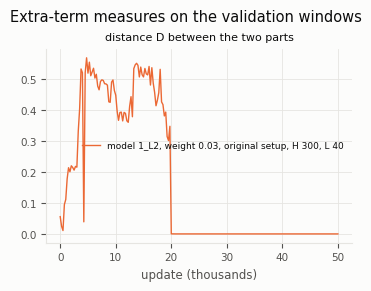

In [17]:
r = runs_of("1_L2", "section13")
display(performance(r))
display(A.first_below(r).set_index("seed")[["final_update", "best", "best_update", "below 0.04", "below 0.02", "below 0.01"]])
fig = A.plot_machines(list(r.values())); plt.show()
fig = A.plot_extra_terms(list(r.values())); plt.show()

**What the run shows:** the GRU and the Transformer both end at 0.0511 bits with D = 0. Both use the same 2 states,
which follow the last token only (2 long-run states covering 2 true states).

### 6.11 Model 2 + L2: weights 0.01, 0.03 and 0.1 (`model_2_L2.py`)

**Loss:** model 2's + weight × D over the GRU's 19 steps (section 17). The next cells show four things:
* the test results of all nine runs;
* the learning curves and D over training;
* the machines at weight 0.03;
* for seed 0 of each weight, and of model 2 without the term, how often the GRU picks the same state as the Transformer,
  and how certain each part is (`A.state_agreement`).

,weight,update,excess_transformer_future,excess_gru_from_handoff_future,long_excess_gru_from_handoff,transformer_true_states_with_own_state,gru_from_handoff_true_states_with_own_state,gru_from_handoff_long_run_states,distance_D
seed,,,,,,,,,
0,0.01,50000,0.0050,0.0428,0.0565,7,1,1,0.1814
1,0.01,75000,0.0063,0.0446,0.0560,7,1,1,0.1576
2,0.01,75000,0.0074,0.0165,0.0137,13,13,13,0.0829
0,0.03,50000,0.0094,0.0431,0.0559,6,1,1,0.0836
1,0.03,50000,0.0094,0.0449,0.0568,6,1,1,0.0827
2,0.03,50000,0.0089,0.0445,0.0569,7,1,1,0.0861
0,0.10,50000,0.0172,0.0481,0.0553,9,1,1,0.0292
1,0.10,50000,0.0158,0.0443,0.0564,5,1,1,0.0289
2,0.10,50000,0.0165,0.0455,0.0560,7,1,1,0.0268


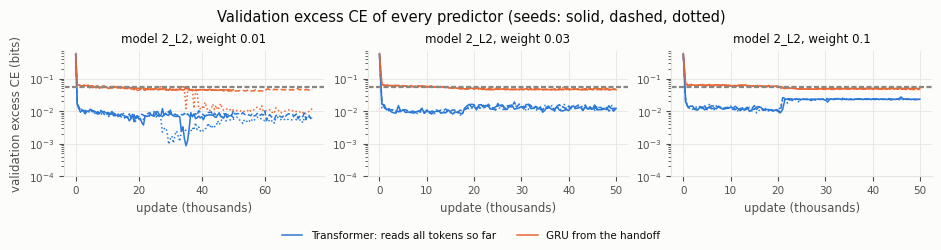

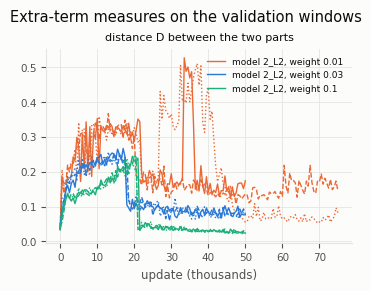

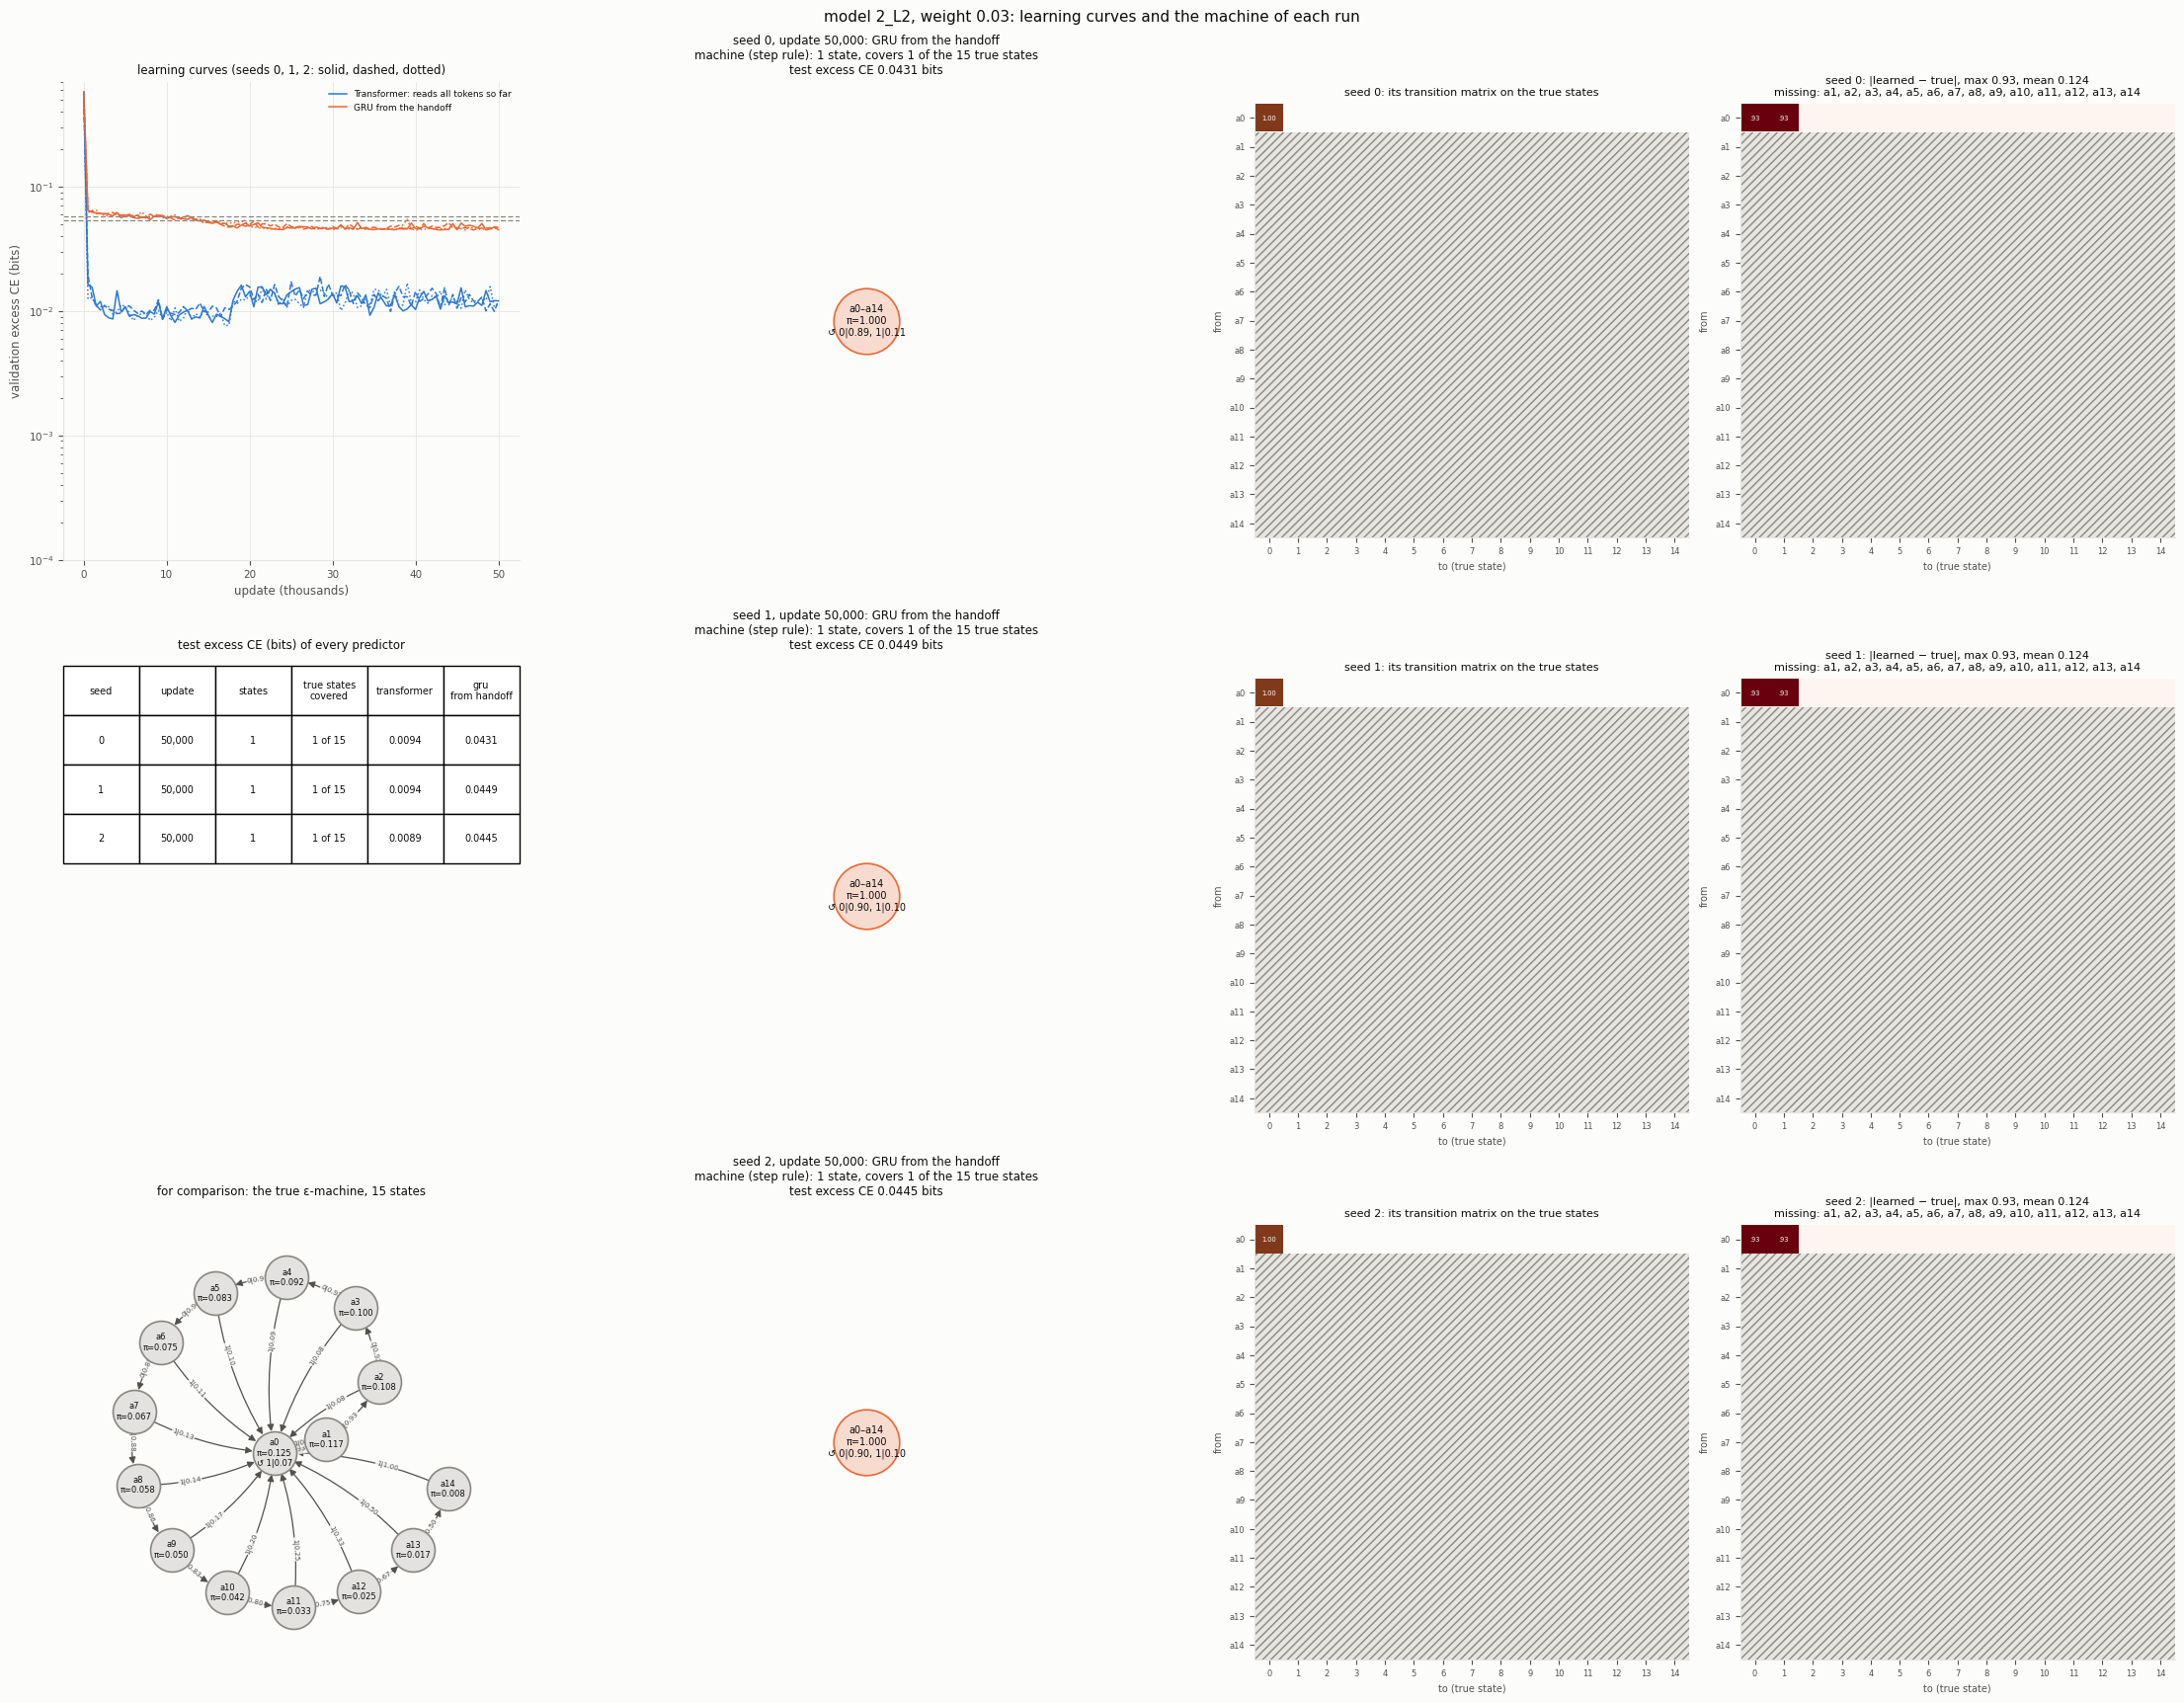

,same_state,distance_D,largest_probability_transformer,largest_probability_gru
2 section16 s0,0.503,0.702,0.988,0.998
2_L2 w0.01 s0,0.851,0.181,0.942,1.000
2_L2 w0.03 s0,0.935,0.083,0.972,1.000
2_L2 w0.1 s0,0.979,0.028,0.992,1.000


In [18]:
r = runs_of("2_L2")
display(performance(r).sort_values(["weight", "seed"]))
fig = A.plot_learning_curves(list(r.values())); plt.show()
fig = A.plot_extra_terms(list(r.values())); plt.show()
fig = A.plot_machines(list(runs_of("2_L2", "w0.03").values())); plt.show()
display(pd.DataFrame({f"{m} {l} s{s}": A.state_agreement(runs[(m, l, s)])
                      for m, l, s in [("2", "section16", 0), ("2_L2", "w0.01", 0), ("2_L2", "w0.03", 0),
                                      ("2_L2", "w0.1", 0)]}).T.round(3))

**What the runs show**
* **At weight 0.01** the GRU ends with one long-run state on seeds 0 and 1 (0.0428, 0.0446 bits) and 13 on seed 2
  (0.0165).
* **At weights 0.03 and 0.1** every GRU ends with one long-run state, at 0.0431–0.0481 bits. Model 2 without the term
  ended with 15, 1 and 11.
* **The Transformer's own predictions get worse as the weight grows:** 0.0050–0.0074 bits at 0.01, 0.0089–0.0094 at 0.03
  and 0.0158–0.0172 at 0.1, against 0.0005–0.0076 without the term.
* **Agreement is not learning the count.** With the term, the GRU picks the same state as the Transformer at most future
  positions (last table; both parts are nearly certain of their choice), so D is small. But the GRU's own machine is a
  single state.

### 6.12 The feedback GRU alone (`model_feedback_GRU.py`)

**The model:** at every position a GRU computes a proposal from (the previous state's vector, the token). Its scoring
layer picks a state, and that state's vector is fed back. It starts blank at every window and is trained on its own
next-token predictions. There is no Transformer, so its state after the 40 history tokens comes from its own reading.

* **Performance** (first table): each predictor's test excess CE over the 20 future tokens and over 200 (`long_excess`),
  the true states that get a learned state of their own, the size of each step rule's machine, and D (hybrids with a
  GRU).
* **Convergence** (second table): the best validation value of the main predictor and when it first fell below 0.04,
  0.02 and 0.01 bits (empty: never).
* **Properties** (figure): learning curves; the machine each seed ends with; its transitions on the true states; and the
  difference from the true transitions (hatched rows: true states with no learned state of their own).

,weight,update,excess_gru_from_start_future,long_excess_gru_from_start,gru_from_start_true_states_with_own_state,gru_from_start_long_run_states
seed,,,,,,
0,0.0,50000,0.0001,0.0002,15,15
1,0.0,50000,0.0001,0.0002,15,16
2,0.0,50000,0.0002,0.0001,15,15


,final_update,best,best_update,below 0.04,below 0.02,below 0.01
seed,,,,,,
0,50000,-0.000126,38000,22500,25000,26500
1,50000,-0.000205,39500,12000,25000,26500
2,50000,-0.000172,44500,17000,17500,19500


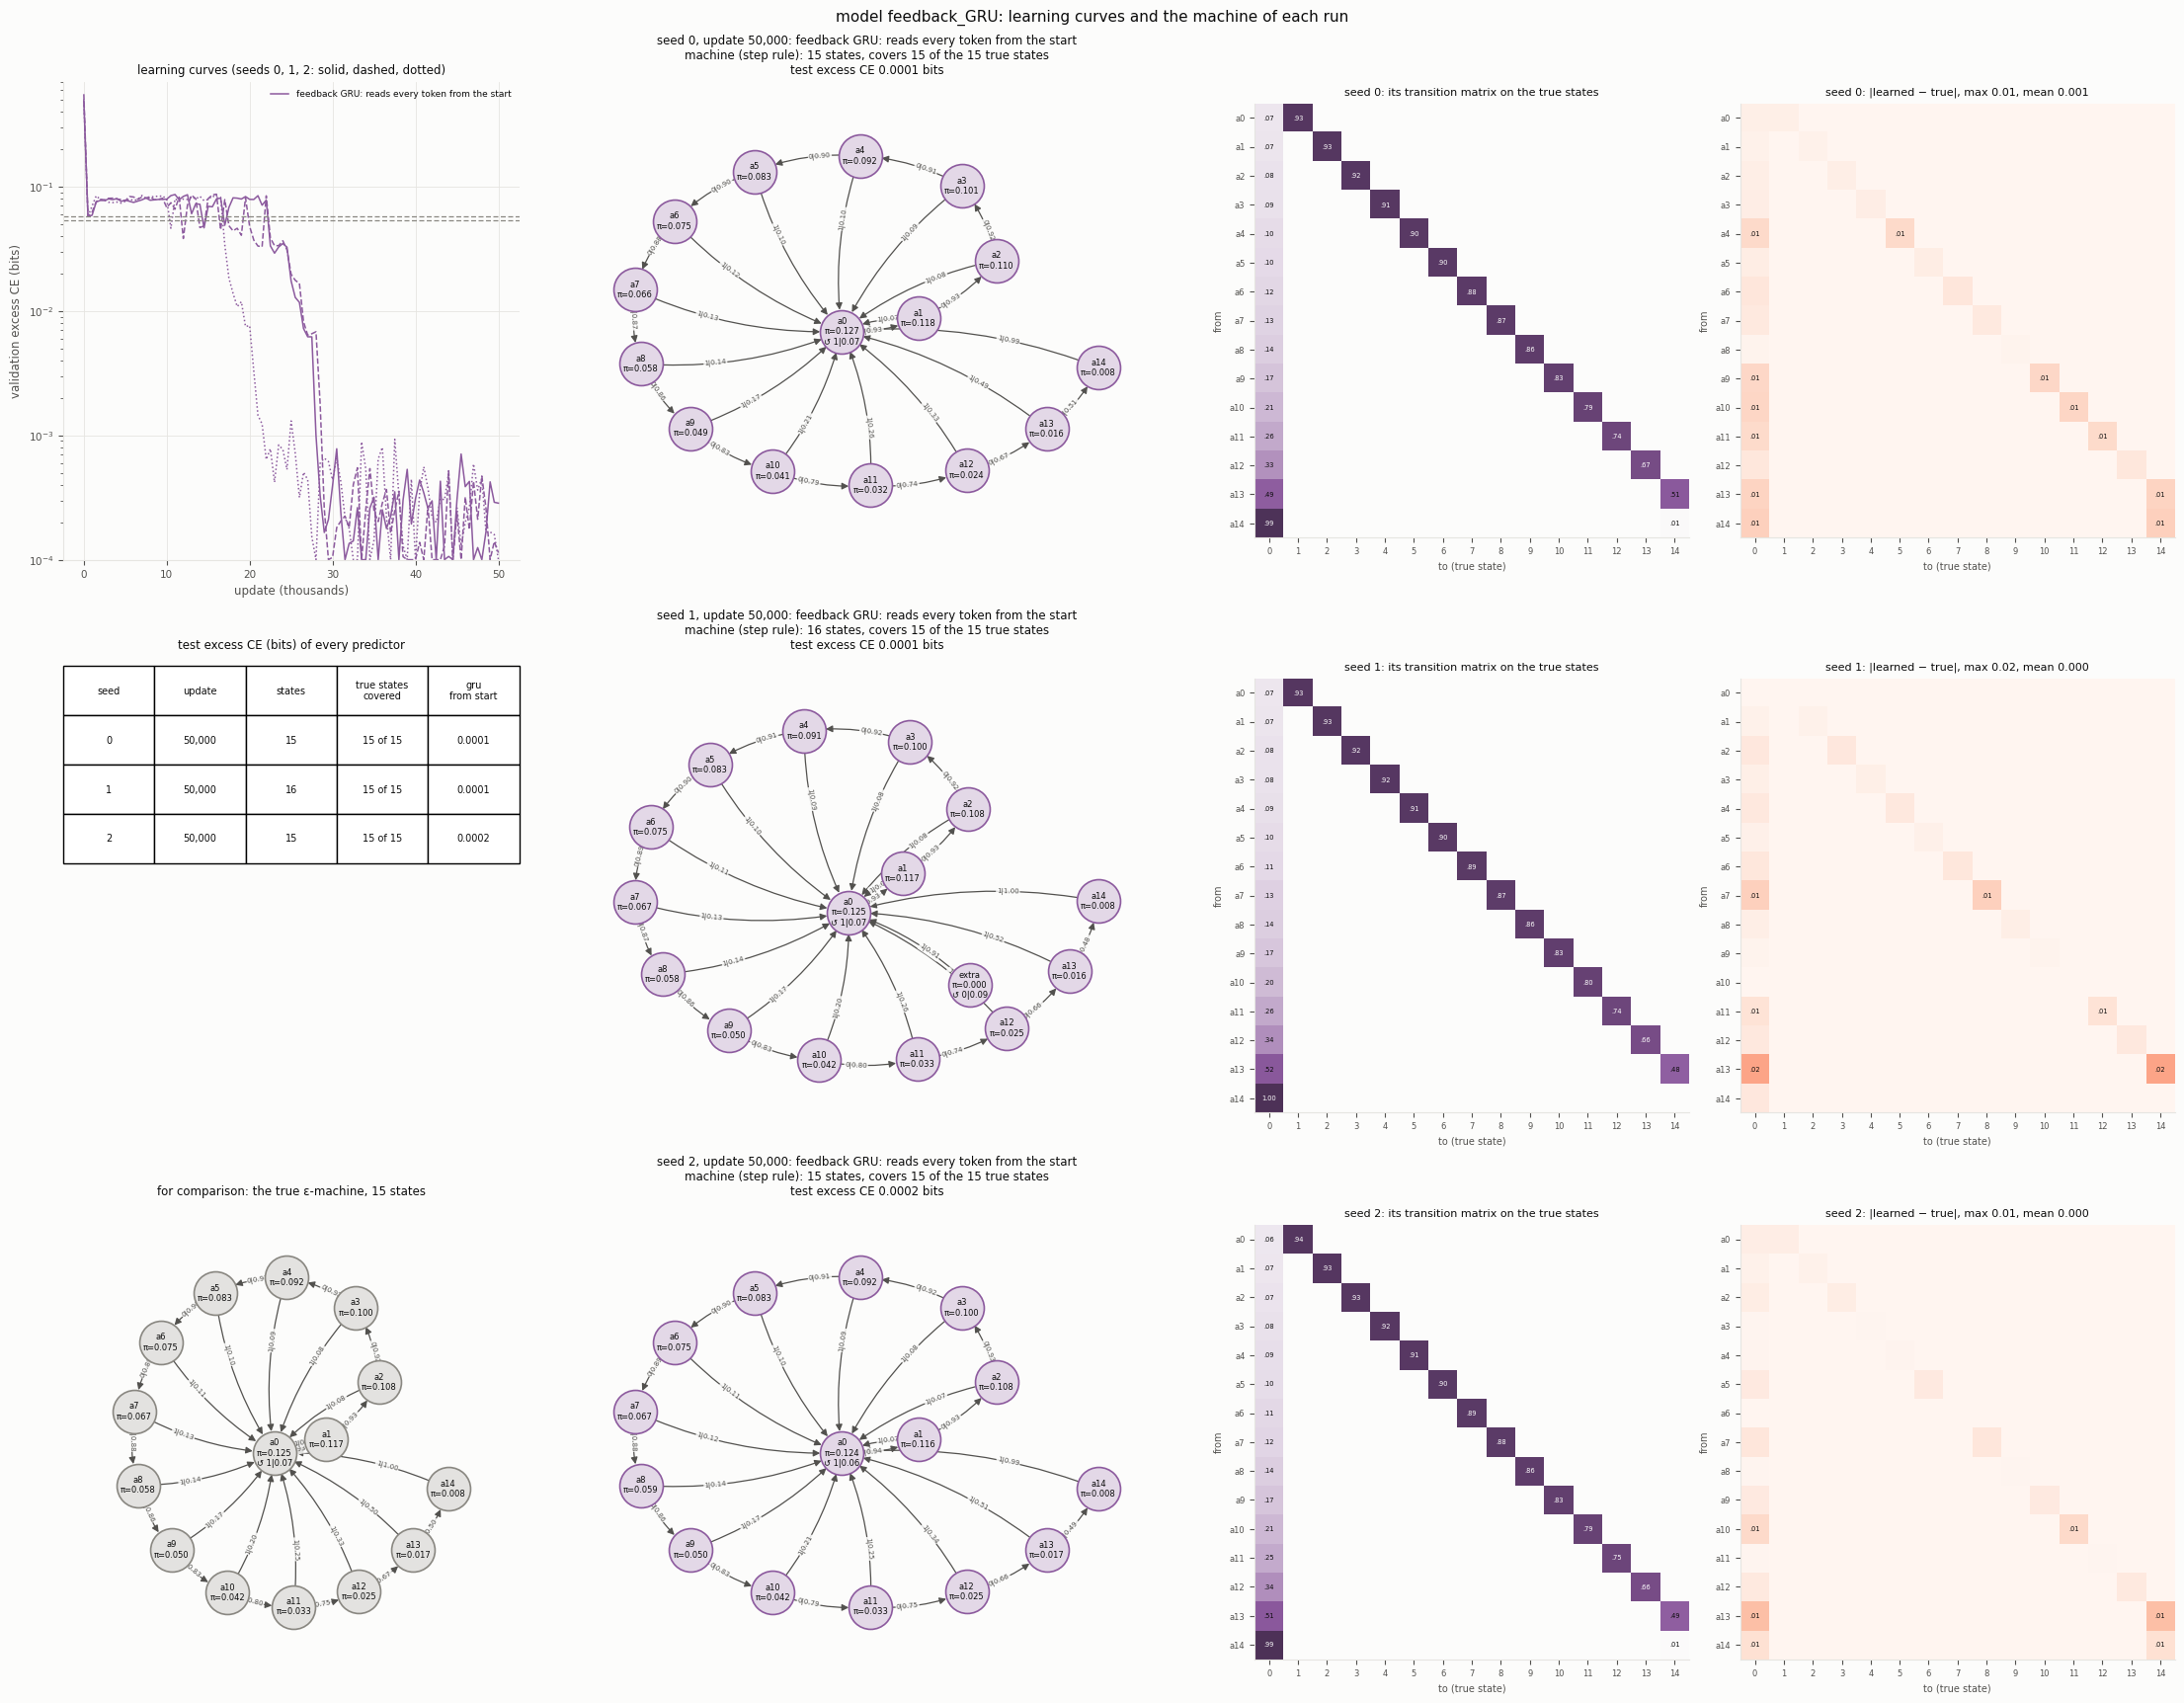

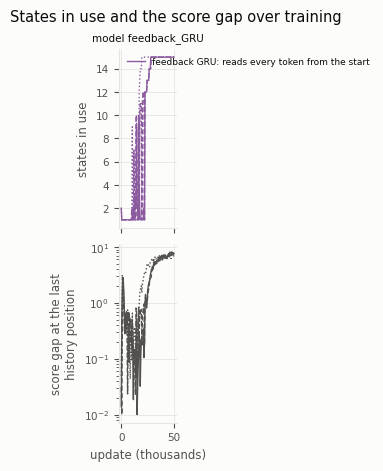

In [19]:
r = runs_of("feedback_GRU", "section17")
display(performance(r))
display(A.first_below(r).set_index("seed")[["final_update", "best", "best_update", "below 0.04", "below 0.02", "below 0.01"]])
fig = A.plot_machines(list(r.values())); plt.show()
fig = A.plot_states_over_training(list(r.values())); plt.show()

**What the runs show:** it learns the true machine on every seed.
* Its machine has 15, 16 and 15 long-run states, covering all 15 true states. Its transitions differ from the true ones
  by 0.0004–0.0006 on average.
* Test excess 0.0001, 0.0001 and 0.0002 bits, and 0.0001–0.0002 over 200 tokens.
* It first fell below 0.01 bits between updates 19,500 and 26,500.

### 6.13 The discrete Transformer alone (`model_discrete_Transformer.py`)

**The model:** a Transformer that picks a state at every position and predicts the next token from it. It is trained on
its own next-token predictions. Its machine is read off the states it picks, so it need not be deterministic.

* **Performance** (first table): each predictor's test excess CE over the 20 future tokens and over 200 (`long_excess`),
  the true states that get a learned state of their own, the size of each step rule's machine, and D (hybrids with a
  GRU).
* **Convergence** (second table): the best validation value of the main predictor and when it first fell below 0.04,
  0.02 and 0.01 bits (empty: never).
* **Properties** (figure): learning curves; the machine each seed ends with; its transitions on the true states; and the
  difference from the true transitions (hatched rows: true states with no learned state of their own).

,weight,update,excess_transformer_future,transformer_true_states_with_own_state
seed,,,,
0,0.0,50000,0.0002,13
1,0.0,50000,0.0064,11
2,0.0,50000,0.0003,11


,final_update,best,best_update,below 0.04,below 0.02,below 0.01
seed,,,,,,
0,50000,-0.000333,43500,2500,3000,3000
1,50000,-0.000596,16500,2500,2500,2500
2,50000,-0.000367,19500,2500,2500,2500


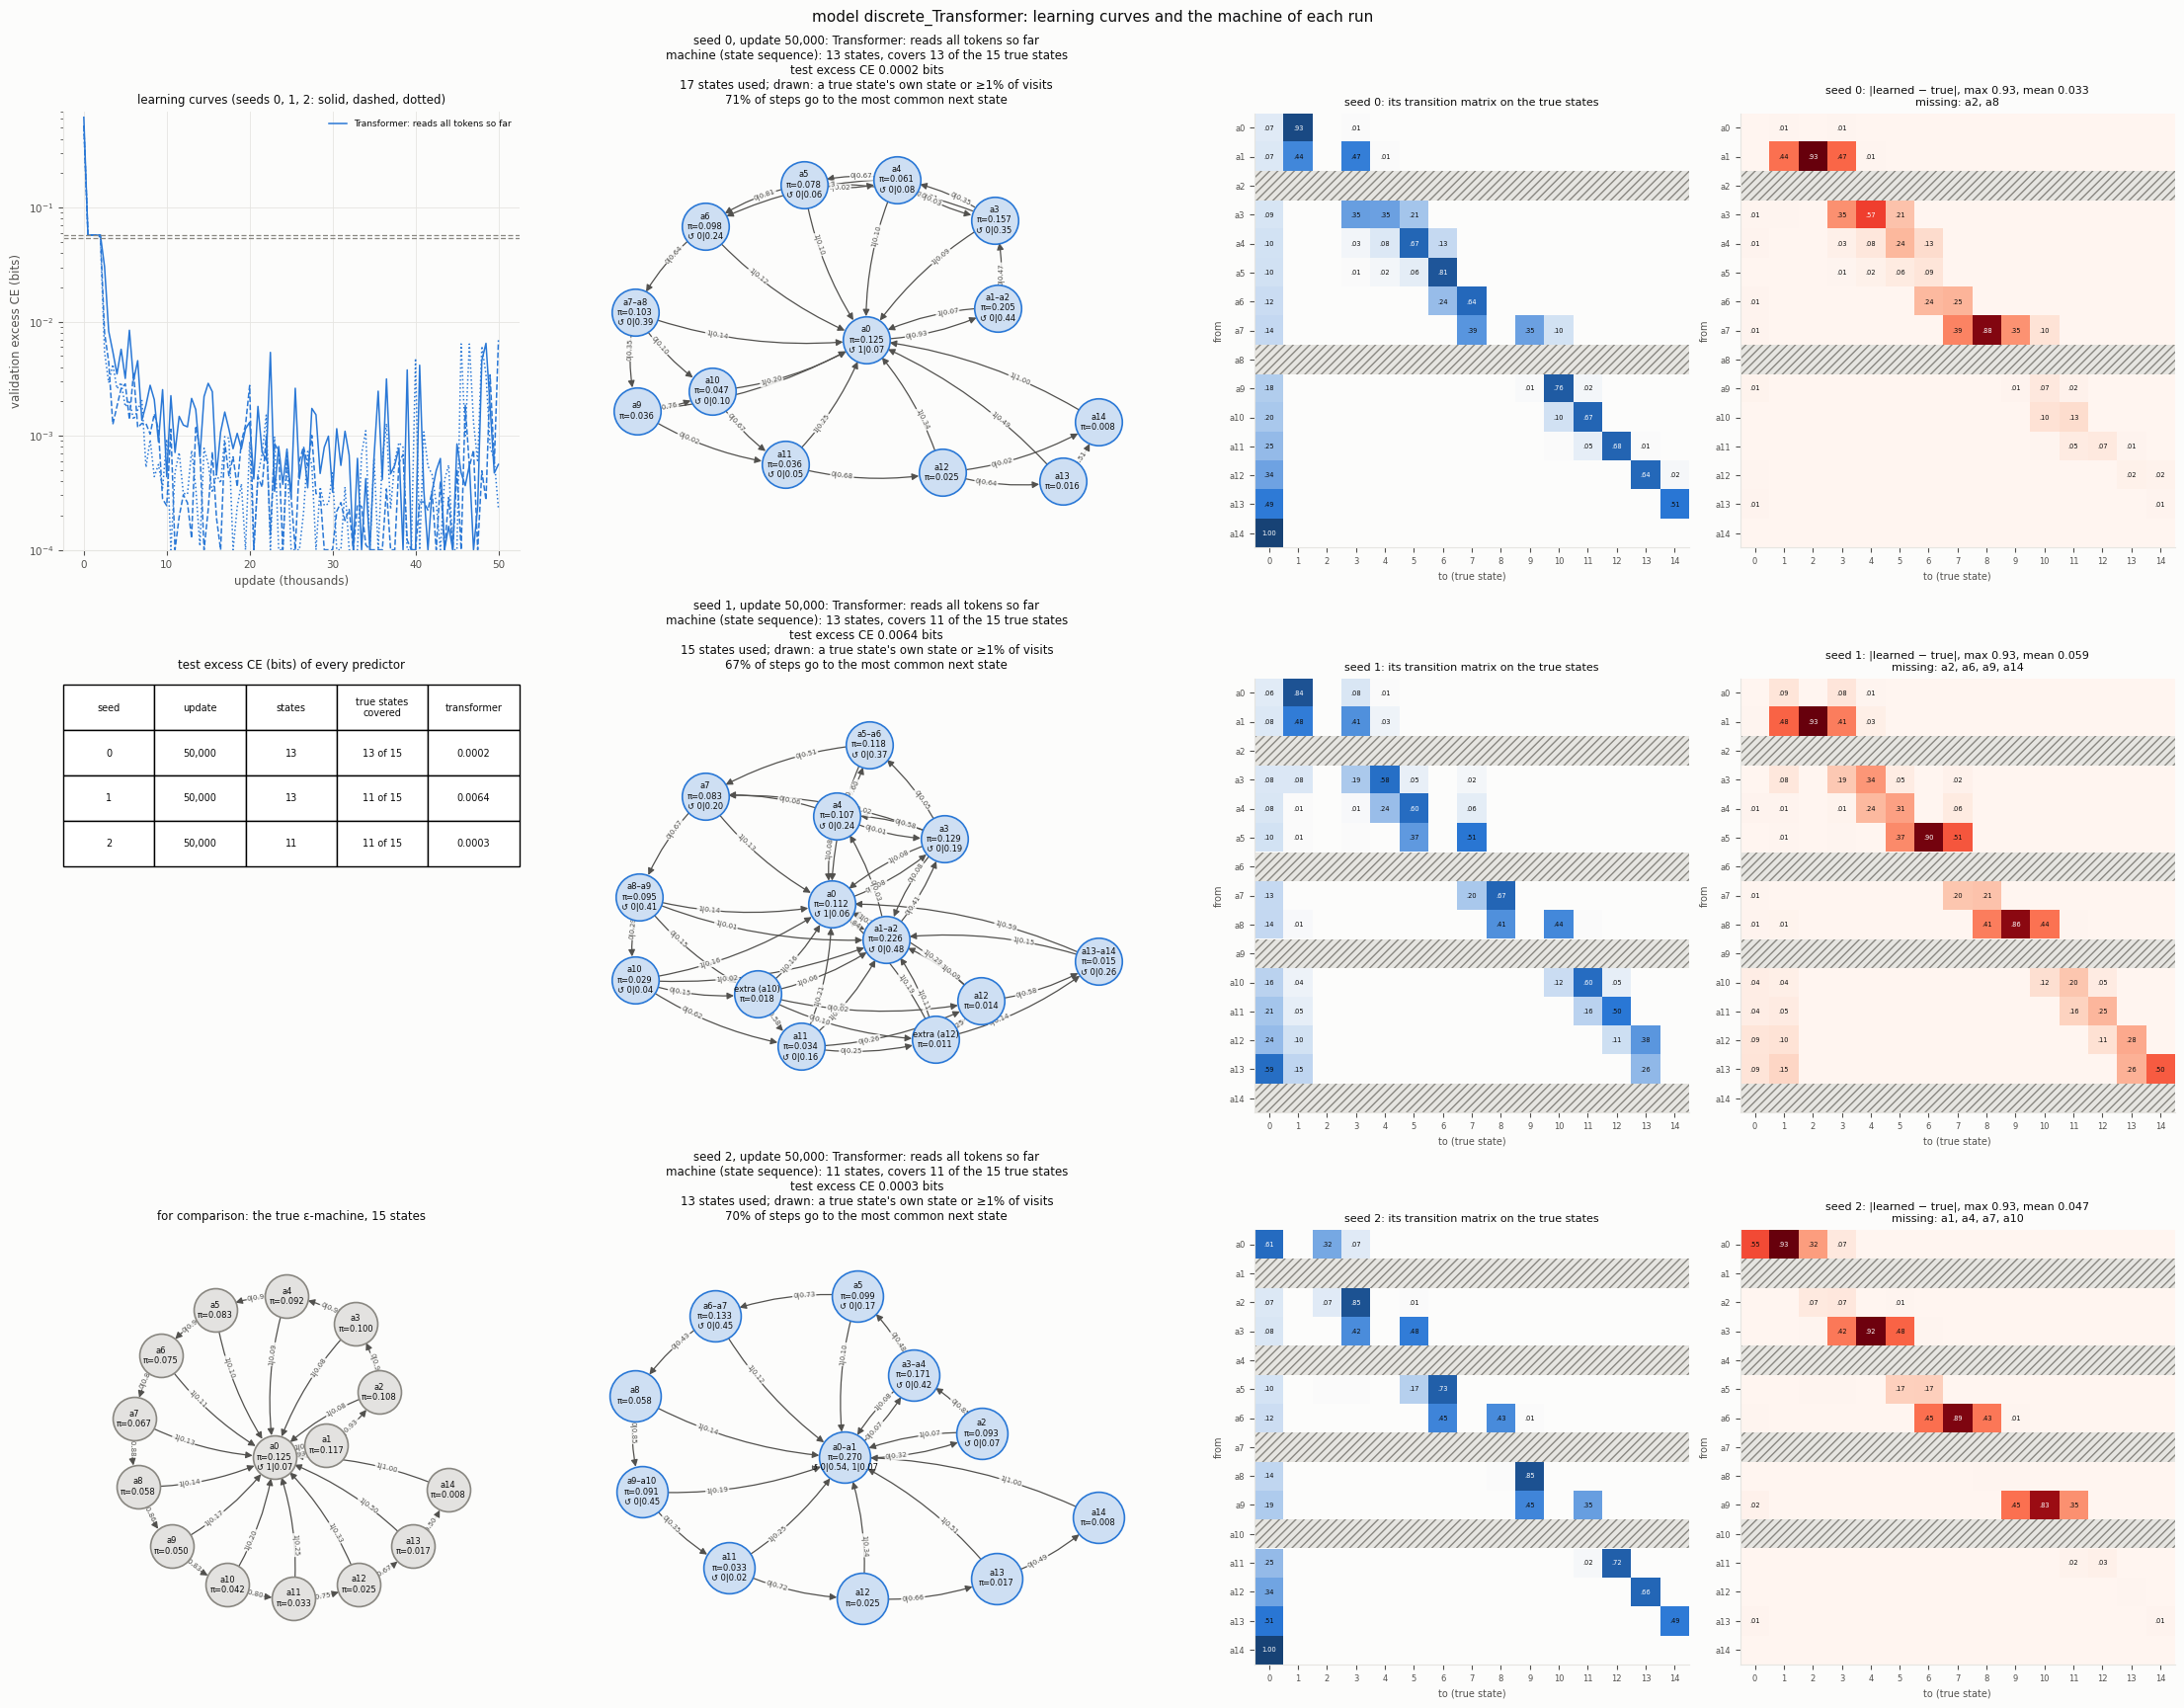

In [20]:
r = runs_of("discrete_Transformer", "section17")
display(performance(r))
display(A.first_below(r).set_index("seed")[["final_update", "best", "best_update", "below 0.04", "below 0.02", "below 0.01"]])
fig = A.plot_machines(list(r.values())); plt.show()

**What the runs show**
* **Its predictions** are at 0.0002, 0.0064 and 0.0003 bits. They first fell below 0.01 bits at updates 2,500–3,000.
* **Its machine has 13, 13 and 11 states**, covering 13, 11 and 11 true states. Its transitions differ from the true
  ones by 0.0330, 0.0595 and 0.0468 on average.

### 6.14 Across the models

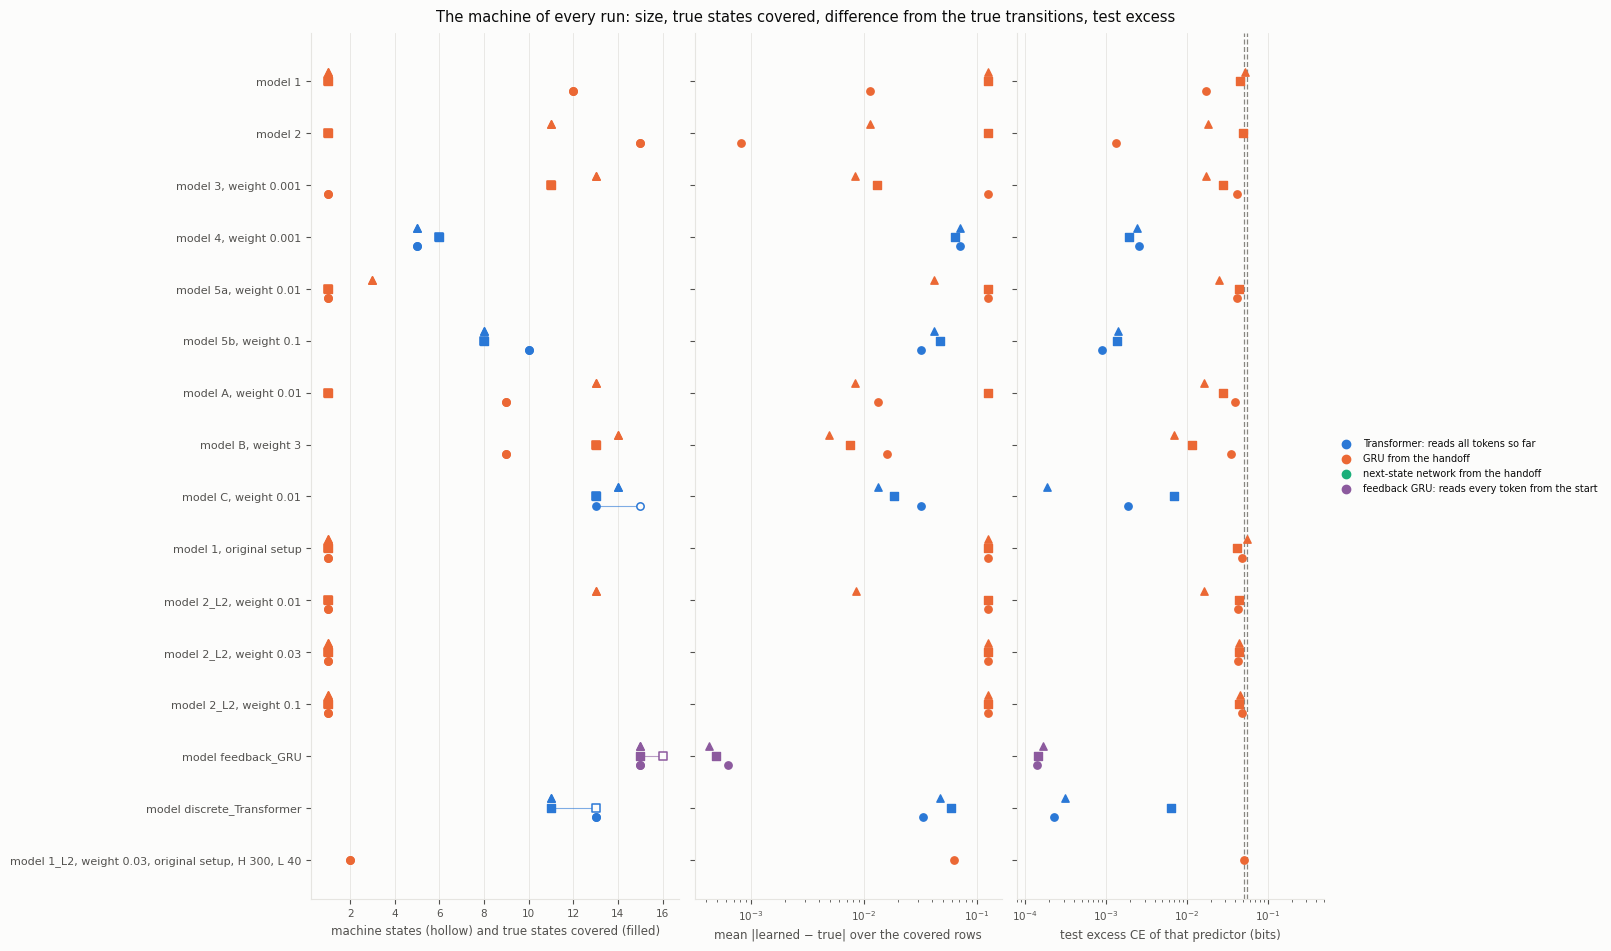

In [21]:
everything = {k: f for k, f in runs.items()}
fig = A.plot_machine_summary(A.machine_table(everything), levels); plt.show()

* **Only two runs end with a machine covering all 15 true states at under 0.002 bits:**
  * model 2, seed 0 (the hybrid's GRU);
  * the feedback GRU alone, on all three seeds.
* **The hybrid's GRU learns the counts on some seeds only.** Ending machines with at least 11 long-run states:
  * model 1: seed 0;
  * model 2: seeds 0 and 2;
  * model 3: seeds 1 and 2;
  * model A: seed 2;
  * model B: seeds 1 and 2;
  * model 2 + L2 at weight 0.01: seed 2.
* **The Transformer-only models predict well but merge the early counts.**
  * Test excess: 0.0002–0.0070 bits.
  * True states covered: model 4, 5–6; model 5b, 8–10; model C, 13–14; the discrete Transformer, 11–13.
* **The terms that pull the two parts together** (D in models 1 + L2 and 2 + L2) make the GRU follow the Transformer.
  They leave the GRU's own machine at a single state, except at the smallest weight on one seed.

## References

* Chen, X. & He, K. (2021). Exploring Simple Siamese Representation Learning. CVPR 2021. arXiv:2011.10566.
* Gloeckle, F. et al. (2024). Better & Faster Large Language Models via Multi-token Prediction. ICML 2024. arXiv:2404.19737.
* Hinton, G., Vinyals, O. & Dean, J. (2015). Distilling the Knowledge in a Neural Network. arXiv:1503.02531.
* Jang, E., Gu, S. & Poole, B. (2017). Categorical Reparameterization with Gumbel-Softmax. ICLR 2017. arXiv:1611.01144.
* Mahoney, J. R., Ellison, C. J. & Crutchfield, J. P. (2009). Information Accessibility and Cryptic Processes. arXiv:0905.4787.
* Marzen, S. E. & Crutchfield, J. P. (2015). Informational and Causal Architecture of Discrete-Time Renewal Processes.
  Entropy 17(7), 4891–4917. arXiv:1408.6876.
* Shalizi, C. R. & Crutchfield, J. P. (2001). Computational Mechanics: Pattern and Prediction, Structure and Simplicity.
  Journal of Statistical Physics 104, 817–879.
* Tang, Y. et al. (2023). Understanding Self-Predictive Learning for Reinforcement Learning. ICML 2023. arXiv:2212.03319.